Pada tahap sebelumnya, telah dilakukan pengolahan data dan eksperimen pemodelan menggunakan **dataset SYNOP (Ogimet)** untuk mengklasifikasikan fenomena cuaca di Stasiun Meteorologi Kelas I Sultan Thaha Jambi dengan pendekatan *machine learning* berbasis pohon keputusan (*tree-based models*).

Sebagai **implementasi lanjutan**, *notebook* ini menerapkan pendekatan klasifikasi fenomena cuaca yang sama menggunakan **dataset observasi resmi dari BMKG**. Penggunaan data resmi ini bertujuan untuk menguji serta mengevaluasi performa model berbasis pohon keputusan secara langsung pada data pencatatan internal stasiun.

### Data Source & Acquisition

The dataset used in this notebook is sourced directly from the official surface weather observation records of **BMKG (Stasiun Meteorologi Kelas I Sultan Thaha Jambi)**, serving as a continuation of the previous experiment that utilized external Ogimet SYNOP archives. The records are organized into tabular meteorological variables following BMKG's standard observation format and are ready to be loaded and preprocessed in this notebook.

- **Station:** Sultan Thaha Meteorological Station, Jambi (WMO ID: 96195 | ICAO: WIJJ)
- **Period:** January 1 - December 31, 2025
- **Resolution:** Hourly surface observations
- **Raw Format:** Official BMKG observation dataset stored as `CSV`

# 1. Data Loading and Inspection

Tahap ini diawali dengan memuat data observasi resmi Stasiun Meteorologi Sultan Thaha Jambi periode Januari–Desember 2025. Data tersebut digunakan sebagai dataset utama dalam penerapan model *machine learning* berbasis pohon keputusan untuk klasifikasi fenomena cuaca. Pemeriksaan awal dilakukan untuk memahami struktur dan karakteristik dataset, meliputi jumlah baris dan kolom, tipe data setiap variabel, keberadaan missing value, konsistensi interval waktu pencatatan, serta distribusi dan rentang nilai setiap variabel. Hasil pemeriksaan ini menjadi dasar untuk menentukan langkah pengolahan data pada tahap selanjutnya.

## 1.1 Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import os

from scipy.stats import kruskal, randint, uniform, loguniform
from sklearn.model_selection import StratifiedGroupKFold, RandomizedSearchCV, cross_val_predict
from sklearn.utils.class_weight import compute_class_weight
from sklearn.dummy import DummyClassifier
from sklearn.metrics import classification_report, confusion_matrix, f1_score, make_scorer, ConfusionMatrixDisplay, precision_recall_fscore_support, balanced_accuracy_score, accuracy_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from sklearn.base import clone, BaseEstimator, ClassifierMixin
from sklearn.inspection import permutation_importance

## 1.2 Load Dataset

Dataset dimuat dari file CSV yang berisi data observasi Stasiun Meteorologi Sultan Thaha Jambi periode Januari–Desember 2025. Dataset ini akan digunakan sebagai sumber data utama dalam proses klasifikasi fenomena cuaca.

In [2]:
data_df = pd.read_csv('../bmkg-dataset/bmkg-jambi-25.csv', sep=None, engine='python')

In [3]:
with pd.option_context('display.max_columns', None, 'display.max_colwidth', None):
    display(data_df.head())

,station_name,data_timestamp,wind_indicator_iw,wind_dir_deg_dd,wind_speed_ff,visibility_vv,weather_indicator_ix,present_weather_ww,past_weather_w1,past_weather_w2,pressure_temp_c,pressure_reading_mb,pressure_qfe_mb_derived,pressure_qff_mb_derived,pressure_3h_diff_mb_ppp,pressure_24h_diff_mb_p24,temp_drybulb_c_tttttt,temp_dewpoint_c_tdtdtd,temp_wetbulb_c,temp_max_c_txtxtx,temp_min_c_tntntn,relative_humidity_pc,rainfall_last_mm,rainfall_24h_rrrr,rainfall_6h_rrr,rainfall_indicator_ir,cloud_low_type_cl,cloud_low_cover_oktas,cloud_low_type_1,cloud_low_type_2,cloud_low_type_3,cloud_low_cover_1,cloud_low_cover_2,cloud_low_cover_3,cloud_low_base_1,cloud_low_base_2,cloud_low_base_3,cloud_low_peak_1,cloud_low_peak_2,cloud_low_dir_1,cloud_low_dir_2,cloud_low_dir_3,cloud_elevation_angle_ec_1,cloud_elevation_angle_ec_2,cloud_low_dir_true_da_1,cloud_low_dir_true_da_2,cloud_layer_1_type_c,cloud_layer_2_type_c,cloud_layer_1_height_m_hshs,cloud_layer_2_height_m_hshs,cloud_layer_1_amt_oktas_ns,cloud_layer_2_amt_oktas_ns,cloud_layer_3_type_c,cloud_layer_3_height_m_hshs,cloud_layer_3_amt_oktas_ns,cloud_layer_4_type_c,cloud_layer_4_height_m_hshs,cloud_layer_4_amt_oktas_ns,cloud_med_type_cm,cloud_med_cover_oktas,cloud_med_type_1,cloud_med_type_2,cloud_med_cover_1,cloud_med_cover_2,cloud_med_base_1,cloud_med_base_2,cloud_med_dir_1,cloud_med_dir_2,cloud_high_type_ch,cloud_high_cover_oktas,cloud_high_type_1,cloud_high_type_2,cloud_high_cover_1,cloud_high_cover_2,cloud_high_base_1,cloud_high_base_2,cloud_high_dir_1,cloud_high_dir_2,created_at,updated_at,qc_flag,qc_histories
0,Stasiun Meteorologi Sultan Thaha,01/01/2025 00:00,4,300,5,7.0,1,5,2,2,NaN,NaN,1006.8,1009.8,1.4,-1.1,25.8,24.8,25.1,NaN,24.7,95,0.0,0.0,0.0,3,5,3,6,NaN,NaN,3,NaN,NaN,480.0,NaN,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN,6.0,4.0,480.0,3000.0,3.0,3.0,NaN,NaN,NaN,NaN,NaN,NaN,2,3,4,3.0,2,1.0,3000.0,3000.0,0,0.0,1,1,0,NaN,1,NaN,9000.0,NaN,0,NaN,31/12/2025 08:14,31/12/2025 08:14,0,NaN
1,Stasiun Meteorologi Sultan Thaha,01/01/2025 01:00,4,310,9,10.0,2,2,2,2,NaN,NaN,1007.6,1010.6,NaN,NaN,26.7,24.8,25.3,NaN,NaN,89,NaN,NaN,NaN,4,5,4,6,NaN,NaN,4,NaN,NaN,450.0,NaN,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN,6.0,4.0,450.0,3000.0,4.0,4.0,NaN,NaN,NaN,NaN,NaN,NaN,2,4,4,NaN,4,NaN,3000.0,NaN,0,NaN,1,1,0,NaN,1,NaN,9000.0,NaN,0,NaN,31/12/2025 08:14,31/12/2025 08:14,0,NaN
2,Stasiun Meteorologi Sultan Thaha,01/01/2025 02:00,4,310,8,10.0,2,1,2,2,NaN,NaN,1008.0,1011.0,NaN,NaN,28.0,24.8,25.6,NaN,NaN,83,NaN,NaN,NaN,4,2,3,8,NaN,NaN,3,NaN,NaN,450.0,NaN,NaN,1500.0,NaN,0,NaN,NaN,2.0,NaN,0.0,NaN,8.0,3.0,450.0,3000.0,3.0,3.0,NaN,NaN,NaN,NaN,NaN,NaN,3,3,3,NaN,3,NaN,3000.0,NaN,0,NaN,1,1,0,NaN,1,NaN,9000.0,NaN,0,NaN,31/12/2025 08:14,31/12/2025 08:14,0,NaN
3,Stasiun Meteorologi Sultan Thaha,01/01/2025 03:00,4,350,10,10.0,2,2,2,2,NaN,NaN,1007.9,1010.9,1.1,NaN,29.5,24.5,25.8,NaN,NaN,75,0.0,NaN,NaN,3,2,4,8,NaN,NaN,4,NaN,NaN,450.0,NaN,NaN,1500.0,NaN,0,NaN,NaN,2.0,NaN,0.0,NaN,8.0,NaN,450.0,NaN,4.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3,2,3,NaN,2,NaN,3000.0,NaN,0,NaN,1,1,0,NaN,1,NaN,9000.0,NaN,0,NaN,31/12/2025 08:14,31/12/2025 08:14,0,NaN
4,Stasiun Meteorologi Sultan Thaha,01/01/2025 04:00,4,330,10,10.0,2,2,2,2,NaN,NaN,1007.3,1010.3,NaN,NaN,30.6,24.4,26.0,NaN,NaN,69,NaN,NaN,NaN,4,2,4,8,NaN,NaN,4,NaN,NaN,510.0,NaN,NaN,1500.0,NaN,0,NaN,NaN,2.0,NaN,0.0,NaN,8.0,NaN,510.0,NaN,4.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3,2,3,NaN,2,NaN,3000.0,NaN,0,NaN,1,1,0,NaN,1,NaN,9000.0,NaN,0,NaN,31/12/2025 08:14,31/12/2025 08:14,0,NaN


## 1.3 Check Data Structure

Pemeriksaan awal dilakukan untuk mengetahui dimensi dataset, meliputi jumlah baris dan kolom, serta tipe data pada masing-masing kolom. Informasi ini digunakan untuk memahami struktur dataset dan mengidentifikasi variabel yang memerlukan penyesuaian tipe data sebelum proses pengolahan lebih lanjut.

In [4]:
data_df.shape

(8760, 82)

In [5]:
print(data_df.dtypes.to_string())

station_name                       str
data_timestamp                     str
wind_indicator_iw                int64
wind_dir_deg_dd                  int64
wind_speed_ff                    int64
visibility_vv                  float64
weather_indicator_ix             int64
present_weather_ww               int64
past_weather_w1                  int64
past_weather_w2                  int64
pressure_temp_c                float64
pressure_reading_mb            float64
pressure_qfe_mb_derived        float64
pressure_qff_mb_derived        float64
pressure_3h_diff_mb_ppp        float64
pressure_24h_diff_mb_p24       float64
temp_drybulb_c_tttttt          float64
temp_dewpoint_c_tdtdtd         float64
temp_wetbulb_c                 float64
temp_max_c_txtxtx              float64
temp_min_c_tntntn              float64
relative_humidity_pc             int64
rainfall_last_mm               float64
rainfall_24h_rrrr              float64
rainfall_6h_rrr                float64
rainfall_indicator_ir    

In [6]:
data_df['weather_indicator_ix'].value_counts()

weather_indicator_ix
1    4777
2    3983
Name: count, dtype: int64

In [7]:
data_df['present_weather_ww'].value_counts().sort_index()

present_weather_ww
0        1
1      420
2     3373
3      390
5     2726
6        2
10     448
13      54
15       3
16       4
17      63
21     378
28       6
29      38
40       6
41      13
42       9
44       8
45       2
46       5
47       1
50       1
51       1
60     255
61     354
62       8
63      20
64       3
65       1
91      53
95     113
97       1
Name: count, dtype: int64

In [8]:
data_df['present_weather_ww'].isna().sum()

np.int64(0)

**Notes:**

- Dataset terdiri dari **8.760 baris dan 82 kolom**, yang merepresentasikan pencatatan observasi per jam selama satu tahun penuh pada tahun 2025 ($365 \text{ hari} \times 24 \text{ jam}$).
- Kolom `data_timestamp` masih terbaca sebagai tipe `str` (string), sehingga perlu dikonversi ke format `datetime64` untuk memastikan urutan kronologis dan ekstraksi fitur waktu (jam dan bulan).
- Sebagian besar parameter meteorologi utama (suhu, tekanan, kelembapan, angin, dan jarak pandang) sudah bertipe numerik (`int64` dan `float64`), namun beberapa variabel jenis dan tutupan awan (`cloud_low_*`, `cloud_med_*`, `cloud_high_*`) masih terbaca sebagai `str` sehingga perlu diperiksa isi karakternya sebelum dikonversi ke numerik.
- Variabel `present_weather_ww` terisi lengkap (0 *missing value*) dengan nilai `weather_indicator_ix` hanya terdiri dari kode `1` (4.777 baris) dan `2` (3.983 baris), yang menandakan pencatatan kondisi cuaca tersedia di seluruh jam observasi.

## 1.4 Check Missing Values

Pemeriksaan *missing values* dilakukan untuk mengetahui jumlah data yang kosong pada setiap variabel. Pemeriksaan ini bertujuan untuk mengevaluasi kelengkapan data serta mengidentifikasi variabel yang memerlukan penanganan (seperti penghapusan kolom atau imputasi) pada tahap *preprocessing*. Perhatian khusus diberikan pada variabel `present_weather_ww` dan `weather_indicator_ix` karena keduanya menjadi acuan utama dalam pembentukan label target klasifikasi fenomena cuaca, serta variabel meteorologi permukaan utama.

In [9]:
missing_count = data_df.isna().sum()
missing_df = pd.DataFrame({
    'Missing Count': missing_count[missing_count > 0],
    'Missing (%)': (missing_count[missing_count > 0] / len(data_df) * 100).round(2)
}).sort_values(by='Missing Count', ascending=False)

print(f"Total kolom dengan missing value: {len(missing_df)} dari {data_df.shape[1]} kolom")
with pd.option_context('display.max_rows', None):
    display(missing_df)

Total kolom dengan missing value: 49 dari 82 kolom


,Missing Count,Missing (%)
pressure_temp_c,8760,100.00
pressure_reading_mb,8760,100.00
cloud_layer_4_type_c,8760,100.00
cloud_layer_4_amt_oktas_ns,8760,100.00
cloud_layer_4_height_m_hshs,8760,100.00
cloud_high_base_2,8760,100.00
cloud_high_dir_2,8760,100.00
cloud_high_type_2,8760,100.00
cloud_high_cover_2,8760,100.00
qc_histories,8756,99.95


**Notes:**

- **Variabel Target & Fitur Utama Lengkap (0 *missing value*):** Kolom `present_weather_ww` dan `weather_indicator_ix` tidak memiliki *missing value* (`0`), sehingga seluruh 8.760 baris observasi dapat diberikan label kelas fenomena cuaca secara utuh. Parameter permukaan utama seperti `visibility_vv`, `temp_drybulb_c_tttttt`, `temp_dewpoint_c_tdtdtd`, `temp_wetbulb_c`, `relative_humidity_pc`, `pressure_qfe_mb_derived`, `pressure_qff_mb_derived`, `wind_dir_deg_dd`, dan `wind_speed_ff` juga terisi 100%.
- **Kolom Kosong Total (100% / 8.760 `NaN`):** Terdapat 9 kolom yang seluruh barisnya kosong dan tidak mengandung informasi (`pressure_temp_c`, `pressure_reading_mb`, `cloud_layer_4_type_c`, `cloud_layer_4_height_m_hshs`, `cloud_layer_4_amt_oktas_ns`, `cloud_high_type_2`, `cloud_high_cover_2`, `cloud_high_base_2`, dan `cloud_high_dir_2`), sehingga dapat langsung dihapus (*drop*).
- **Missing Value Sistematis (Interval Pelaporan):** Variabel yang hanya dicatat pada jam sinoptik tertentu (per 3, 6, 12, atau 24 jam) memiliki proporsi kosong yang tinggi, seperti `temp_max_c_txtxtx` (8.395), `temp_min_c_tntntn` (8.395), `rainfall_24h_rrrr` (8.395), `pressure_24h_diff_mb_p24` (8.030), `rainfall_6h_rrr` (7.300), `pressure_3h_diff_mb_ppp` (5.840), dan `rainfall_last_mm` (5.840).
- **Detail Lapisan & Jenis Awan Tambahan:** Kolom rincian awan ke-2 dan ke-3 (`*_2`, `*_3`), lapisan awan ke-3 (`cloud_layer_3_*`), serta sudut elevasi/puncak awan (`cloud_low_peak_*`, `cloud_elevation_angle_*`) memiliki banyak nilai `NaN` karena pencatatannya hanya muncul apabila lapisan awan tambahan tersebut teramati.

## 1.5 Check Time Range and Interval Consistency

Kolom `data_timestamp` dikonversi ke format datetime agar rentang waktu pengamatan dan selisih waktu antarbaris dapat diperiksa. Pemeriksaan ini bertujuan untuk mengetahui konsistensi interval pencatatan data serta mengidentifikasi kemungkinan adanya lompatan waktu atau duplikasi timestamp.

In [10]:
temp_date = pd.to_datetime(data_df['data_timestamp'], format='%d/%m/%Y %H:%M', errors='coerce')

In [11]:
print(f"Jumlah gagal parsing (NaT) : {temp_date.isna().sum()}")
print(f"Jumlah duplikat timestamp  : {temp_date.duplicated().sum()}")
print(f"Rentang waktu observasi    : {temp_date.min()} s.d. {temp_date.max()}")

Jumlah gagal parsing (NaT) : 0
Jumlah duplikat timestamp  : 0
Rentang waktu observasi    : 2025-01-01 00:00:00 s.d. 2025-12-31 23:00:00


In [12]:
temp_date_sorted = temp_date.sort_values().reset_index(drop=True)
interval = temp_date_sorted.diff()

In [13]:
print("Distribusi interval waktu antarbaris:")
print(interval.value_counts())

Distribusi interval waktu antarbaris:
data_timestamp
0 days 01:00:00    8759
Name: count, dtype: int64


In [14]:
gaps = temp_date_sorted[interval.notna() & (interval != pd.Timedelta(hours=1))]
print(f"Jumlah lompatan waktu (bukan 1 jam): {len(gaps)}")

Jumlah lompatan waktu (bukan 1 jam): 0


**Notes:**

- Setelah dikonversi menggunakan format `%d/%m/%Y %H:%M`, seluruh **8.760 baris** berhasil terbaca tanpa nilai kosong (`0 NaT`) dan tanpa duplikasi *timestamp* (`0` duplikat).
- Rentang waktu pengamatan mencakup satu tahun penuh secara utuh, dimulai dari **`2025-01-01 00:00:00`** hingga **`2025-12-31 23:00:00`** (waktu UTC).
- Seluruh selisih waktu antarbaris bernilai tepat **`0 days 01:00:00` (1 jam)** sebanyak 8.759 interval tanpa adanya lompatan waktu (*time gap*), sehingga deret waktu observasi dinyatakan lengkap dan konsisten per jam.

## 1.6 Check Low Cloud Cover Consistency and Non-Numeric Values

Pemeriksaan dilakukan pada variabel tutupan awan rendah (`cloud_low_cover_oktas` dan `cloud_low_cover_1`) untuk mengidentifikasi keberadaan karakter non-numerik yang menyebabkan kolom tersebut terbaca sebagai tipe `str`. Selain itu, dilakukan verifikasi kesesuaian nilai antara `cloud_low_cover_oktas` dengan hasil penjumlahan lapisan awan rendah (`cloud_low_cover_1`, `cloud_low_cover_2`, dan `cloud_low_cover_3`) guna memastikan konsistensi variabel sebelum digunakan sebagai fitur pada tahap *preprocessing*.

In [15]:
for col in ['cloud_low_cover_oktas', 'cloud_low_cover_1']:
    print(f"=== {col} ===")
    print(data_df[col].value_counts(dropna=False).sort_index(), "\n")

=== cloud_low_cover_oktas ===
cloud_low_cover_oktas
/       1
0     193
1     612
2    1540
3    2526
4    1681
5    1498
6     499
7     105
8     102
9       3
Name: count, dtype: int64 

=== cloud_low_cover_1 ===
cloud_low_cover_1
/       1
0     194
1    1178
2    1647
3    2543
4    1533
5    1244
6     265
7      60
8      92
9       3
Name: count, dtype: int64 



In [16]:
low_total = pd.to_numeric(data_df['cloud_low_cover_oktas'], errors='coerce')
c1 = pd.to_numeric(data_df['cloud_low_cover_1'], errors='coerce').fillna(0)
c2 = data_df['cloud_low_cover_2'].fillna(0)
c3 = data_df['cloud_low_cover_3'].fillna(0)

In [17]:
sum_layers = c1 + c2 + c3

In [18]:
check_df = pd.DataFrame({
    'cloud_low_cover_oktas': data_df['cloud_low_cover_oktas'],
    'cover_1': data_df['cloud_low_cover_1'],
    'cover_2': data_df['cloud_low_cover_2'],
    'cover_3': data_df['cloud_low_cover_3'],
    'sum_1_2_3': sum_layers
})

In [19]:
diff_mask = low_total.notna() & (low_total != sum_layers)

In [20]:
print(f"Jumlah baris valid yang sama persis      : {(low_total == sum_layers).sum()}")
print(f"Jumlah baris valid yang berbeda         : {diff_mask.sum()}")
print(f"Jumlah baris non-numerik (simbol / NaN) : {low_total.isna().sum()}")

Jumlah baris valid yang sama persis      : 8631
Jumlah baris valid yang berbeda         : 128
Jumlah baris non-numerik (simbol / NaN) : 1


In [21]:
if diff_mask.sum() > 0:
    print("Contoh baris yang berbeda:")
    display(check_df[diff_mask].head(10))

Contoh baris yang berbeda:


,cloud_low_cover_oktas,cover_1,cover_2,cover_3,sum_1_2_3
10,3,5,NaN,NaN,5.0
112,1,1,4.0,NaN,5.0
298,5,8,NaN,NaN,8.0
375,3,5,NaN,NaN,5.0
405,7,6,NaN,NaN,6.0
624,3,2,NaN,NaN,2.0
642,4,8,NaN,NaN,8.0
671,8,6,NaN,NaN,6.0
854,5,4,NaN,NaN,4.0
1105,2,1,2.0,NaN,3.0


In [22]:
if low_total.isna().sum() > 0:
    print("Contoh baris non-numerik:")
    display(check_df[low_total.isna()].head(10))

Contoh baris non-numerik:


,cloud_low_cover_oktas,cover_1,cover_2,cover_3,sum_1_2_3
3768,/,/,NaN,NaN,0.0


**Notes:**

- **Penyebab Tipe Data `str`:** Ditemukan tepat **1 baris** dengan karakter non-numerik `'/'` pada indeks `3768` (`cloud_low_cover_oktas = '/'` dan `cloud_low_cover_1 = '/'`), yang dalam sandi meteorologi menandakan tutupan awan rendah tidak dapat diamati/ditentukan. Nilai ini perlu diubah menjadi `NaN` sebelum kolom dikonversi ke numerik pada tahap *preprocessing*.
- **Perbandingan dengan Penjumlahan Lapisan (`cover_1 + cover_2 + cover_3`):** Dari total 8.759 baris numerik, sebanyak **8.631 baris (98,54%)** memiliki nilai yang sama persis, sementara **128 baris (1,46%)** berbeda. Perbedaan ini wajar secara pengamatan meteorologi karena `cloud_low_cover_oktas` ($N_h$) menyatakan tutupan langit gabungan dari seluruh awan rendah (memperhitungkan lapisan yang saling bertumpuk), bukan sekadar penjumlahan aritmetika tiap lapisan.
- **Keputusan Fitur:** Variabel `cloud_low_cover_oktas` dipilih sebagai representasi tunggal tutupan awan rendah karena sudah merangkum kondisi keseluruhan dan hanya memerlukan penanganan 1 nilai `'/'`.

## 1.7 Check Value Range (Min/Max) and Physical Consistency

Pemeriksaan nilai minimum, median, dan maksimum dilakukan pada seluruh variabel numerik yang memiliki data untuk mengevaluasi rentang nilai serta mendeteksi potensi anomali atau nilai sandi khusus (seperti arah angin variabel `990`). Selain itu, dilakukan pemeriksaan konsistensi fisik antarparameter meteorologi (hubungan suhu bola kering dengan titik embun, perbandingan tekanan QFE dan QFF, serta status `qc_flag`) guna memastikan validitas data sebelum masuk ke tahap *preprocessing*.

**Ringkasan rentang nilai variabel numerik (mengecualikan kolom yang 100% kosong)**

In [23]:
valid_numeric = data_df.select_dtypes(include='number').dropna(axis=1, how='all')

with pd.option_context('display.max_rows', None):
    display(valid_numeric.describe().T[['count', 'min', '50%', 'max']])

,count,min,50%,max
wind_indicator_iw,8760.0,3.0,4.0,4.0
wind_dir_deg_dd,8760.0,0.0,170.0,360.0
wind_speed_ff,8760.0,0.0,3.0,25.0
visibility_vv,8760.0,0.1,8.0,12.3
weather_indicator_ix,8760.0,1.0,1.0,2.0
present_weather_ww,8760.0,0.0,5.0,97.0
past_weather_w1,8760.0,0.0,2.0,9.0
past_weather_w2,8760.0,0.0,2.0,9.0
pressure_qfe_mb_derived,8760.0,999.2,1006.5,1012.2
pressure_qff_mb_derived,8760.0,1002.2,1009.5,1015.2


**Cek kewajaran fisik & kode khusus meteorologi**

In [24]:
print("Arah angin > 360° (kode variabel 990) :", (data_df['wind_dir_deg_dd'] > 360).sum())
print("Suhu titik embun > suhu bola kering  :", (data_df['temp_dewpoint_c_tdtdtd'] > data_df['temp_drybulb_c_tttttt']).sum())
print("Tekanan QFE >= Tekanan QFF           :", (data_df['pressure_qfe_mb_derived'] >= data_df['pressure_qff_mb_derived']).sum())

print("\nDistribusi qc_flag:")
print(data_df['qc_flag'].value_counts(dropna=False))

Arah angin > 360° (kode variabel 990) : 0
Suhu titik embun > suhu bola kering  : 0
Tekanan QFE >= Tekanan QFF           : 1

Distribusi qc_flag:
qc_flag
0    8756
1       4
Name: count, dtype: int64


**Notes:**

- **Sandi Khusus Curah Hujan (`8888.0`):** Variabel `rainfall_last_mm`, `rainfall_6h_rrr`, dan `rainfall_24h_rrrr` memiliki nilai maksimum **`8888.0`**. Dalam standar pencatatan BMKG, angka `8888` merupakan kode khusus untuk curah hujan sangat kecil (*trace* / tidak terukur, $< 0,1\text{ mm}$), bukan nilai hujan sebenarnya, sehingga wajib dikonversi (misalnya menjadi `0.0` atau `0.05`) pada tahap *preprocessing*.
- **Konsistensi Satuan & Arah Angin:** Variabel `wind_indicator_iw` hanya bernilai `3` dan `4`, yang menandakan seluruh `wind_speed_ff` (`0`–`25` knot) tercatat dalam satuan **knot** secara konsisten. Arah angin (`wind_dir_deg_dd`) berada pada rentang wajar `0°`–`360°` tanpa kode angin variabel (`990`).
- **Kewajaran Suhu & Kelembapan:** Suhu bola kering (`21,6°C`–`35,2°C`), titik embun (`19,4°C`–`26,8°C`), suhu bola basah (`20,9°C`–`27,8°C`), dan kelembapan relatif (`42%`–`100%`) berada dalam rentang iklim tropis yang wajar, serta tidak ditemukan satu pun kondisi tidak valid di mana titik embun melebihi suhu bola kering (`0` baris).
- **Anomali Minor Tekanan & Status QC:** Selisih median antara `pressure_qff_mb_derived` (`1009,5 mb`) dan `pressure_qfe_mb_derived` (`1006,5 mb`) konsisten sebesar `3,0 mb` sesuai elevasi Stasiun Sultan Thaha, namun ditemukan **1 baris** di mana `QFE >= QFF` serta **4 baris** dengan `qc_flag = 1` yang perlu diperiksa lebih lanjut pada tahap *Data Cleaning*.
- **Jarak Pandang & Sandi Cuaca:** Variabel `visibility_vv` memiliki rentang `0,1 km` hingga `12,3 km` (median `8,0 km`), sedangkan `present_weather_ww` berada pada rentang sandi `0` hingga `97`.

## 1.8 Check Unique Value Distribution and Anomaly Inspection

Pemeriksaan distribusi nilai unik dilakukan pada variabel tertentu—meliputi indikator dan curah hujan (`rainfall_*`), jarak pandang (`visibility_vv`), serta sandi cuaca (`present_weather_ww`)—untuk memahami pola pencatatan dan frekuensi kemunculan tiap nilai. Selain itu, dilakukan penelusuran langsung pada baris data yang terindikasi ekstrem atau anomali pada tahap sebelumnya (seperti nilai ekstrem *visibility*, kondisi `QFE >= QFF`, dan baris dengan `qc_flag = 1`) guna menentukan penanganan yang sesuai pada tahap *preprocessing*.

**Distribusi indikator hujan dan frekuensi kode khusus 8888.0 (trace)**

In [25]:
print("=== Distribusi rainfall_indicator_ir ===")
print(data_df['rainfall_indicator_ir'].value_counts(dropna=False).sort_index(), "\n")

rain_cols = ['rainfall_last_mm', 'rainfall_6h_rrr', 'rainfall_24h_rrrr']
for col in rain_cols:
    trace_count = (data_df[col] == 8888.0).sum()
    zero_count = (data_df[col] == 0.0).sum()
    valid_rain = ((data_df[col] > 0.0) & (data_df[col] < 8888.0)).sum()
    print(f"{col:<20} -> 0 mm: {zero_count:4d} | Trace (8888): {trace_count:3d} | Hujan terukur (>0): {valid_rain:3d}")

=== Distribusi rainfall_indicator_ir ===
rainfall_indicator_ir
0     318
1     233
2     299
3    2070
4    5840
Name: count, dtype: int64 

rainfall_last_mm     -> 0 mm: 2303 | Trace (8888): 158 | Hujan terukur (>0): 459
rainfall_6h_rrr      -> 0 mm: 1021 | Trace (8888):  97 | Hujan terukur (>0): 342
rainfall_24h_rrrr    -> 0 mm:  129 | Trace (8888):  33 | Hujan terukur (>0): 203


**Distribusi nilai visibility_vv dan pemeriksaan nilai ekstrem**

In [26]:
print("=== Distribusi visibility_vv (km) ===")
with pd.option_context('display.max_rows', None):
    print(data_df['visibility_vv'].value_counts().sort_index())

=== Distribusi visibility_vv (km) ===
visibility_vv
0.1        1
0.2        9
0.3        7
0.4        4
0.5       11
0.6        4
0.7        7
0.8       10
0.9        4
1.0       34
1.1        5
1.2       14
1.3        7
1.4        3
1.5       50
1.6        7
1.7        8
1.8       11
1.9        7
2.0      103
2.1        4
2.2        7
2.3       10
2.4       13
2.5       72
2.6       11
2.7       11
2.8       12
2.9        9
3.0      250
3.1       10
3.2       11
3.3        9
3.4       14
3.5       61
3.6       12
3.7       10
3.8       11
3.9       12
4.0      294
4.1       12
4.2        7
4.3        8
4.4       10
4.5       36
4.6       10
4.7        8
4.8       14
4.9       11
5.0      987
6.0      583
7.0      949
8.0      615
9.0      319
10.0    4041
12.3       1
Name: count, dtype: int64


In [27]:
print("=== Observasi dengan visibility ekstrem (<= 0.3 km atau > 10 km) ===")
extreme_vis = data_df[(data_df['visibility_vv'] <= 0.3) | (data_df['visibility_vv'] > 10.0)]
display(extreme_vis[['data_timestamp', 'visibility_vv', 'present_weather_ww', 'relative_humidity_pc', 'wind_speed_ff']])

=== Observasi dengan visibility ekstrem (<= 0.3 km atau > 10 km) ===


,data_timestamp,visibility_vv,present_weather_ww,relative_humidity_pc,wind_speed_ff
1063,14/02/2025 07:00,0.3,95,94,6
1126,16/02/2025 22:00,0.1,44,98,0
1127,16/02/2025 23:00,0.2,44,98,2
2114,30/03/2025 02:00,0.3,95,96,4
2159,31/03/2025 23:00,0.2,46,98,1
2232,04/04/2025 00:00,0.3,40,98,0
2611,19/04/2025 19:00,0.3,40,98,0
2612,19/04/2025 20:00,0.2,46,98,0
2860,30/04/2025 04:00,0.2,97,97,15
2876,30/04/2025 20:00,0.2,47,98,3


**Distribusi kode cuaca present_weather_ww (dasar pembentukan target phenomenon)**

In [28]:
print("=== Distribusi present_weather_ww ===")
print(data_df['present_weather_ww'].value_counts().sort_index())

=== Distribusi present_weather_ww ===
present_weather_ww
0        1
1      420
2     3373
3      390
5     2726
6        2
10     448
13      54
15       3
16       4
17      63
21     378
28       6
29      38
40       6
41      13
42       9
44       8
45       2
46       5
47       1
50       1
51       1
60     255
61     354
62       8
63      20
64       3
65       1
91      53
95     113
97       1
Name: count, dtype: int64


**Pemeriksaan baris dengan qc_flag != 0 dan anomali QFE >= QFF**

In [29]:
print("=== Baris dengan qc_flag != 0 ===")
display(data_df.loc[data_df['qc_flag'] != 0, ['data_timestamp', 'qc_flag', 'qc_histories', 'visibility_vv', 'present_weather_ww', 'temp_drybulb_c_tttttt']])

print("\n=== Baris dengan pressure_qfe >= pressure_qff ===")
display(data_df.loc[data_df['pressure_qfe_mb_derived'] >= data_df['pressure_qff_mb_derived'],
                    ['data_timestamp', 'pressure_qfe_mb_derived', 'pressure_qff_mb_derived', 'temp_drybulb_c_tttttt']])

=== Baris dengan qc_flag != 0 ===


,data_timestamp,qc_flag,qc_histories,visibility_vv,present_weather_ww,temp_drybulb_c_tttttt
3288,18/05/2025 00:00,1,"{""range_check"": {""solar_rad_24h_jcm2_f24"": {""d...",6.0,2,23.6
5376,13/08/2025 00:00,1,"{""range_check"": {""solar_rad_24h_jcm2_f24"": {""d...",1.5,61,22.6
5664,25/08/2025 00:00,1,"{""range_check"": {""cloud_low_base_1"": {""date"": ...",0.3,42,23.2
7416,06/11/2025 00:00,1,"{""range_check"": {""solar_rad_24h_jcm2_f24"": {""d...",2.0,10,22.4



=== Baris dengan pressure_qfe >= pressure_qff ===


,data_timestamp,pressure_qfe_mb_derived,pressure_qff_mb_derived,temp_drybulb_c_tttttt
863,05/02/2025 23:00,1009.1,1009.1,24.3


**Notes:**

- **Pola Pencatatan Curah Hujan (`rainfall_*`):** Distribusi `rainfall_indicator_ir` menunjukkan kode `4` sebanyak **5.840 baris** (kelompok hujan tidak dilaporkan), yang selaras persis dengan jumlah *missing value* pada `rainfall_last_mm` (`8.760 - 5.840 = 2.920` baris terisi). Ditemukan kode khusus *trace* (`8888.0`) sebanyak **158 kali** pada `rainfall_last_mm`, **97 kali** pada `rainfall_6h_rrr`, dan **33 kali** pada `rainfall_24h_rrrr` yang perlu dikonversi menjadi nilai numerik kecil (misalnya `0.0` atau `0.05` mm) pada tahap *preprocessing*.
- **Distribusi dan Validasi Nilai Ekstrem *Visibility*:** Sebaran `visibility_vv` didominasi oleh angka bulat kelipatan 1 km, terutama `10,0 km` (**4.041 baris / 46,13%**), `5,0 km` (987 baris), dan `7,0 km` (949 baris).
  - **Nilai sangat rendah (`0,1–0,3 km`, 17 baris):** Seluruhnya terbukti merupakan kejadian meteorologis yang valid secara fisik karena bertepatan dengan sandi kabut tebal (`ww` 40–47) atau hujan lebat/badai guntur (`ww` 63, 95, 97) dengan kelembapan relatif tinggi (`80%–100%`), sehingga tetap dipertahankan.
  - **Nilai di atas 10 km (`12,3 km`, 1 baris pada indeks `6408`):** Terjadi saat kondisi udara kabur/haze (`ww = 5`) dengan kelembapan `94%`. Dalam standar pelaporan sinoptik operasional, jarak pandang umumnya dibatasi hingga `10,0 km` sehingga nilai `12,3 km` terindikasi sebagai anomali pencatatan yang perlu ditangani pada tahap *preprocessing*.
- **Distribusi Sandi Cuaca (`present_weather_ww`):** Terdapat **32 kode sandi unik** (rentang `0`–`97`) dengan distribusi kelas yang sangat tidak seimbang (*imbalanced*), didominasi oleh kondisi berawan (`ww = 2`: 3.373 baris) dan udara kabur/`haze` (`ww = 5`: 2.726 baris), sedangkan fenomena seperti kabut (`ww` 40–47) dan hujan lebat memiliki frekuensi jauh lebih sedikit.
- **Evaluasi Baris `qc_flag = 1` dan `QFE >= QFF`:** Keempat baris dengan `qc_flag = 1` hanya dipicu oleh pengecekan rentang pada variabel radiasi matahari (yang tidak disertakan dalam tabel ini) dan tinggi dasar awan rendah, sementara parameter utama (`visibility_vv`, `present_weather_ww`, dan suhu) bernilai wajar sehingga keempat baris tersebut **tidak perlu dihapus**. Untuk 1 baris dengan `QFE = QFF = 1009,1 mb` (indeks `863`), penanganannya dapat disesuaikan saat seleksi fitur tekanan.

## 1.9 Check Consistency Between `weather_indicator_ix` and `present_weather_ww`

Pemeriksaan tabulasi silang (*crosstab*) dilakukan antara `weather_indicator_ix` dan `present_weather_ww` (serta `past_weather_w1` dan `past_weather_w2`) untuk memverifikasi konsistensi aturan penyandian sinoptik BMKG. Pemeriksaan ini memastikan kesesuaian antara indikator pelaporan cuaca (`ix = 1` dan `ix = 2`) dengan kode fenomena cuaca yang tercatat sebelum keduanya digunakan untuk membentuk label target klasifikasi pada tahap *preprocessing*.

**Tabulasi silang present_weather_ww terhadap weather_indicator_ix**

In [30]:
ct_ww_ix = pd.crosstab(data_df['present_weather_ww'], data_df['weather_indicator_ix'], margins=True)
print("=== Crosstab present_weather_ww vs weather_indicator_ix ===")
with pd.option_context('display.max_rows', None):
    display(ct_ww_ix)

=== Crosstab present_weather_ww vs weather_indicator_ix ===


weather_indicator_ix,1,2,All
present_weather_ww,,,
0,0,1,1
1,20,400,420
2,176,3197,3373
3,5,385,390
5,2726,0,2726
6,2,0,2
10,448,0,448
13,54,0,54
15,3,0,3


**Cek kondisi past_weather (w1, w2) apabila terdapat baris ix=1 dengan ww <= 3**

In [31]:
ix1_ww_low = data_df[(data_df['weather_indicator_ix'] == 1) & (data_df['present_weather_ww'] <= 3)]
print(f"\nJumlah baris ix=1 dengan present_weather_ww <= 3: {len(ix1_ww_low)}")
if len(ix1_ww_low) > 0:
    print("Kombinasi past_weather_w1 dan past_weather_w2 pada baris tersebut:")
    display(ix1_ww_low[['present_weather_ww', 'past_weather_w1', 'past_weather_w2']].value_counts().sort_index())


Jumlah baris ix=1 dengan present_weather_ww <= 3: 201
Kombinasi past_weather_w1 dan past_weather_w2 pada baris tersebut:


present_weather_ww  past_weather_w1  past_weather_w2
1                   6                2                   16
                                     6                    1
                    9                2                    1
                                     6                    2
2                   4                2                    1
                    6                2                  141
                    9                2                   11
                                     6                   23
3                   6                2                    4
                    9                6                    1
Name: count, dtype: int64

**Notes:**

- **Konsistensi Aturan Penyandian WMO/BMKG:** Hasil tabulasi silang menunjukkan bahwa seluruh **3.983 baris** dengan `weather_indicator_ix = 2` hanya memiliki nilai `present_weather_ww` pada kode `0` hingga `3` (tidak ada fenomena cuaca signifikan). Berbeda dengan arsip eksternal Ogimet yang menghasilkan `NaN` saat `ix = 2`, pencatatan internal BMKG tetap menyimpan kode `ww` (`0`–`3`) secara lengkap.
- **Penjelasan 201 Baris `ix = 1` dengan `ww <= 3`:** Dari total **4.777 baris** dengan `ix = 1`, sebanyak **4.576 baris** memiliki `present_weather_ww >= 5`, sedangkan **201 baris** lainnya memiliki `ww` bernilai `1`, `2`, atau `3`. Pemeriksaan pada `past_weather_w1` mengonfirmasi bahwa seluruh 201 baris tersebut memiliki sandi cuaca lampau `4` (kabut), `6` (hujan), atau `9` (badai guntur). Sesuai standar penyandian sinoptik, nilai `ix = 1` tetap digunakan agar informasi cuaca lampau (`W1W2`) ikut terlapor meskipun pada jam pengamatan cuaca sudah kembali berawan (`ww` `1`–`3`).
- **Implikasi Pembentukan Label Target:** Karena parameter meteorologi permukaan (seperti jarak pandang, suhu, dan kelembapan) merepresentasikan kondisi atmosfer pada jam pengamatan berlangsung, pembentukan kelas target `phenomenon` pada tahap *preprocessing* akan mengacu langsung pada `present_weather_ww` (di mana kode `0`–`3` dikategorikan sebagai `Normal`).

## 1.10 Check Duplicate Rows
Pemeriksaan dilakukan untuk mengetahui keberadaan baris data yang terduplikasi secara keseluruhan di seluruh kolom, sehingga setiap rekaman observasi dalam dataset BMKG tahun 2025 dapat dipastikan unik sebelum masuk ke tahap *data cleaning* dan *preprocessing*.

In [32]:
print(f"Jumlah baris duplikat keseluruhan: {data_df.duplicated().sum()}")

Jumlah baris duplikat keseluruhan: 0


**Notes:**

- Tidak ditemukan baris data yang terduplikasi secara keseluruhan (`0` duplikat dari 8.760 baris observasi), sehingga seluruh rekaman data dinyatakan unik dan siap diproses pada tahap berikutnya.

# 2. Exploratory Data Analysis (EDA)

Tahap eksplorasi data dilakukan untuk memahami karakteristik dataset sebelum proses *preprocessing*. Seluruh analisis pada tahap ini dilakukan pada salinan dataset (`eda_df`) sehingga data asli (`data_df`) tidak mengalami perubahan.

## 2.1 Prepare EDA Copy

Salinan dataset dibuat untuk keperluan eksplorasi, kemudian ditambahkan beberapa kolom bantu berupa waktu dalam WIB, jam, bulan, dan selisih suhu dengan titik embun (dew point depression). Kolom bantu ini hanya digunakan untuk analisis dan belum menjadi bagian dari proses feature engineering. Daftar variabel numerik juga disiapkan pada tahap ini. Variabel arah angin tidak dimasukkan karena merupakan data sudut (0–360°), sehingga tidak sesuai dianalisis seperti variabel numerik biasa.

In [33]:
eda_df = data_df.copy()

**Konversi timestamp UTC ke WIB (UTC+7) dan ekstraksi komponen waktu**

In [34]:
eda_df['data_timestamp'] = pd.to_datetime(eda_df['data_timestamp'], format='%d/%m/%Y %H:%M')
eda_df['datetime_wib'] = eda_df['data_timestamp'] + pd.Timedelta(hours=7)

In [35]:
eda_df['hour_wib'] = eda_df['datetime_wib'].dt.hour
eda_df['month_wib'] = eda_df['datetime_wib'].dt.month

**Hitung dew point depression**

In [36]:
eda_df['dewpoint_depression'] = eda_df['temp_drybulb_c_tttttt'] - eda_df['temp_dewpoint_c_tdtdtd']

**Penyesuaian sementara pada eda_df untuk keperluan eksplorasi (mengubah '/' menjadi NaN dan 8888.0 menjadi 0.05)**

In [37]:
cloud_oktas_cols = ['cloud_low_cover_oktas', 'cloud_med_cover_oktas', 'cloud_high_cover_oktas']
for col in cloud_oktas_cols:
    eda_df[col] = pd.to_numeric(eda_df[col], errors='coerce')

In [38]:
rain_cols = ['rainfall_last_mm', 'rainfall_6h_rrr', 'rainfall_24h_rrrr']
for col in rain_cols:
    eda_df[col] = eda_df[col].replace(8888.0, 0.05)

In [39]:
num_cols = [
    'wind_speed_ff',
    'pressure_qfe_mb_derived',
    'pressure_qff_mb_derived',
    'temp_drybulb_c_tttttt',
    'temp_dewpoint_c_tdtdtd',
    'temp_wetbulb_c',
    'relative_humidity_pc',
    'cloud_low_cover_oktas',
    'cloud_med_cover_oktas',
    'cloud_high_cover_oktas',
    'rainfall_last_mm',
    'rainfall_6h_rrr',
    'rainfall_24h_rrrr',
    'visibility_vv',
    'dewpoint_depression'
]

In [40]:
print(f"Shape eda_df             : {eda_df.shape}")
print(f"Jumlah variabel numerik  : {len(num_cols)}")

Shape eda_df             : (8760, 86)
Jumlah variabel numerik  : 15


## 2.2 Target Distribution

Sebelum melihat distribusi target, dilakukan pemetaan sementara kode sandi `present_weather_ww` menjadi kategori fenomena cuaca (`phenomenon`) pada salinan `eda_df`. Pemetaan ini mengelompokkan kondisi cuaca menjadi tujuh kategori utama berdasarkan standar sandi sinoptik WMO/BMKG. Pemeriksaan distribusi variabel target `phenomenon` kemudian dilakukan untuk mengetahui jumlah dan proporsi data pada setiap kelas, sehingga tingkat ketidakseimbangan kelas (*class imbalance*) dapat diidentifikasi sebelum masuk ke tahap pemodelan dan evaluasi.

In [41]:
def map_phenomenon(ww):
    if 0 <= ww <= 3:
        return "Normal"
    elif 4 <= ww <= 9 or 30 <= ww <= 35:
        return "Haze/Smoke/Dust"
    elif ww == 10:
        return "Mist"
    elif ww in {11, 12, 28} or 40 <= ww <= 49:
        return "Fog"
    elif 50 <= ww <= 99:
        return "Active Precipitation"
    elif 14 <= ww <= 17 or 20 <= ww <= 27 or ww == 29:
        return "Recent/Distant Precipitation"
    else:
        return "Other"

In [42]:
eda_df['phenomenon'] = eda_df['present_weather_ww'].apply(map_phenomenon)

In [43]:
target_summary = pd.DataFrame({
    'Count': eda_df['phenomenon'].value_counts(),
    'Proportion (%)': (eda_df['phenomenon'].value_counts(normalize=True) * 100).round(2)
})
display(target_summary)

,Count,Proportion (%)
phenomenon,,
Normal,4184,47.76
Haze/Smoke/Dust,2728,31.14
Active Precipitation,810,9.25
Recent/Distant Precipitation,486,5.55
Mist,448,5.11
Other,54,0.62
Fog,50,0.57


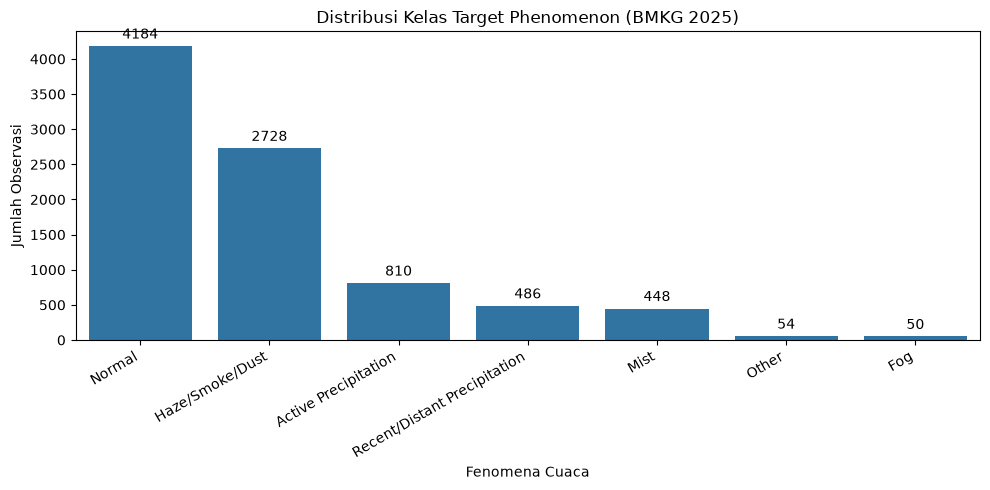

In [44]:
plt.figure(figsize=(10, 5))
order = eda_df['phenomenon'].value_counts().index
ax = sns.countplot(data=eda_df, x='phenomenon', order=order)
for container in ax.containers:
    ax.bar_label(container, padding=3)
plt.title('Distribusi Kelas Target Phenomenon (BMKG 2025)')
plt.xlabel('Fenomena Cuaca')
plt.ylabel('Jumlah Observasi')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.show()

**Notes:**

- Dari total **8.760 data observasi**, distribusi kelas `phenomenon` menunjukkan ketimpangan (*class imbalance*) yang cukup tajam. Kelas **`Normal`** mendominasi dengan **4.184 data (47,76%)**, diikuti oleh **`Haze/Smoke/Dust`** sebanyak **2.728 data (31,14%)**, **`Active Precipitation`** sebanyak **810 data (9,25%)**, **`Recent/Distant Precipitation`** sebanyak **486 data (5,55%)**, dan **`Mist`** sebanyak **448 data (5,11%)**.
- Sementara itu, dua kelas minoritas memiliki jumlah sampel yang sangat sedikit, yaitu **`Other`** (kode `ww = 13`) sebanyak **54 data (0,62%)** dan **`Fog`** sebanyak **50 data (0,57%)**.
- Ketimpangan distribusi ini perlu ditangani secara khusus pada tahap pemodelan (misalnya melalui pembobotan kelas atau pengaturan strategi *sampling*) serta dievaluasi menggunakan metrik yang sensitif terhadap kelas minoritas seperti *Macro F1-Score* dan *Balanced Accuracy*, bukan hanya mengandalkan akurasi keseluruhan.

## 2.3 Numeric Feature Distribution

Distribusi setiap variabel numerik ditampilkan dalam bentuk histogram dan ringkasan statistik untuk mengetahui bentuk sebaran data, seperti kecenderungan miring (*skewed*), penumpukan pada nilai tertentu, serta keberadaan nilai yang tampak ekstrem. Pemeriksaan ini membantu menentukan perlunya penanganan lebih lanjut pada tahap *preprocessing*.

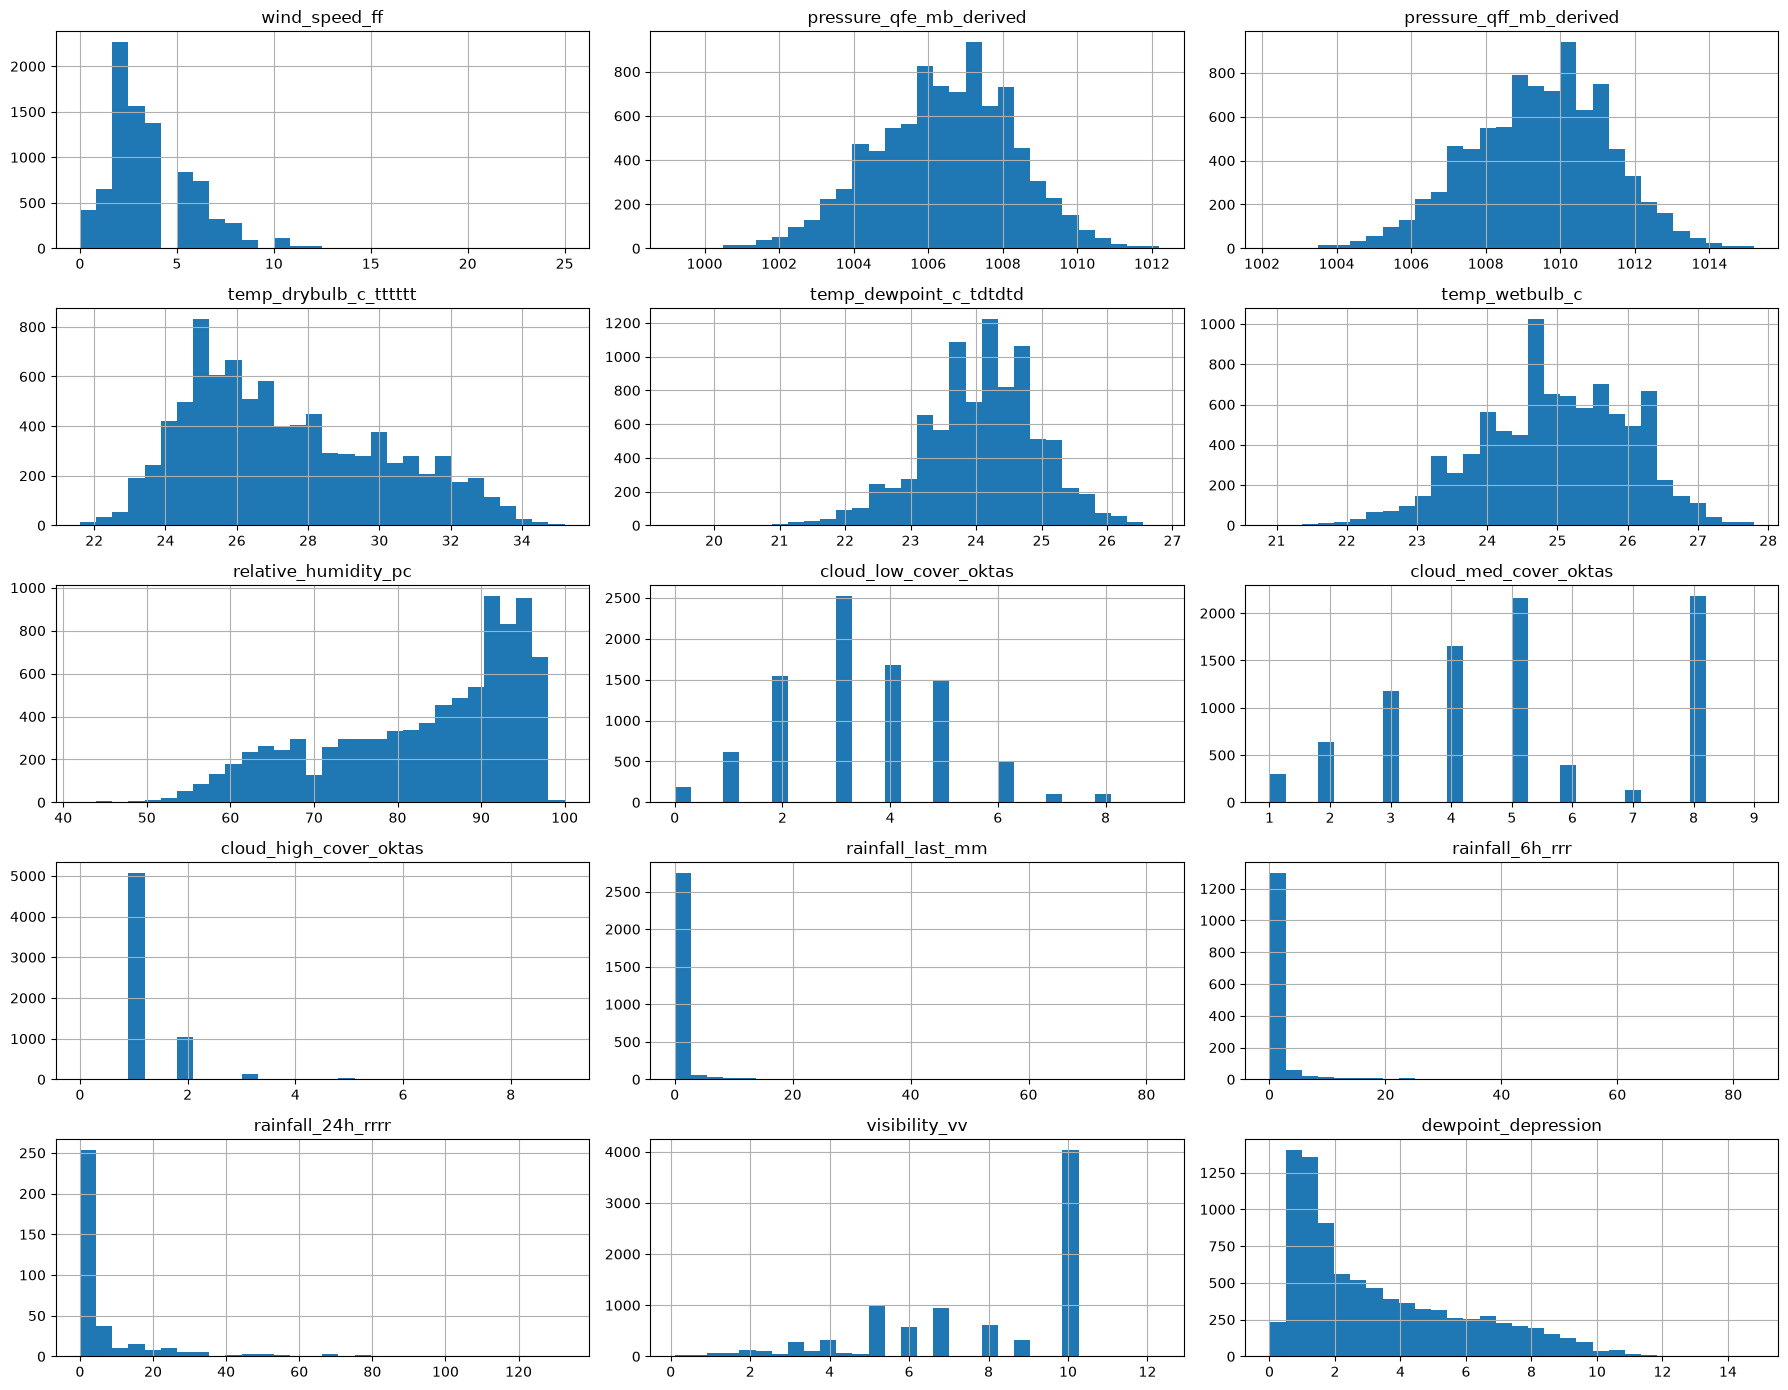

In [45]:
eda_df[num_cols].hist(bins=30, figsize=(18, 14), layout=(5, 3))
plt.tight_layout()
plt.show()

**Ringkasan statistik deskriptif dan distribusi interval (bin)**

In [46]:
def hist_text(s, bins=10):
    s = s.dropna()
    counts, edges = np.histogram(s, bins=bins)
    return ' | '.join(f'{edges[i]:.1f}-{edges[i+1]:.1f}: {counts[i]}' for i in range(len(counts)))

In [47]:
display(eda_df[num_cols].agg(['count', 'mean', 'median', 'std', 'min', 'max', 'skew']).T.round(2))

,count,mean,median,std,min,max,skew
wind_speed_ff,8760.0,3.61,3.0,2.29,0.0,25.0,1.20
pressure_qfe_mb_derived,8760.0,1006.43,1006.5,1.86,999.2,1012.2,-0.19
pressure_qff_mb_derived,8760.0,1009.45,1009.5,1.86,1002.2,1015.2,-0.20
temp_drybulb_c_tttttt,8760.0,27.39,26.8,2.73,21.6,35.2,0.49
temp_dewpoint_c_tdtdtd,8760.0,24.08,24.1,0.88,19.4,26.8,-0.31
temp_wetbulb_c,8760.0,24.96,25.0,1.06,20.9,27.8,-0.30
relative_humidity_pc,8760.0,83.23,87.0,11.94,42.0,100.0,-0.73
cloud_low_cover_oktas,8759.0,3.43,3.0,1.53,0.0,9.0,0.26
cloud_med_cover_oktas,8660.0,5.01,5.0,2.08,1.0,9.0,0.15
cloud_high_cover_oktas,6310.0,1.25,1.0,0.62,0.0,9.0,4.93


In [48]:
for col in num_cols:
    print(f'\n{col}\n  {hist_text(eda_df[col])}')


wind_speed_ff
  0.0-2.5: 3340 | 2.5-5.0: 2946 | 5.0-7.5: 1906 | 7.5-10.0: 370 | 10.0-12.5: 171 | 12.5-15.0: 16 | 15.0-17.5: 8 | 17.5-20.0: 2 | 20.0-22.5: 0 | 22.5-25.0: 1

pressure_qfe_mb_derived
  999.2-1000.5: 6 | 1000.5-1001.8: 69 | 1001.8-1003.1: 279 | 1003.1-1004.4: 968 | 1004.4-1005.7: 1550 | 1005.7-1007.0: 2266 | 1007.0-1008.3: 2313 | 1008.3-1009.6: 988 | 1009.6-1010.9: 277 | 1010.9-1012.2: 44

pressure_qff_mb_derived
  1002.2-1003.5: 6 | 1003.5-1004.8: 68 | 1004.8-1006.1: 283 | 1006.1-1007.4: 947 | 1007.4-1008.7: 1554 | 1008.7-1010.0: 2249 | 1010.0-1011.3: 2319 | 1011.3-1012.6: 996 | 1012.6-1013.9: 292 | 1013.9-1015.2: 46

temp_drybulb_c_tttttt
  21.6-23.0: 97 | 23.0-24.3: 858 | 24.3-25.7: 1935 | 25.7-27.0: 1761 | 27.0-28.4: 1250 | 28.4-29.8: 858 | 29.8-31.1: 908 | 31.1-32.5: 664 | 32.5-33.8: 385 | 33.8-35.2: 44

temp_dewpoint_c_tdtdtd
  19.4-20.1: 2 | 20.1-20.9: 7 | 20.9-21.6: 52 | 21.6-22.4: 232 | 22.4-23.1: 740 | 23.1-23.8: 2307 | 23.8-24.6: 2776 | 24.6-25.3: 2085 | 25.3-26

In [49]:
print("=== Distribusi Tutupan Awan (Oktas) ===")
for col in ['cloud_low_cover_oktas', 'cloud_med_cover_oktas', 'cloud_high_cover_oktas']:
    print(f'{col}:', eda_df[col].value_counts(dropna=False).sort_index().to_dict())

=== Distribusi Tutupan Awan (Oktas) ===
cloud_low_cover_oktas: {0.0: 193, 1.0: 612, 2.0: 1540, 3.0: 2526, 4.0: 1681, 5.0: 1498, 6.0: 499, 7.0: 105, 8.0: 102, 9.0: 3, nan: 1}
cloud_med_cover_oktas: {1.0: 304, 2.0: 638, 3.0: 1182, 4.0: 1657, 5.0: 2162, 6.0: 400, 7.0: 129, 8.0: 2185, 9.0: 3, nan: 100}
cloud_high_cover_oktas: {0.0: 2, 1.0: 5079, 2.0: 1036, 3.0: 140, 4.0: 18, 5.0: 25, 8.0: 1, 9.0: 9, nan: 2450}


In [50]:
print("=== Proporsi Kategori Curah Hujan (%) ===")
for col in ['rainfall_last_mm', 'rainfall_6h_rrr', 'rainfall_24h_rrrr']:
    nol_pct = round((eda_df[col] == 0).mean() * 100, 1)
    trace_pct = round((eda_df[col] == 0.05).mean() * 100, 1)
    rain_pct = round((eda_df[col] > 0.05).mean() * 100, 1)
    nan_pct = round(eda_df[col].isna().mean() * 100, 1)
    print(f'{col:<18} -> Nol: {nol_pct:4.1f}% | Trace (0.05): {trace_pct:3.1f}% | Hujan (>0.05): {rain_pct:3.1f}% | NaN: {nan_pct:4.1f}%')

=== Proporsi Kategori Curah Hujan (%) ===
rainfall_last_mm   -> Nol: 26.3% | Trace (0.05): 1.8% | Hujan (>0.05): 5.2% | NaN: 66.7%
rainfall_6h_rrr    -> Nol: 11.7% | Trace (0.05): 1.1% | Hujan (>0.05): 3.9% | NaN: 83.3%
rainfall_24h_rrrr  -> Nol:  1.5% | Trace (0.05): 0.4% | Hujan (>0.05): 2.3% | NaN: 95.8%


**Notes:**

- **Kecepatan Angin (`wind_speed_ff`):** Memiliki sebaran miring ke kanan (*positively skewed*, `skew = 1,20`) dengan rata-rata `3,61 knot` dan median `3,0 knot`. Sebagian besar observasi terkonsentrasi pada kecepatan angin rendah (`0,0–5,0 knot` mencakup **6.286 baris / 71,8%**), dan semakin jarang pada kecepatan tinggi hingga maksimum `25,0 knot`.
- **Tekanan Udara (`pressure_qfe_mb_derived` & `pressure_qff_mb_derived`):** Kedua variabel memiliki distribusi yang hampir simetris (`skew = -0,19` dan `-0,20`) dengan rentang variasi yang sempit (`std = 1,86 mb`), khas wilayah ekuator. Keduanya menunjukkan pola distribusi yang identik dengan selisih konstan sekitar `3,02 mb` (mengindikasikan kolinearitas tinggi sehingga cukup dipilih salah satu pada tahap seleksi fitur).
- **Suhu Udara, Titik Embun, dan Bola Basah:** Suhu bola kering (`temp_drybulb_c_tttttt`) sedikit miring ke kanan (`skew = 0,49`, rentang `21,6°C–35,2°C`) akibat pemanasan siang hari, sedangkan suhu titik embun (`24,08 ± 0,88°C`) dan suhu bola basah (`24,96 ± 1,06°C`) terpusat sangat sempit dan mendekati simetris.
- **Kelembapan Relatif & *Dew Point Depression*:** Kelembapan relatif (`relative_humidity_pc`) miring ke kiri (`skew = -0,73`) dengan penumpukan pada kondisi lembap (`88,4%–100%` mencakup **3.972 baris / 45,3%**). Sebaliknya, `dewpoint_depression` miring ke kanan (`skew = 0,98`) dan menumpuk pada selisih kecil (`0,0°C–1,5°C` sebanyak **2.999 baris / 34,2%**), yang mencerminkan kondisi atmosfer dekat jenuh pada malam hingga pagi hari.
- **Tutupan Awan (`cloud_*_cover_oktas`):** Awan rendah terpusat pada `2–5 oktas` (median `3,0`), awan menengah mengelompok di `5` dan `8 oktas` (median `5,0`), sedangkan awan tinggi didominasi `1 okta` (`5.079` baris, `skew = 4,93`) dengan `2.450` nilai `NaN`. Selain itu, terdapat kode **`9`** pada beberapa baris (`3` baris di awan rendah/menengah dan `9` baris di awan tinggi) yang dalam sandi meteorologi berarti langit terhalang (*sky obscured*), bukan tutupan 9 oktas, sehingga perlu diperhatikan pada tahap *preprocessing*.
- **Curah Hujan (`rainfall_last_mm`, `rainfall_6h_rrr`, `rainfall_24h_rrrr`):** Ketiganya sangat miring ke kanan (`skew` masing-masing `9,87`, `6,65`, dan `3,60`) karena didominasi oleh nilai kosong (`NaN` sebesar **66,7%**, **83,3%**, dan **95,8%**) serta kondisi tidak hujan (`0,0 mm`), sementara kejadian hujan terukur (`> 0,05 mm`) hanya mencakup **5,2%**, **3,9%**, dan **2,3%** dari total observasi.
- **Jarak Pandang (`visibility_vv`):** Berdistribusi miring ke kiri (`skew = -0,74`, median `8,0 km`) dengan konsentrasi tinggi pada batas atas `10,0 km` (**4.041 baris / 46,1%**), serta ekor panjang ke arah nilai rendah (`0,1–4,9 km`) yang berasosiasi dengan fenomena kabut, *mist*, asap/*haze*, dan hujan.

## 2.4 Numeric Features by Phenomenon

Perbandingan nilai setiap variabel numerik pada masing-masing kelas fenomena dilakukan menggunakan boxplot untuk melihat apakah terdapat perbedaan karakteristik antar fenomena. Uji Kruskal-Wallis digunakan untuk mengukur apakah perbedaan tersebut signifikan secara statistik. Uji ini dipilih karena tidak mengasumsikan data berdistribusi normal dan dapat digunakan pada kelas dengan jumlah data yang berbeda-beda. Analisis ini juga mencakup `visibility_vv` sebagai salah satu fitur model.

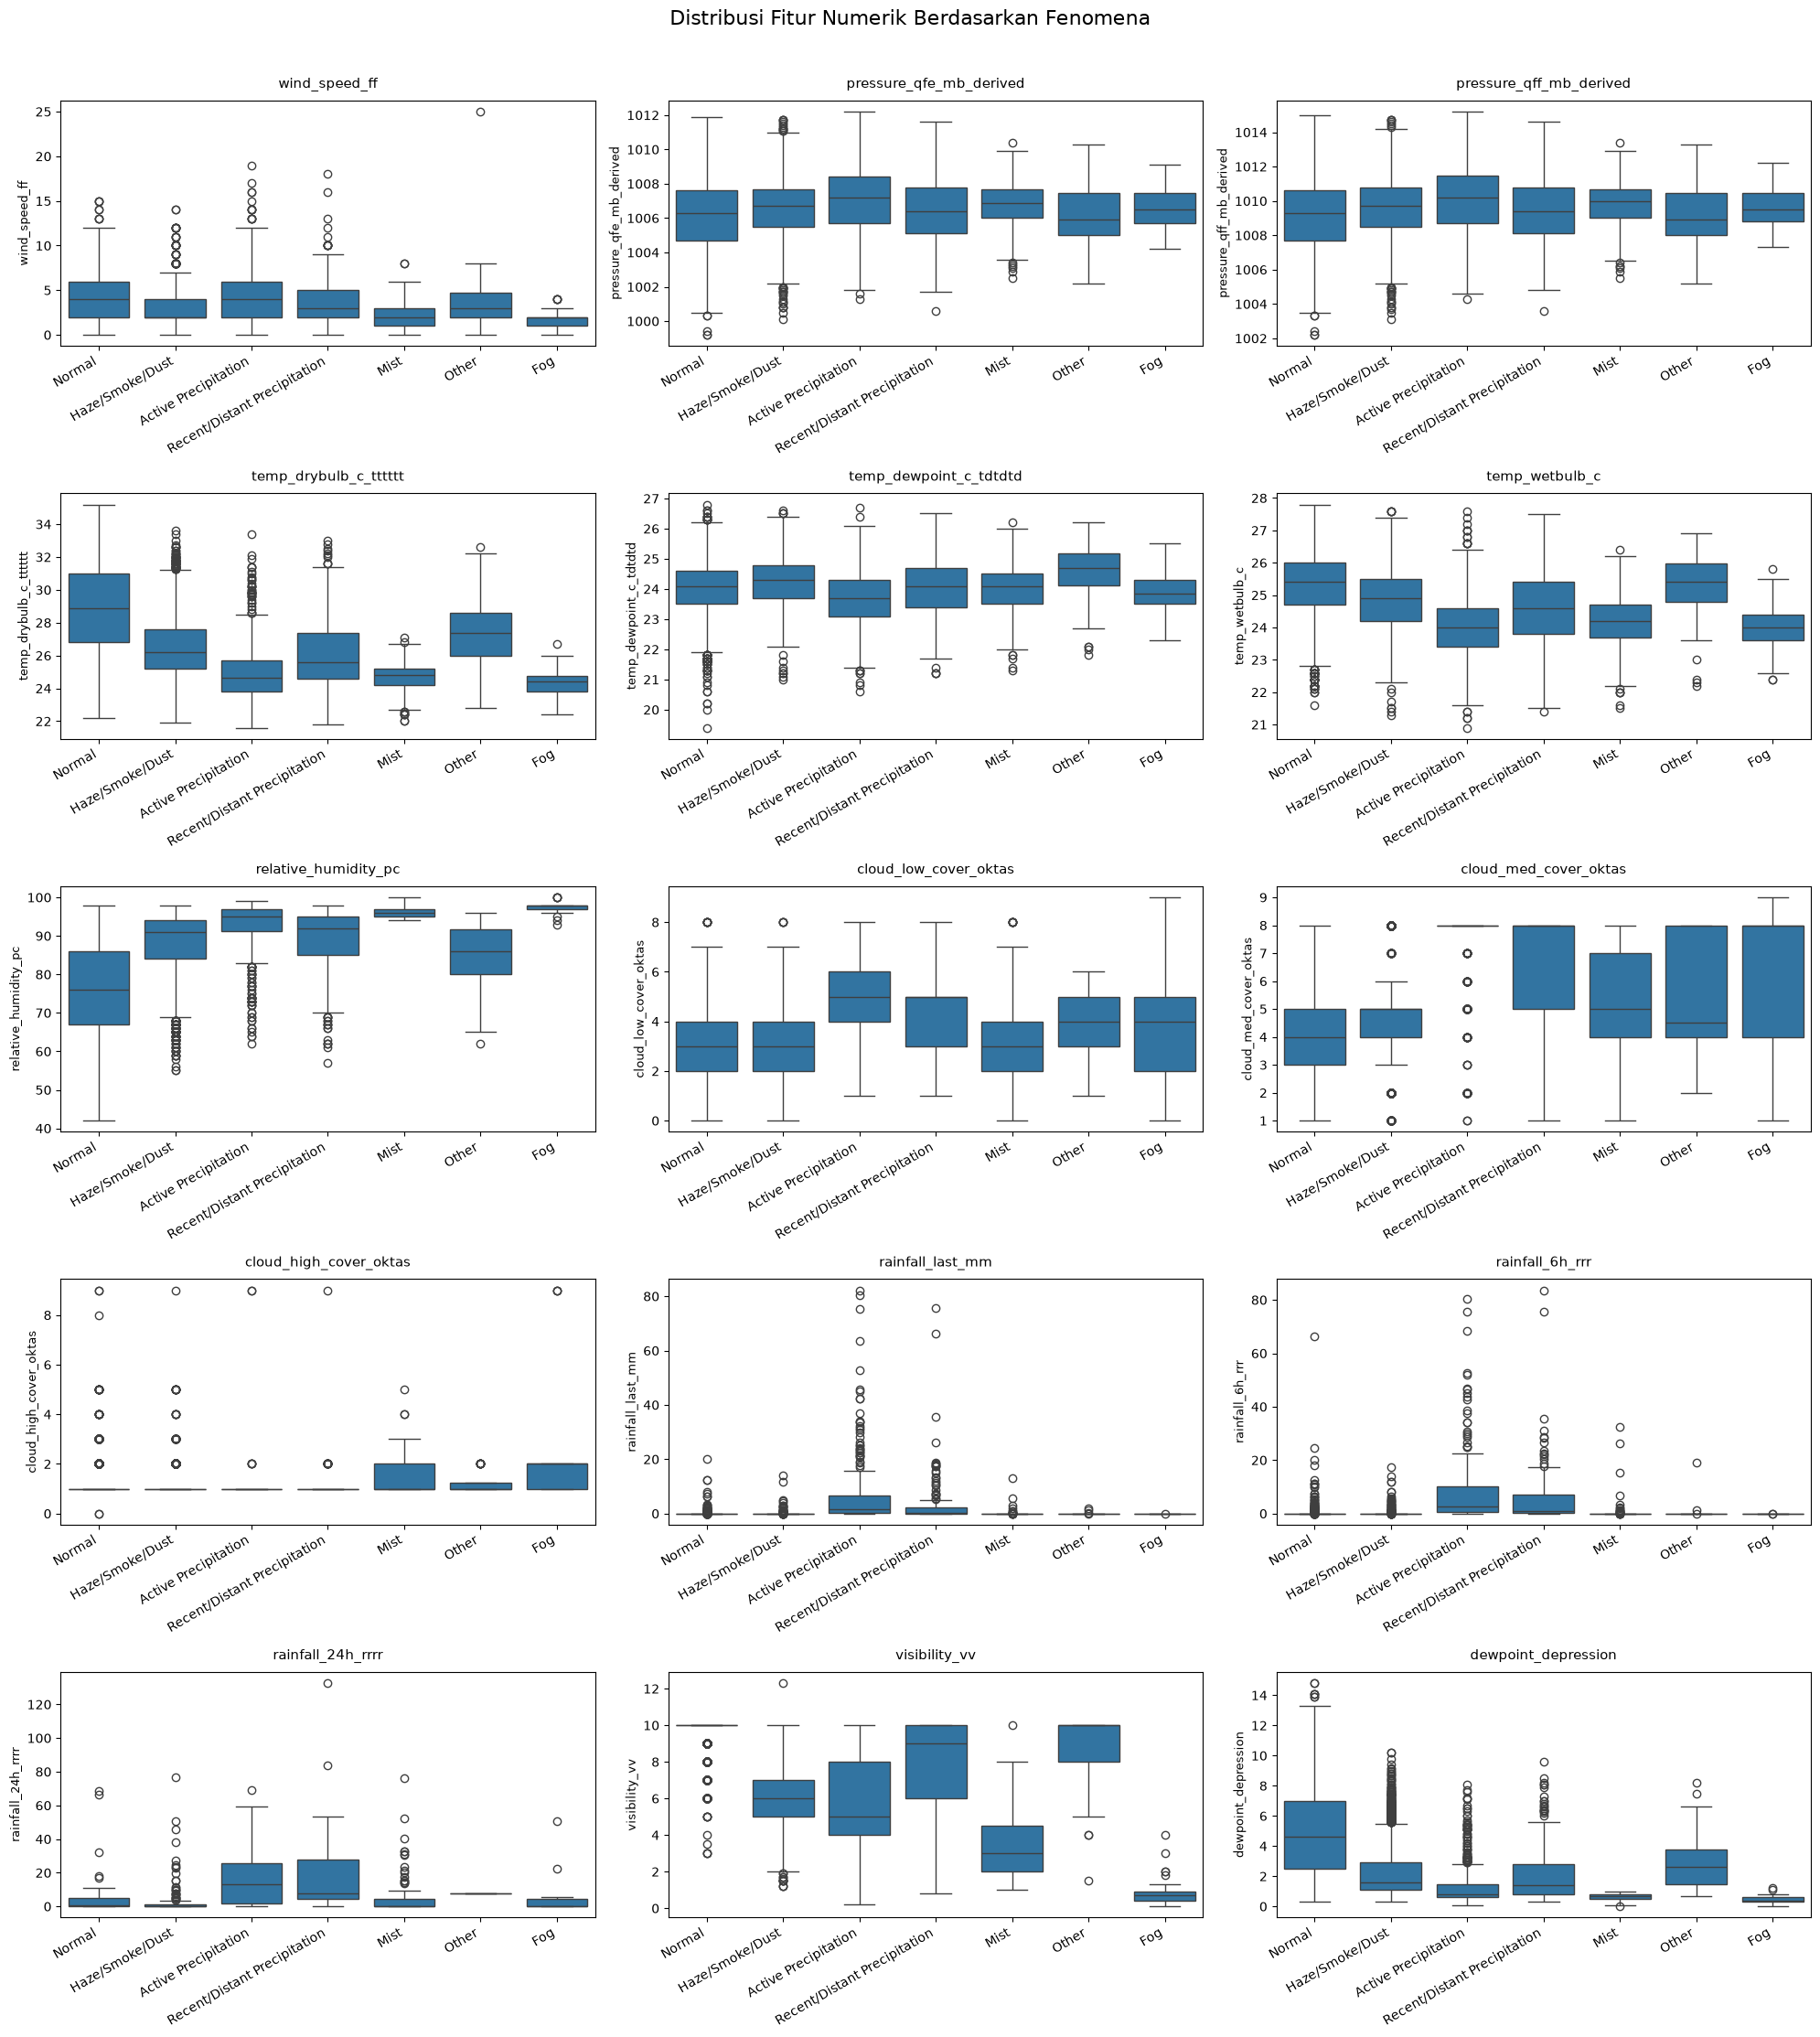

In [51]:
fig, axes = plt.subplots(5, 3, figsize=(20, 22))

for ax, col in zip(axes.flatten(), num_cols):
    sns.boxplot(
        data=eda_df,
        x='phenomenon',
        y=col,
        order=eda_df['phenomenon'].value_counts().index,
        ax=ax
    )

    ax.set_title(col, fontsize=11, pad=10)
    ax.set_xlabel('')
    ax.set_ylabel(col, fontsize=9)
    
    ax.tick_params(axis='x', labelrotation=30)
    for label in ax.get_xticklabels():
        label.set_horizontalalignment('right')

# Menghilangkan subplot yang tidak digunakan
for ax in axes.flatten()[len(num_cols):]:
    ax.remove()

plt.suptitle(
    'Distribusi Fitur Numerik Berdasarkan Fenomena',
    fontsize=16,
    y=1.01
)

plt.tight_layout()
plt.show()

In [52]:
results = []

for col in num_cols:
    groups = [
        group[col].dropna().values
        for _, group in eda_df.groupby('phenomenon')
        if len(group[col].dropna()) > 0
    ]

    stat, p = kruskal(*groups)

    results.append({
        'Feature': col,
        'H-Statistic': stat,
        'P-Value': p,
        'Significant': p < 0.05
    })

kruskal_results = pd.DataFrame(results).sort_values(by='H-Statistic', ascending=False).reset_index(drop=True)

display(
    kruskal_results.style.format({
        'H-Statistic': '{:.2f}',
        'P-Value': '{:.3e}'
    })
)

,Feature,H-Statistic,P-Value,Significant
0,visibility_vv,6208.07,0.000e+00,True
1,relative_humidity_pc,3580.24,0.000e+00,True
2,dewpoint_depression,3576.85,0.000e+00,True
3,temp_drybulb_c_tttttt,2835.29,0.000e+00,True
4,rainfall_last_mm,1767.49,0.000e+00,True
5,cloud_low_cover_oktas,1441.36,2.682e-308,True
6,temp_wetbulb_c,1433.07,1.675e-306,True
7,cloud_med_cover_oktas,1227.07,6.610e-262,True
8,wind_speed_ff,1167.01,6.607e-249,True
9,rainfall_6h_rrr,630.83,5.216e-133,True


In [53]:
for col in num_cols:
    t = eda_df.groupby('phenomenon')[col].agg(
        n='count', min='min',
        q1=lambda x: x.quantile(.25), median='median',
        q3=lambda x: x.quantile(.75), max='max'
    ).round(2)
    print(f'\n{col}')
    print(t.to_string())


wind_speed_ff
                                 n  min   q1  median    q3  max
phenomenon                                                     
Active Precipitation           810    0  2.0     4.0  6.00   19
Fog                             50    0  1.0     2.0  2.00    4
Haze/Smoke/Dust               2728    0  2.0     2.0  4.00   14
Mist                           448    0  1.0     2.0  3.00    8
Normal                        4184    0  2.0     4.0  6.00   15
Other                           54    0  2.0     3.0  4.75   25
Recent/Distant Precipitation   486    0  2.0     3.0  5.00   18

pressure_qfe_mb_derived
                                 n     min       q1  median       q3     max
phenomenon                                                                  
Active Precipitation           810  1001.3  1005.70  1007.2  1008.40  1012.2
Fog                             50  1004.2  1005.70  1006.5  1007.45  1009.1
Haze/Smoke/Dust               2728  1000.1  1005.50  1006.7  1007.70  1011.7

**Notes:**

- ***Visibility*, Kelembapan Relatif, dan *Dew Point Depression*:** Kelas `Fog` dan `Mist` memiliki nilai jarak pandang paling rendah (median `0,7 km` dan `3,0 km`) serta *dew point depression* paling sempit (`0,4°C` dan `0,7°C`) dengan kelembapan relatif mendekati jenuh (median `98%` dan `96%`). Sebaliknya, kelas `Normal` memiliki jarak pandang tertinggi (median `10,0 km`), kelembapan terendah (`76%`), dan *dew point depression* terlebar (`4,6°C`). Pemisahan kelas hujan juga terbukti relevan karena `Active Precipitation` memiliki median *visibility* `5,0 km`, sedangkan `Recent/Distant Precipitation` kembali mendekati kondisi normal dengan median `9,0 km`.
- **Suhu Udara dan Suhu Bola Basah:** Kelas `Normal` (`28,90°C`) dan `Other` (`27,40°C`) memiliki median suhu bola kering yang lebih tinggi dibandingkan `Fog` (`24,40°C`), `Active Precipitation` (`24,65°C`), dan `Mist` (`24,80°C`) yang umumnya terjadi pada malam hingga pagi hari atau saat hujan.
- **Tutupan Awan dan Curah Hujan:** Kelas `Active Precipitation` dan `Recent/Distant Precipitation` memiliki tutupan awan rendah dan menengah yang lebih tebal (median masing-masing `5,0` dan `8,0 oktas`), serta nilai curah hujan (`rainfall_last_mm` dan `rainfall_6h_rrr`) yang lebih tinggi dibandingkan kelas lainnya yang didominasi median `0,00 mm`. Selain itu, jumlah data valid `cloud_high_cover_oktas` pada kelas `Active Precipitation` tercatat sangat sedikit (`n = 91` dari `810` observasi) karena lapisan awan hujan yang tebal menghalangi pengamatan awan tinggi.
- **Kecepatan Angin, Tekanan Udara, dan Titik Embun:** Fenomena `Fog`, `Mist`, dan `Haze/Smoke/Dust` cenderung terjadi pada kondisi angin tenang (median `2,0 knot`) yang mendukung pendinginan radiasi maupun akumulasi partikel di udara, sedangkan `Normal` dan `Active Precipitation` memiliki median lebih tinggi (`4,0 knot`). Sementara itu, variabel tekanan udara (`QFE` dan `QFF`) serta suhu titik embun memiliki nilai median yang relatif berdekatan antarkelas.

Uji Kruskal-Wallis dilakukan untuk mengetahui apakah terdapat perbedaan distribusi yang signifikan secara statistik pada setiap variabel numerik berdasarkan ketujuh kelas fenomena. Hasil pengujian menunjukkan bahwa seluruh 15 variabel memiliki nilai *p-value* di bawah `0,05` (`Significant = True`), yang mengindikasikan adanya perbedaan distribusi yang signifikan secara statistik pada setidaknya satu pasangan kelas fenomena. Variabel `visibility_vv` mencatatkan nilai *H-statistic* tertinggi sebesar **`6208,07`**, diikuti oleh `relative_humidity_pc` (**`3580,24`**) dan `dewpoint_depression` (**`3576,85`**), sedangkan `rainfall_24h_rrrr` memiliki nilai terendah sebesar **`87,76`**. Meskipun demikian, besarnya nilai *H-statistic* mencerminkan perbedaan peringkat antarpopulasi secara univariat dan tidak secara langsung merepresentasikan tingkat kepentingan fitur (*feature importance*) akhir dalam model klasifikasi.

Secara keseluruhan, hasil analisis ini mengonfirmasi bahwa fitur-fitur numerik—khususnya jarak pandang, parameter kelembapan, suhu, tutupan awan, dan curah hujan—memiliki daya pembeda yang kuat antarkelas fenomena cuaca untuk digunakan pada tahap pemodelan.

## 2.5 Correlation Between Numeric Feature

Korelasi antar variabel numerik dihitung menggunakan metode Spearman untuk mengetahui kekuatan hubungan antar fitur. Metode ini dipilih karena tidak mengasumsikan hubungan linear dan lebih tahan terhadap nilai ekstrem. Analisis ini bertujuan mengidentifikasi fitur yang saling berkorelasi tinggi (multikolinearitas) sebagai bahan pertimbangan pemilihan fitur. Korelasi hanya dihitung untuk variabel numerik.

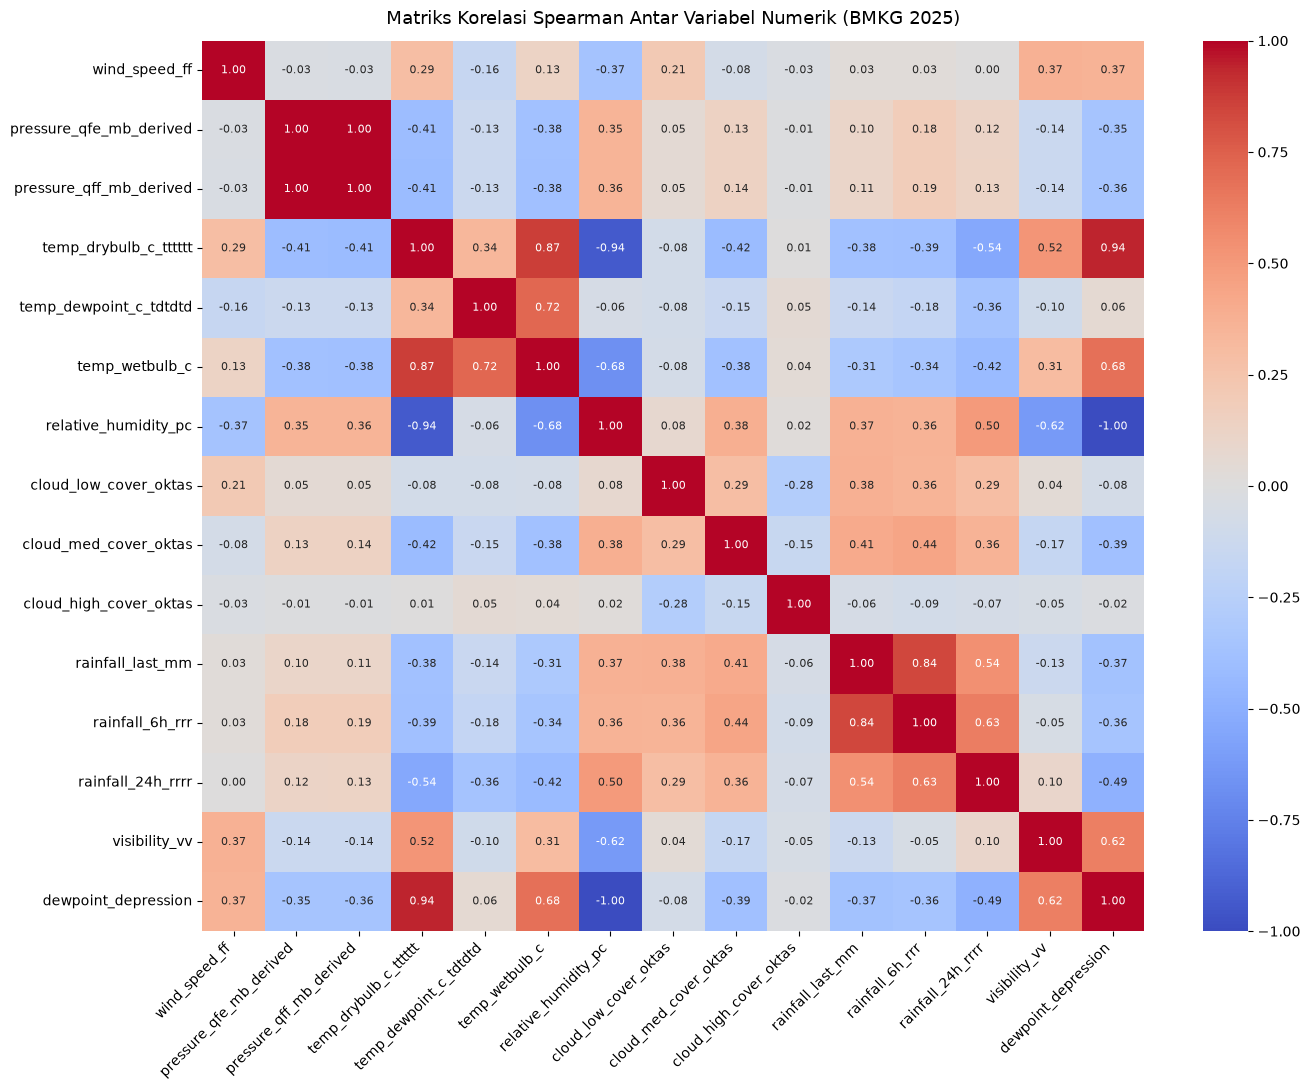

In [54]:
corr_matrix = eda_df[num_cols].corr(method='spearman')

plt.figure(figsize=(14, 11))
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0,
    vmin=-1,
    vmax=1,
    annot_kws={'size': 8}
)
plt.title('Matriks Korelasi Spearman Antar Variabel Numerik (BMKG 2025)', fontsize=13, pad=12)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [55]:
display(corr_matrix.round(2))

,wind_speed_ff,pressure_qfe_mb_derived,pressure_qff_mb_derived,temp_drybulb_c_tttttt,temp_dewpoint_c_tdtdtd,temp_wetbulb_c,relative_humidity_pc,cloud_low_cover_oktas,cloud_med_cover_oktas,cloud_high_cover_oktas,rainfall_last_mm,rainfall_6h_rrr,rainfall_24h_rrrr,visibility_vv,dewpoint_depression
wind_speed_ff,1.00,-0.03,-0.03,0.29,-0.16,0.13,-0.37,0.21,-0.08,-0.03,0.03,0.03,0.00,0.37,0.37
pressure_qfe_mb_derived,-0.03,1.00,1.00,-0.41,-0.13,-0.38,0.35,0.05,0.13,-0.01,0.10,0.18,0.12,-0.14,-0.35
pressure_qff_mb_derived,-0.03,1.00,1.00,-0.41,-0.13,-0.38,0.36,0.05,0.14,-0.01,0.11,0.19,0.13,-0.14,-0.36
temp_drybulb_c_tttttt,0.29,-0.41,-0.41,1.00,0.34,0.87,-0.94,-0.08,-0.42,0.01,-0.38,-0.39,-0.54,0.52,0.94
temp_dewpoint_c_tdtdtd,-0.16,-0.13,-0.13,0.34,1.00,0.72,-0.06,-0.08,-0.15,0.05,-0.14,-0.18,-0.36,-0.10,0.06
temp_wetbulb_c,0.13,-0.38,-0.38,0.87,0.72,1.00,-0.68,-0.08,-0.38,0.04,-0.31,-0.34,-0.42,0.31,0.68
relative_humidity_pc,-0.37,0.35,0.36,-0.94,-0.06,-0.68,1.00,0.08,0.38,0.02,0.37,0.36,0.50,-0.62,-1.00
cloud_low_cover_oktas,0.21,0.05,0.05,-0.08,-0.08,-0.08,0.08,1.00,0.29,-0.28,0.38,0.36,0.29,0.04,-0.08
cloud_med_cover_oktas,-0.08,0.13,0.14,-0.42,-0.15,-0.38,0.38,0.29,1.00,-0.15,0.41,0.44,0.36,-0.17,-0.39
cloud_high_cover_oktas,-0.03,-0.01,-0.01,0.01,0.05,0.04,0.02,-0.28,-0.15,1.00,-0.06,-0.09,-0.07,-0.05,-0.02


**Notes:**
- **Tekanan Udara (`QFE` dan `QFF`):** `pressure_qfe_mb_derived` dan `pressure_qff_mb_derived` memiliki korelasi positif sempurna (`1,00`), karena keduanya diturunkan dari pengukuran tekanan yang sama dengan selisih konstan akibat koreksi elevasi stasiun.
- **Suhu, Kelembapan Relatif, dan *Dew Point Depression*:** Suhu bola kering (`temp_drybulb_c_tttttt`) berkorelasi positif sangat kuat dengan `dewpoint_depression` (`0,94`) dan suhu bola basah (`0,87`), serta berkorelasi negatif sangat kuat dengan `relative_humidity_pc` (`-0,94`). Selain itu, `relative_humidity_pc` dan `dewpoint_depression` menunjukkan korelasi negatif rank sempurna (`-1,00`), yang secara fisik wajar karena semakin kecil selisih suhu udara dengan titik embun, semakin tinggi kelembapan relatifnya.
- **Kelompok Curah Hujan (`rainfall_*`):** Variabel `rainfall_last_mm` berkorelasi positif sangat kuat dengan `rainfall_6h_rrr` (`0,84`) dan berkorelasi sedang dengan `rainfall_24h_rrrr` (`0,54`), sedangkan `rainfall_6h_rrr` dan `rainfall_24h_rrrr` memiliki korelasi positif kuat (`0,63`). Perlu dicatat bahwa perhitungan korelasi berpasangan ini hanya mengevaluasi baris yang sama-sama tidak kosong (`n = 1.460` untuk 6 jam dan `n = 365` untuk 24 jam).
- **Jarak Pandang (`visibility_vv`):** Memiliki korelasi negatif kuat dengan `relative_humidity_pc` (`-0,62`), korelasi positif kuat dengan `dewpoint_depression` (`0,62`), serta korelasi positif sedang dengan `temp_drybulb_c_tttttt` (`0,52`), yang menegaskan bahwa penurunan jarak pandang sangat berkaitan dengan peningkatan kejenuhan uap air di atmosfer.
- **Kelompok Tutupan Awan (`cloud_*_cover_oktas`):** Awan rendah dan awan menengah memiliki korelasi positif lemah (`0,29`), sedangkan awan rendah dan awan tinggi berkorelasi negatif lemah (`-0,28`) karena lapisan awan bawah yang tebal sering menghalangi pengamatan awan tinggi. Awan menengah juga menunjukkan korelasi positif sedang dengan curah hujan (`0,41` terhadap `rainfall_last_mm` dan `0,44` terhadap `rainfall_6h_rrr`).

Berdasarkan hasil matriks korelasi Spearman, teridentifikasi beberapa pasangan variabel dengan tingkat multikolinearitas sangat tinggi, terutama pada pasangan tekanan (`QFE`–`QFF`), kelompok suhu–kelembapan–*dew point depression*, serta antarperiode curah hujan. Meskipun algoritma berbasis pohon keputusan (*tree-based models*) relatif tahan terhadap multikolinearitas dalam menghasilkan prediksi, fitur yang sepenuhnya redundan seperti salah satu variabel tekanan (`QFE` atau `QFF`) tetap perlu dipertimbangkan untuk diseleksi pada tahap *preprocessing* agar interpretasi *feature importance* lebih jelas.

## 2.6 Temporal Pattern

Pola temporal fenomena dianalisis berdasarkan jam pengamatan (WIB) dan bulan untuk mengetahui apakah jenis fenomena tertentu cenderung muncul pada waktu tertentu. Proporsi fenomena dihitung per jam dan per bulan agar perbandingan antarwaktu tetap objektif dan tidak dipengaruhi perbedaan jumlah observasi.

In [56]:
phenom_order = eda_df['phenomenon'].value_counts().index

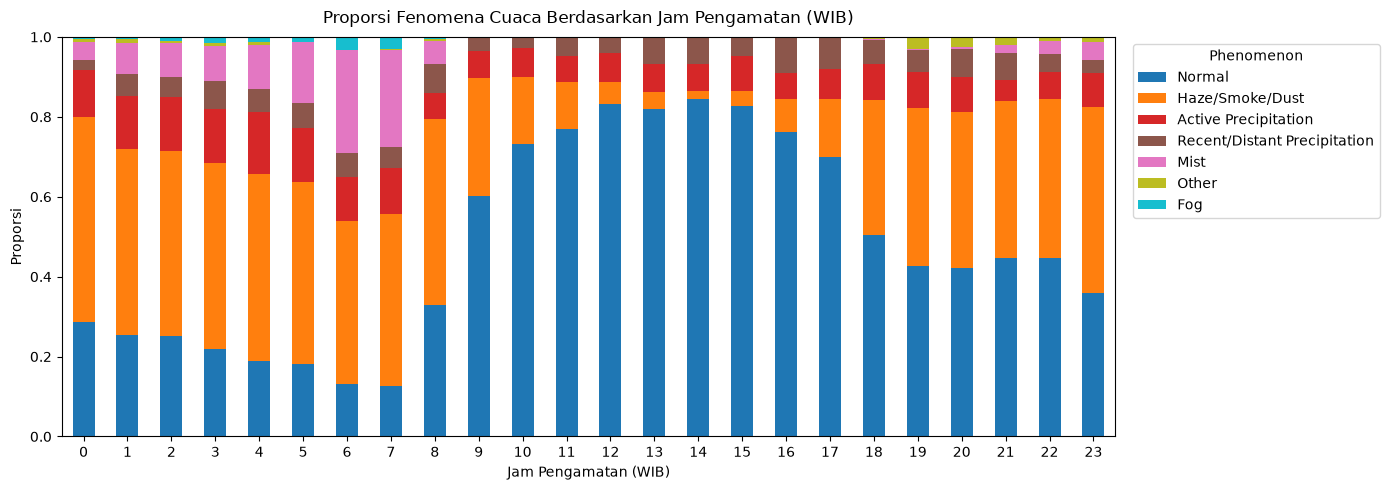

In [57]:
ct_hour = pd.crosstab(eda_df['hour_wib'], eda_df['phenomenon'], normalize='index')[phenom_order]
ax = ct_hour.plot(kind='bar', stacked=True, figsize=(14, 5), colormap='tab10')

plt.title('Proporsi Fenomena Cuaca Berdasarkan Jam Pengamatan (WIB)', fontsize=12, pad=10)
plt.xlabel('Jam Pengamatan (WIB)')
plt.ylabel('Proporsi')
plt.xticks(rotation=0)
plt.legend(title='Phenomenon', bbox_to_anchor=(1.01, 1), loc='upper left')
plt.tight_layout()
plt.show()

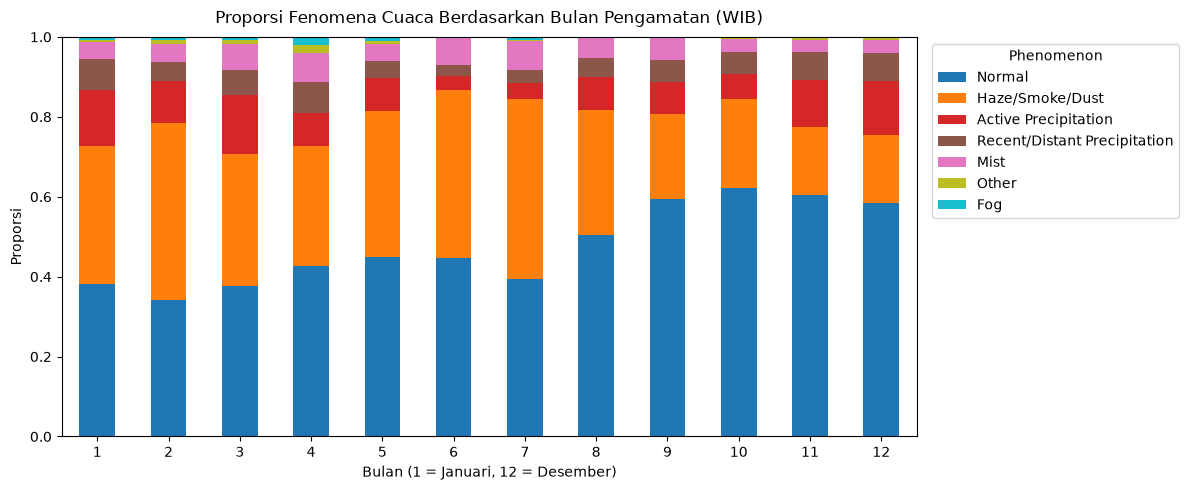

In [58]:
ct_month = pd.crosstab(eda_df['month_wib'], eda_df['phenomenon'], normalize='index')[phenom_order]
ax = ct_month.plot(kind='bar', stacked=True, figsize=(12, 5), colormap='tab10')

plt.title('Proporsi Fenomena Cuaca Berdasarkan Bulan Pengamatan (WIB)', fontsize=12, pad=10)
plt.xlabel('Bulan (1 = Januari, 12 = Desember)')
plt.ylabel('Proporsi')
plt.xticks(rotation=0)
plt.legend(title='Phenomenon', bbox_to_anchor=(1.01, 1), loc='upper left')
plt.tight_layout()
plt.show()

In [59]:
ct_hour_n = pd.crosstab(eda_df['hour_wib'], eda_df['phenomenon'])[phenom_order]
print("=== Proporsi Fenomena per Jam WIB (%) ===")
display((ct_hour_n.div(ct_hour_n.sum(axis=1), axis=0) * 100).round(1))

=== Proporsi Fenomena per Jam WIB (%) ===


phenomenon,Normal,Haze/Smoke/Dust,Active Precipitation,Recent/Distant Precipitation,Mist,Other,Fog
hour_wib,,,,,,,
0,28.8,51.2,11.8,2.5,4.4,0.8,0.5
1,25.5,46.6,13.2,5.5,7.7,1.1,0.5
2,25.2,46.3,13.4,4.9,8.5,0.5,1.1
3,21.9,46.6,13.4,7.1,8.8,0.5,1.6
4,18.9,46.8,15.3,5.8,11.2,0.5,1.4
5,18.1,45.5,13.7,6.3,15.1,0.0,1.4
6,13.2,40.8,11.0,6.0,25.8,0.0,3.3
7,12.6,43.0,11.5,5.2,24.4,0.3,3.0
8,32.9,46.6,6.6,7.1,5.8,0.5,0.5


In [60]:
ct_month_n = pd.crosstab(eda_df['month_wib'], eda_df['phenomenon'])[phenom_order]
print("=== Proporsi Fenomena per Bulan WIB (%) ===")
display((ct_month_n.div(ct_month_n.sum(axis=1), axis=0) * 100).round(1))

=== Proporsi Fenomena per Bulan WIB (%) ===


phenomenon,Normal,Haze/Smoke/Dust,Active Precipitation,Recent/Distant Precipitation,Mist,Other,Fog
month_wib,,,,,,,
1,38.0,34.5,14.2,7.5,4.4,0.4,0.8
2,34.1,44.3,10.4,4.9,4.5,1.0,0.7
3,37.8,32.9,14.8,6.2,6.6,0.9,0.8
4,42.6,30.0,8.3,7.6,7.4,1.9,2.1
5,44.9,36.6,8.2,4.3,4.3,0.7,1.1
6,44.7,42.1,3.5,2.6,6.8,0.1,0.1
7,39.4,45.0,4.0,3.2,7.3,0.3,0.8
8,50.4,31.2,8.3,4.8,5.0,0.1,0.1
9,59.4,21.2,7.9,5.7,5.4,0.3,0.0


In [61]:
print("Jumlah observasi per jam (min - max):", ct_hour_n.sum(axis=1).min(), "-", ct_hour_n.sum(axis=1).max())
print("Jumlah observasi per bulan:\n", ct_month_n.sum(axis=1).to_dict())

Jumlah observasi per jam (min - max): 365 - 365
Jumlah observasi per bulan:
 {1: 744, 2: 672, 3: 744, 4: 720, 5: 744, 6: 720, 7: 744, 8: 744, 9: 720, 10: 744, 11: 720, 12: 744}


**Notes:**
- **Berdasarkan Jam Pengamatan (`hour_wib`):**
  - **`Fog` dan `Mist`:** Terkonsentrasi pada dini hari hingga pagi (`23.00–08.00` WIB) akibat pendinginan radiasi permukaan, dengan puncak kemunculan pada pukul **`06.00`–`07.00` WIB** (`Mist` mencapai **25,8%** dan **24,4%**; `Fog` mencapai **3,3%** dan **3,0%**), serta tidak pernah muncul pada siang hingga sore hari (`10.00–17.00` WIB).
  - **`Haze/Smoke/Dust`:** Memiliki proporsi tinggi pada malam hingga pagi hari (`19.00–08.00` WIB sekitar `38,9%–51,2%`, puncaknya pukul `00.00` WIB sebesar **51,2%**), kemudian menurun tajam saat pemanasan dan pencampuran atmosfer siang hari hingga titik terendah pada pukul `14.00` WIB (**2,2%**).
  - **`Normal`:** Mendominasi pada siang hingga sore hari (`09.00–18.00` WIB), terutama pada rentang pukul **`12.00–15.00` WIB** dengan proporsi **81,9%–84,4%** (puncak pukul `14.00` WIB).
  - **`Active Precipitation` dan `Recent/Distant Precipitation`:** `Active Precipitation` memiliki proporsi tertinggi pada dini hari (`01.00–05.00` WIB, puncaknya pukul `04.00` WIB sebesar **15,3%**) serta sedikit meningkat pada sore hingga awal malam (`15.00–20.00` WIB sekitar `8,8%–9,0%`). Sementara itu, `Recent/Distant Precipitation` tersebar relatif merata sepanjang hari (`2,5%–8,8%`) dengan puncak pada pukul `16.00` WIB (**8,8%**).
  - **`Other` (`ww = 13`):** Hanya muncul pada malam hingga dini hari (`19.00–04.00` WIB, terutama pukul `19.00–20.00` WIB sebesar **3,0%** dan **2,5%**) karena kilat jauh secara visual lebih mudah teramati saat kondisi gelap.

- **Berdasarkan Bulan Pengamatan (`month_wib`):**
  - **`Haze/Smoke/Dust`:** Memiliki proporsi lebih tinggi pada awal hingga pertengahan tahun, khususnya pada **Juli (45,0%)**, **Februari (44,3%)**, dan **Juni (42,1%)**, lalu menurun pada September–Desember (`17,1%–22,4%`).
  - **`Normal`:** Mendominasi pada paruh akhir tahun sejak **Agustus hingga Desember (`50,4%–62,1%`)**, dengan puncak pada **Oktober (62,1%)**.
  - **`Active Precipitation` dan `Recent/Distant Precipitation`:** Keduanya memiliki proporsi tertinggi pada bulan-bulan basah seperti **Januari** (`14,2%` dan `7,5%`), **Maret** (`14,8%` dan `6,2%`), **November** (`11,7%` dan `6,9%`), dan **Desember** (`13,3%` dan `7,1%`), lalu turun ke titik terendah pada **Juni** (`3,5%` dan `2,6%`) dan **Juli** (`4,0%` dan `3,2%`).
  - **`Mist` dan `Fog`:** `Mist` relatif stabil sepanjang tahun (`3,2%–7,4%`, tertinggi pada April `7,4%` dan Juli `7,3%`), sedangkan `Fog` paling sering muncul pada **April (2,1%)** dan hampir tidak ditemukan pada Agustus–Desember (`0,0%–0,1%`).

Secara keseluruhan, pola diurnal (*per jam*) menunjukkan pemisahan karakteristik waktu yang sangat kuat antarfenomena sehingga fitur waktu (seperti jam pengamatan) berpotensi memberikan informasi tambahan yang berguna bagi model. Adapun pola bulanan di atas mencerminkan variasi sepanjang tahun 2025 dengan kelengkapan observasi yang merata di setiap bulan (`672–744` jam), meskipun data satu tahun belum dapat digeneralisasi sebagai pola klimatologis musiman jangka panjang.

## 2.7 Label Origin and Data Leakage Check

Pemeriksaan dilakukan untuk memverifikasi keterkaitan langsung antara label target `phenomenon` dengan variabel pembentuknya (`present_weather_ww` dan `weather_indicator_ix`). Karena `phenomenon` dipetakan secara langsung dari sandi `present_weather_ww`, analisis ini menjadi dasar untuk mengecualikan variabel-variabel penyandian cuaca tersebut dari daftar fitur prediktor pada tahap *preprocessing* guna mencegah kebocoran informasi (*data leakage*).

In [62]:
print("=== Crosstab phenomenon vs weather_indicator_ix ===")
display(pd.crosstab(eda_df['phenomenon'], eda_df['weather_indicator_ix'], margins=True))

=== Crosstab phenomenon vs weather_indicator_ix ===


weather_indicator_ix,1,2,All
phenomenon,,,
Active Precipitation,810,0,810
Fog,50,0,50
Haze/Smoke/Dust,2728,0,2728
Mist,448,0,448
Normal,201,3983,4184
Other,54,0,54
Recent/Distant Precipitation,486,0,486
All,4777,3983,8760


In [63]:
print("=== Jumlah kode unik present_weather_ww per kelas phenomenon ===")
ww_mapping_check = eda_df.groupby('phenomenon')['present_weather_ww'].agg(
    jumlah_data='count',
    kode_ww_unik=lambda x: sorted(x.unique().tolist())
)
display(ww_mapping_check)

=== Jumlah kode unik present_weather_ww per kelas phenomenon ===


,jumlah_data,kode_ww_unik
phenomenon,,
Active Precipitation,810,"[50, 51, 60, 61, 62, 63, 64, 65, 91, 95, 97]"
Fog,50,"[28, 40, 41, 42, 44, 45, 46, 47]"
Haze/Smoke/Dust,2728,"[5, 6]"
Mist,448,[10]
Normal,4184,"[0, 1, 2, 3]"
Other,54,[13]
Recent/Distant Precipitation,486,"[15, 16, 17, 21, 29]"


**Notes:**

- **`present_weather_ww`:** Seluruh **32 kode sandi unik** terpetakan secara deterministik (100% tanpa tumpang tindih kode antarkelas) ke dalam 7 kelas target `phenomenon`.
- **`weather_indicator_ix`:** Seluruh observasi pada enam kelas fenomena non-normal (`4.576` baris) seluruhnya memiliki nilai `weather_indicator_ix = 1`, sedangkan nilai `weather_indicator_ix = 2` (`3.983` baris) hanya muncul pada kelas `Normal` (bersama `201` baris dengan `ix = 1` yang dipicu oleh cuaca lampau).
- **Keputusan *Preprocessing*:** Karena `present_weather_ww` merupakan sumber langsung pembentukan label target dan `weather_indicator_ix` memiliki keterkaitan langsung dengan kemunculan fenomena cuaca pada sandi sinoptik, kedua variabel tersebut (serta `past_weather_w1` dan `past_weather_w2`) wajib dikeluarkan dari fitur prediktor model untuk menghindari *data leakage*.

# 3. Preprocessing

Tahap ini melakukan pembersihan dan transformasi data berdasarkan seluruh temuan dari tahap Inspection dan EDA sebelumnya, agar data siap digunakan untuk pemodelan. Seluruh proses dilakukan pada salinan data (`clean_df`), sehingga `data_df` asli tetap terjaga sebagai referensi mentah.

## 3.1 Create Working Copy

Salinan dataset dibuat untuk diproses sehingga data mentah (`data_df`) tetap tersimpan sebagai referensi.

In [64]:
clean_df = data_df.copy()

In [65]:
print(f"Shape clean_df: {clean_df.shape}")

Shape clean_df: (8760, 82)


## 3.2 Fix Data Structure

Perbaikan tipe data dilakukan pada kolom-kolom fitur yang masih terbaca sebagai teks (`str`/`object`), meliputi konversi `data_timestamp` ke tipe `datetime64` (format `%d/%m/%Y %H:%M`) sekaligus pengurutan kronologis, serta konversi kolom tutupan awan utama ke tipe numerik dengan mengubah simbol `'/'` menjadi `NaN`.

**Konversi data_timestamp ke datetime dengan format eksplisit dan urutkan secara kronologis**

In [66]:
clean_df['data_timestamp'] = pd.to_datetime(
    clean_df['data_timestamp'],
    format='%d/%m/%Y %H:%M',
    errors='coerce'
)
clean_df = clean_df.sort_values('data_timestamp').reset_index(drop=True)

In [67]:
print(f"Tipe data data_timestamp : {clean_df['data_timestamp'].dtypes}")
print(f"Jumlah NaT setelah parse : {clean_df['data_timestamp'].isna().sum()}\n")

Tipe data data_timestamp : datetime64[us]
Jumlah NaT setelah parse : 0



**Konversi kolom tutupan awan utama dari string ('/') ke numerik**

In [68]:
cloud_cover_cols = ['cloud_low_cover_oktas', 'cloud_med_cover_oktas', 'cloud_high_cover_oktas']
for col in cloud_cover_cols:
    clean_df[col] = pd.to_numeric(clean_df[col].replace('/', np.nan), errors='coerce')

In [69]:
print(clean_df[cloud_cover_cols].dtypes)

cloud_low_cover_oktas     float64
cloud_med_cover_oktas     float64
cloud_high_cover_oktas    float64
dtype: object


## 3.3 Target Variable Creation

Kolom target `phenomenon` dibentuk dari variabel `present_weather_ww` menggunakan fungsi pemetaan 7 kelas fenomena cuaca yang telah didefinisikan pada tahap EDA. Langkah ini dilakukan sebelum tahap penghapusan kolom agar informasi label target tersimpan sebelum kolom sandi cuaca mentah dihapus.

In [70]:
clean_df['phenomenon'] = clean_df['present_weather_ww'].apply(map_phenomenon)

In [71]:
print(f"Jumlah NaN pada phenomenon : {clean_df['phenomenon'].isna().sum()}")
print(f"Shape clean_df sekarang    : {clean_df.shape}")

Jumlah NaN pada phenomenon : 0
Shape clean_df sekarang    : (8760, 83)


In [72]:
display(clean_df['phenomenon'].value_counts().to_frame('Count'))

,Count
phenomenon,
Normal,4184
Haze/Smoke/Dust,2728
Active Precipitation,810
Recent/Distant Precipitation,486
Mist,448
Other,54
Fog,50


## 3.4 Drop Unused Columns

Setelah label target `phenomenon` terbentuk, kolom-kolom yang tidak digunakan sebagai fitur prediktor dihapus. Dari total 83 kolom pada `clean_df`, dipertahankan **14 kolom utama** (timestamp pengamatan, 12 parameter cuaca dasar, dan 1 target `phenomenon`) dan dihapus **69 kolom lainnya** dengan alasan berikut:
- **Potensi *Data Leakage*:** `present_weather_ww`, `weather_indicator_ix`, `past_weather_w1`, dan `past_weather_w2` dihapus karena berkaitan langsung dengan pembentukan dan penyandian label fenomena cuaca.
- **Multikolinearitas Sempurna:** `pressure_qfe_mb_derived` dihapus karena berkorelasi `1,00` dengan `pressure_qff_mb_derived`.
- **Tingkat Kekosongan Tinggi & Pelaporan Tidak Per Jam:** `rainfall_6h_rrr` (`83,3% NaN`), `rainfall_24h_rrrr` (`95,8% NaN`), `pressure_3h_diff_mb_ppp` (`66,7% NaN`), suhu ekstrem harian (`txtxtx`/`tntntn`, `95,8% NaN`), serta seluruh kolom rincian lapisan awan tambahan (`*_2`, `*_3`, `cloud_layer_*`, tinggi/jenis awan) dihapus karena sebagian besar nilainya kosong atau hanya dicatat pada jam sinoptik tertentu.
- **Kolom Kosong Total & Metadata Sistem:** 9 kolom yang `100% NaN` (seperti `pressure_temp_c` dan `cloud_layer_4_*`), indikator pelaporan (`wind_indicator_iw`, `rainfall_indicator_ir`), serta informasi metadata (`station_name`, `created_at`, `updated_at`, `qc_flag`, `qc_histories`) dihapus karena tidak relevan sebagai fitur prediksi.

In [73]:
keep_cols = [
    'data_timestamp',
    'wind_dir_deg_dd',
    'wind_speed_ff',
    'pressure_qff_mb_derived',
    'temp_drybulb_c_tttttt',
    'temp_dewpoint_c_tdtdtd',
    'temp_wetbulb_c',
    'relative_humidity_pc',
    'cloud_low_cover_oktas',
    'cloud_med_cover_oktas',
    'cloud_high_cover_oktas',
    'rainfall_last_mm',
    'visibility_vv',
    'phenomenon'
]

In [74]:
drop_cols = [col for col in clean_df.columns if col not in keep_cols]
clean_df.drop(columns=drop_cols, inplace=True)

In [75]:
print(f"Jumlah kolom dihapus    : {len(drop_cols)}")
print(f"Shape clean_df sekarang : {clean_df.shape}")
print(f"Daftar kolom tersisa    :\n{list(clean_df.columns)}")

Jumlah kolom dihapus    : 69
Shape clean_df sekarang : (8760, 14)
Daftar kolom tersisa    :
['data_timestamp', 'wind_dir_deg_dd', 'wind_speed_ff', 'visibility_vv', 'pressure_qff_mb_derived', 'temp_drybulb_c_tttttt', 'temp_dewpoint_c_tdtdtd', 'temp_wetbulb_c', 'relative_humidity_pc', 'rainfall_last_mm', 'cloud_low_cover_oktas', 'cloud_med_cover_oktas', 'cloud_high_cover_oktas', 'phenomenon']


**Notes:**

- Dengan metode pemilihan `keep_cols`, penyaringan fitur berjalan ringkas tanpa perlu menuliskan puluhan nama kolom yang dihapus secara manual.
- Dataset `clean_df` kini menyisakan **8.760 baris dan 14 kolom** yang siap masuk ke tahap pembersihan nilai khusus dan penanganan *missing value*.

## 3.5 Check Outlier Candidates and Special Codes

Pemeriksaan dilakukan terhadap nilai-nilai ekstrem maupun kode sandi khusus meteorologi yang teridentifikasi pada tahap *Inspection* dan *EDA* (kecepatan angin ekstrem, jarak pandang di atas 10 km, kode curah hujan *trace* `8888.0`, kode tutupan awan `9`, serta kode arah angin) untuk menentukan mana yang merupakan variasi fisik valid dan mana yang perlu dikonversi sebelum pemodelan.

**Cek kecepatan angin ekstrem (wind_speed_ff >= 20 knot)**

In [76]:
display(clean_df.loc[clean_df['wind_speed_ff'] >= 20, ['data_timestamp', 'wind_dir_deg_dd', 'wind_speed_ff', 'visibility_vv', 'phenomenon']])

,data_timestamp,wind_dir_deg_dd,wind_speed_ff,visibility_vv,phenomenon
3445,2025-05-24 13:00:00,270,25,10.0,Other


**Cek visibility di atas batas standar sinoptik (> 10 km)**

In [77]:
display(clean_df.loc[clean_df['visibility_vv'] > 10, ['data_timestamp', 'visibility_vv', 'relative_humidity_pc', 'phenomenon']])

,data_timestamp,visibility_vv,relative_humidity_pc,phenomenon
6408,2025-09-25,12.3,94,Haze/Smoke/Dust


**Cek kode khusus curah hujan 8888.0 (Trace / TTU) dan hujan lebat (> 50 mm)**

In [78]:
print("Jumlah baris rainfall_last_mm == 8888.0:", (clean_df['rainfall_last_mm'] == 8888.0).sum())

Jumlah baris rainfall_last_mm == 8888.0: 158


In [79]:
display(clean_df.loc[clean_df['rainfall_last_mm'] == 8888.0, ['data_timestamp', 'rainfall_last_mm', 'phenomenon']].head(5))

,data_timestamp,rainfall_last_mm,phenomenon
24,2025-01-02 00:00:00,8888.0,Active Precipitation
54,2025-01-03 06:00:00,8888.0,Active Precipitation
246,2025-01-11 06:00:00,8888.0,Recent/Distant Precipitation
279,2025-01-12 15:00:00,8888.0,Haze/Smoke/Dust
282,2025-01-12 18:00:00,8888.0,Active Precipitation


In [80]:
display(clean_df.loc[(clean_df['rainfall_last_mm'] > 50) & (clean_df['rainfall_last_mm'] != 8888.0), ['data_timestamp', 'rainfall_last_mm', 'visibility_vv', 'phenomenon']])

,data_timestamp,rainfall_last_mm,visibility_vv,phenomenon
402,2025-01-17 18:00:00,80.5,2.3,Active Precipitation
1272,2025-02-23 00:00:00,52.8,5.0,Active Precipitation
2115,2025-03-30 03:00:00,82.2,5.0,Active Precipitation
3300,2025-05-18 12:00:00,75.6,7.0,Recent/Distant Precipitation
5148,2025-08-03 12:00:00,75.5,7.0,Active Precipitation
5997,2025-09-07 21:00:00,66.2,10.0,Recent/Distant Precipitation
8088,2025-12-04 00:00:00,63.5,6.0,Active Precipitation


**Cek kode khusus tutupan awan == 9 (Sky Obscured)**

In [81]:
cloud_cols = ['cloud_low_cover_oktas', 'cloud_med_cover_oktas', 'cloud_high_cover_oktas']

In [82]:
for col in cloud_cols:
    cnt_9 = (clean_df[col] == 9).sum()
    print(f"- {col:<24}: {cnt_9} baris bernilai 9")

- cloud_low_cover_oktas   : 3 baris bernilai 9
- cloud_med_cover_oktas   : 3 baris bernilai 9
- cloud_high_cover_oktas  : 9 baris bernilai 9


In [83]:
display(clean_df.loc[(clean_df[cloud_cols] == 9).any(axis=1), ['data_timestamp'] + cloud_cols + ['visibility_vv', 'phenomenon']])

,data_timestamp,cloud_low_cover_oktas,cloud_med_cover_oktas,cloud_high_cover_oktas,visibility_vv,phenomenon
32,2025-01-02 08:00:00,4.0,8.0,9.0,10.0,Normal
1855,2025-03-19 07:00:00,5.0,8.0,9.0,7.0,Active Precipitation
1856,2025-03-19 08:00:00,5.0,8.0,9.0,7.0,Active Precipitation
2876,2025-04-30 20:00:00,9.0,9.0,9.0,0.2,Fog
2877,2025-04-30 21:00:00,9.0,9.0,9.0,0.2,Fog
2878,2025-04-30 22:00:00,9.0,9.0,9.0,0.2,Fog
6241,2025-09-18 01:00:00,4.0,8.0,9.0,7.0,Haze/Smoke/Dust
6947,2025-10-17 11:00:00,3.0,8.0,9.0,9.0,Recent/Distant Precipitation
7502,2025-11-09 14:00:00,2.0,5.0,9.0,10.0,Normal


**Cek nilai khusus/ekstrem arah angin (wind_dir_deg_dd == 0 atau > 360)**

In [84]:
print("Min - Max wind_dir_deg_dd:", clean_df['wind_dir_deg_dd'].min(), "-", clean_df['wind_dir_deg_dd'].max())
print("Jumlah wind_dir_deg_dd == 0   :", (clean_df['wind_dir_deg_dd'] == 0).sum())
print("Jumlah wind_dir_deg_dd > 360  :", (clean_df['wind_dir_deg_dd'] > 360).sum())

Min - Max wind_dir_deg_dd: 0 - 360
Jumlah wind_dir_deg_dd == 0   : 419
Jumlah wind_dir_deg_dd > 360  : 0


In [85]:
if (clean_df['wind_dir_deg_dd'] > 360).sum() > 0:
    display(clean_df.loc[clean_df['wind_dir_deg_dd'] > 360, ['data_timestamp', 'wind_dir_deg_dd', 'wind_speed_ff', 'phenomenon']].head(5))

**Notes:**

- **Kecepatan Angin Ekstrem (`wind_speed_ff = 25` knot):** Ditemukan 1 observasi pada `2025-05-24 13:00:00` UTC dengan kelas `Other` (kilat teramati). Nilai ini merupakan hembusan angin kencang yang wajar secara fisik saat aktivitas konvektif/badai di sekitar stasiun, sehingga **dipertahankan** sebagai variasi data valid.
- **Jarak Pandang di Atas Batas Standar (`visibility_vv = 12,3` km):** Ditemukan 1 observasi pada `2025-09-25 00:00:00` UTC (`07.00` WIB) dengan kelembapan `94%` dan fenomena `Haze/Smoke/Dust`. Karena pelaporan jarak pandang sinoptik standar dibatasi hingga maksimum `10,0` km (terlebih saat kondisi kelembapan tinggi dan kabut asap), nilai `12,3` km merupakan anomali pencatatan yang akan **disesuaikan ke batas atas standar `10,0` km**.
- **Kode Sandi *Trace* (`8888.0`) & Hujan Lebat (`> 50` mm):** Terdapat **158 baris** bernilai `8888.0` pada `rainfall_last_mm` yang merupakan sandi baku BMKG untuk hujan tidak terukur (*Trace* / `< 0,1` mm), sehingga wajib **dikonversi menjadi `0,05` mm** agar tidak terbaca sebagai *outlier* ekstrem. Sementara itu, **7 observasi** hujan lebat (`52,8–82,2` mm) seluruhnya konsisten muncul pada kelas `Active Precipitation` dan `Recent/Distant Precipitation`, sehingga **dipertahankan**.
- **Kode Sandi Langit Terhalang (`cloud_*_cover_oktas = 9`):** Ditemukan **3 baris** pada awan rendah dan menengah (seluruhnya saat kejadian `Fog` tebal dengan `visibility_vv = 0,2` km) serta **9 baris** pada awan tinggi. Dalam sandi meteorologi WMO, skala tutupan awan adalah `0–8` oktas, sedangkan angka `9` berarti langit terhalang (*sky obscured* / tidak dapat diamati). Oleh karena itu, kode `9` akan **dikonversi menjadi `NaN`** agar konsisten dengan simbol `'/'` (tidak teramati).
- **Arah Angin (`wind_dir_deg_dd`):** Seluruh nilai berada dalam rentang valid `0°–360°` (tidak ditemukan kode variabel `990`). Sebanyak **419 baris** bernilai `0°` merepresentasikan kondisi angin tenang (*calm*), sehingga **dipertahankan**.

## 3.6 Handle Special Codes and Anomalies

Berdasarkan hasil pemeriksaan pada sub-bab 3.5, dilakukan penyesuaian nilai sandi khusus dan anomali pencatatan pada `clean_df`:
1. Mengonversi kode curah hujan *trace* `8888.0` pada `rainfall_last_mm` menjadi `0,05` mm.
2. Mengonversi kode tutupan awan `9` (*sky obscured*) pada kolom tutupan awan menjadi `NaN`.
3. Membatasi nilai anomali `visibility_vv > 10,0` km (`12,3` km) ke batas atas pelaporan sinoptik standar sebesar `10,0` km.

**Konversi kode trace 8888.0 -> 0.05 mm pada curah hujan**

In [86]:
clean_df['rainfall_last_mm'] = clean_df['rainfall_last_mm'].replace(8888.0, 0.05)

In [87]:
print("Sisa rainfall_last_mm == 8888.0 :", (clean_df['rainfall_last_mm'] == 8888.0).sum())
print("Max rainfall_last_mm sekarang    :", clean_df['rainfall_last_mm'].max())

Sisa rainfall_last_mm == 8888.0 : 0
Max rainfall_last_mm sekarang    : 82.2


**Konversi kode sky obscured (9) -> NaN pada kolom tutupan awan**

In [88]:
for col in cloud_cols:
    clean_df[col] = clean_df[col].replace(9.0, np.nan)

In [89]:
print("Sisa kode 9 pada kolom awan      :", (clean_df[cloud_cols] == 9.0).sum().to_dict())

Sisa kode 9 pada kolom awan      : {'cloud_low_cover_oktas': 0, 'cloud_med_cover_oktas': 0, 'cloud_high_cover_oktas': 0}


**Sesuaikan anomali visibility > 10.0 km ke batas atas standar 10.0 km**

In [90]:
clean_df.loc[clean_df['visibility_vv'] > 10.0, 'visibility_vv'] = 10.0

In [91]:
print("Max visibility_vv sekarang       :", clean_df['visibility_vv'].max())

Max visibility_vv sekarang       : 10.0


## 3.7 Handle Missing Values

Pemeriksaan dan penanganan nilai hilang (*missing values*) dilakukan pada empat kolom yang masih memiliki `NaN` setelah tahap pembersihan sandi khusus:
- **`rainfall_last_mm` (`5.840 NaN` / `66,7%`):** Dihapus karena parameter ini hanya dilaporkan secara periodik setiap 3 jam (pada jam sinoptik utama UTC), sehingga tidak konsisten untuk pemodelan berbasis observasi per jam.
- **`cloud_high_cover_oktas` (`2.459 NaN` / `28,1%`):** Dihapus karena tingginya proporsi kekosongan akibat tertutupnya pandangan awan tinggi oleh awan rendah dan menengah, terutama saat cuaca berawan tebal maupun hujan.
- **`cloud_low_cover_oktas` (`4 NaN`) dan `cloud_med_cover_oktas` (`103 NaN`):** Diisi menggunakan metode *forward fill* (`ffill`) untuk menjaga kontinuitas kondisi tutupan awan antarjam yang berdekatan.

**Cek ringkasan missing values saat ini**

In [92]:
missing_summary = clean_df.isna().sum()
print("=== Kolom dengan Missing Values ===")
print(missing_summary[missing_summary > 0])

=== Kolom dengan Missing Values ===
rainfall_last_mm          5840
cloud_low_cover_oktas        4
cloud_med_cover_oktas      103
cloud_high_cover_oktas    2459
dtype: int64


**Verifikasi jadwal pelaporan rainfall_last_mm per jam (UTC)**

In [93]:
hr_utc = clean_df['data_timestamp'].dt.hour
display(pd.crosstab(hr_utc, clean_df['rainfall_last_mm'].notna(), colnames=['Terisi (Not NaN)']))

Terisi (Not NaN),False,True
data_timestamp,,
0,0,365
1,365,0
2,365,0
3,0,365
4,365,0
5,365,0
6,0,365
7,365,0
8,365,0


**Inspeksi baris sekitar NaN pada cloud_low_cover_oktas**

In [94]:
idx_nan = clean_df[clean_df['cloud_low_cover_oktas'].isna()].index
idx_all = idx_nan.union(idx_nan - 1).union(idx_nan + 1).sort_values()

display(clean_df.loc[idx_all, ['data_timestamp', 'cloud_low_cover_oktas', 'cloud_med_cover_oktas', 'visibility_vv', 'phenomenon']])

,data_timestamp,cloud_low_cover_oktas,cloud_med_cover_oktas,visibility_vv,phenomenon
2875,2025-04-30 19:00:00,4.0,8.0,1.0,Fog
2876,2025-04-30 20:00:00,NaN,NaN,0.2,Fog
2877,2025-04-30 21:00:00,NaN,NaN,0.2,Fog
2878,2025-04-30 22:00:00,NaN,NaN,0.2,Fog
2879,2025-04-30 23:00:00,2.0,4.0,0.2,Fog
3767,2025-06-06 23:00:00,1.0,6.0,5.0,Mist
3768,2025-06-07 00:00:00,NaN,6.0,3.6,Mist
3769,2025-06-07 01:00:00,1.0,2.0,7.0,Haze/Smoke/Dust


In [95]:
is_nan = clean_df['cloud_low_cover_oktas'].isna()
nan_groups = (is_nan != is_nan.shift()).cumsum()
nan_runs = (
    clean_df[is_nan]
    .groupby(nan_groups)
    .agg(
        start_time=('data_timestamp', 'min'),
        end_time=('data_timestamp', 'max'),
        durasi_jam=('data_timestamp', 'count'),
        phenomenon_dominan=('phenomenon', lambda x: x.mode()[0])
    )
    .reset_index(drop=True)
)

In [96]:
print("=== Distribusi Panjang Interval NaN (Jam Berturut-turut) ===")
print(nan_runs['durasi_jam'].value_counts().sort_index().to_dict())

=== Distribusi Panjang Interval NaN (Jam Berturut-turut) ===
{1: 1, 3: 1}


In [97]:
print("=== Kejadian Interval NaN Terpanjang ===")
display(nan_runs.sort_values('durasi_jam', ascending=False).head())

=== Kejadian Interval NaN Terpanjang ===


,start_time,end_time,durasi_jam,phenomenon_dominan
0,2025-04-30 20:00:00,2025-04-30 22:00:00,3,Fog
1,2025-06-07 00:00:00,2025-06-07 00:00:00,1,Mist


**Cek distribusi fenomena pada 103 baris NaN cloud_med_cover_oktas**

In [98]:
print(clean_df.loc[clean_df['cloud_med_cover_oktas'].isna(), 'phenomenon'].value_counts())

phenomenon
Active Precipitation            78
Normal                           8
Mist                             7
Fog                              4
Recent/Distant Precipitation     3
Haze/Smoke/Dust                  3
Name: count, dtype: int64


In [99]:
is_nan = clean_df['cloud_med_cover_oktas'].isna()
nan_groups = (is_nan != is_nan.shift()).cumsum()
nan_runs = (
    clean_df[is_nan]
    .groupby(nan_groups)
    .agg(
        start_time=('data_timestamp', 'min'),
        end_time=('data_timestamp', 'max'),
        durasi_jam=('data_timestamp', 'count'),
        phenomenon_dominan=('phenomenon', lambda x: x.mode()[0])
    )
    .reset_index(drop=True)
)

In [100]:
print("=== Distribusi Panjang Interval NaN (Jam Berturut-turut) ===")
print(nan_runs['durasi_jam'].value_counts().sort_index().to_dict())

=== Distribusi Panjang Interval NaN (Jam Berturut-turut) ===
{1: 21, 2: 13, 3: 6, 4: 3, 5: 4, 6: 1}


In [101]:
print("=== 10 Kejadian Interval NaN Terpanjang ===")
display(nan_runs.sort_values('durasi_jam', ascending=False).head(10))

=== 10 Kejadian Interval NaN Terpanjang ===


,start_time,end_time,durasi_jam,phenomenon_dominan
39,2025-12-01 19:00:00,2025-12-02 00:00:00,6,Active Precipitation
42,2025-12-12 13:00:00,2025-12-12 17:00:00,5,Active Precipitation
41,2025-12-09 18:00:00,2025-12-09 22:00:00,5,Active Precipitation
37,2025-11-11 18:00:00,2025-11-11 22:00:00,5,Active Precipitation
44,2025-12-15 13:00:00,2025-12-15 17:00:00,5,Active Precipitation
4,2025-01-18 07:00:00,2025-01-18 10:00:00,4,Active Precipitation
32,2025-09-05 14:00:00,2025-09-05 17:00:00,4,Active Precipitation
38,2025-11-19 19:00:00,2025-11-19 22:00:00,4,Active Precipitation
24,2025-04-30 20:00:00,2025-04-30 22:00:00,3,Fog
0,2025-01-13 21:00:00,2025-01-13 23:00:00,3,Active Precipitation


**Hapus rainfall_last_mm dan cloud_high_cover_oktas**

In [102]:
clean_df.drop(columns=['rainfall_last_mm', 'cloud_high_cover_oktas'], inplace=True)

**Imputasi `cloud_low_cover_oktas` & `cloud_med_cover_oktas` `ffill` maksimal 3 jam berturut-turut, sisanya diisi median global masing-masing kolom**

In [103]:
cloud_impute_cols = ['cloud_low_cover_oktas', 'cloud_med_cover_oktas']

In [104]:
for col in cloud_impute_cols:
    col_median = clean_df[col].median()
    clean_df[col] = clean_df[col].ffill(limit=3).fillna(col_median)
    print(f"Median global {col:<22} : {col_median}")

Median global cloud_low_cover_oktas  : 3.0
Median global cloud_med_cover_oktas  : 5.0


In [105]:
print(f"\nTotal sisa missing values di clean_df : {clean_df.isna().sum().sum()}")
print(f"Shape clean_df sekarang               : {clean_df.shape}")


Total sisa missing values di clean_df : 0
Shape clean_df sekarang               : (8760, 12)


In [106]:
display(clean_df.head())

,data_timestamp,wind_dir_deg_dd,wind_speed_ff,visibility_vv,pressure_qff_mb_derived,temp_drybulb_c_tttttt,temp_dewpoint_c_tdtdtd,temp_wetbulb_c,relative_humidity_pc,cloud_low_cover_oktas,cloud_med_cover_oktas,phenomenon
0,2025-01-01 00:00:00,300,5,7.0,1009.8,25.8,24.8,25.1,95,3.0,3.0,Haze/Smoke/Dust
1,2025-01-01 01:00:00,310,9,10.0,1010.6,26.7,24.8,25.3,89,4.0,4.0,Normal
2,2025-01-01 02:00:00,310,8,10.0,1011.0,28.0,24.8,25.6,83,3.0,3.0,Normal
3,2025-01-01 03:00:00,350,10,10.0,1010.9,29.5,24.5,25.8,75,4.0,2.0,Normal
4,2025-01-01 04:00:00,330,10,10.0,1010.3,30.6,24.4,26.0,69,4.0,2.0,Normal


**Notes:**

- **`rainfall_last_mm` (`5.840 NaN` / `66,7%`):** Hasil pemeriksaan jadwal pelaporan membuktikan bahwa variabel ini hanya dicatat setiap 3 jam sekali pada pukul `00, 03, 06, 09, 12, 15, 18,` dan `21` UTC (`365` hari penuh pada setiap jam tersebut), sedangkan 16 jam lainnya selalu kosong. Oleh karena itu, kolom ini dihapus karena tidak memiliki resolusi observasi per jam.
- **`cloud_high_cover_oktas` (`2.459 NaN` / `28,1%`):** Dihapus karena hampir sepertiga observasi tidak teramati akibat terhalang oleh lapisan awan rendah dan menengah.
- **`cloud_low_cover_oktas` (`4 NaN`) dan `cloud_med_cover_oktas` (`103 NaN` / `1,18%`):** Pemeriksaan durasi kekosongan pada `cloud_med_cover_oktas` menunjukkan `40` kejadian berdurasi pendek (`1–3` jam) dan `8` kejadian berdurasi panjang (`4–6` jam) yang seluruhnya terjadi saat `Active Precipitation`, sedangkan `cloud_low_cover_oktas` memiliki durasi kosong maksimal `3` jam. Kedua kolom tersebut ditangani secara seragam menggunakan *forward fill* dengan batas maksimal 3 jam (`ffill(limit=3)`) untuk menjaga kontinuitas cuaca jangka pendek, dan sisanya diisi dengan median global masing-masing variabel agar tidak menyeret nilai sebelum hujan terlalu jauh maupun melibatkan informasi label target.
- Setelah tahap ini, `clean_df` bersih sepenuhnya dari nilai hilang (`0 NaN`) dengan dimensi **8.760 baris dan 12 kolom**.

## 3.8 Finalize Data Types

Mengonversi kembali kolom tutupan awan (`cloud_low_cover_oktas` dan `cloud_med_cover_oktas`) yang sempat bertipe `float64` akibat keberadaan simbol `'/'`, kode `9`, dan *missing value* menjadi tipe integer (`int8`), setelah seluruh nilai hilang berhasil ditangani pada tahap sebelumnya.

In [107]:
cloud_cols = ['cloud_low_cover_oktas', 'cloud_med_cover_oktas']

In [108]:
for col in cloud_cols:
    assert (clean_df[col] % 1 == 0).all(), f"Kolom {col} masih mengandung nilai desimal!"
    clean_df[col] = clean_df[col].astype('int8')

display(clean_df[cloud_cols].head(5))

,cloud_low_cover_oktas,cloud_med_cover_oktas
0,3,3
1,4,4
2,3,3
3,4,2
4,4,2


In [109]:
print(clean_df.dtypes)

data_timestamp             datetime64[us]
wind_dir_deg_dd                     int64
wind_speed_ff                       int64
visibility_vv                     float64
pressure_qff_mb_derived           float64
temp_drybulb_c_tttttt             float64
temp_dewpoint_c_tdtdtd            float64
temp_wetbulb_c                    float64
relative_humidity_pc                int64
cloud_low_cover_oktas                int8
cloud_med_cover_oktas                int8
phenomenon                            str
dtype: object


**Notes:**
- Seluruh nilai pada `cloud_low_cover_oktas` dan `cloud_med_cover_oktas` terbukti berupa bilangan bulat (`0–8` oktas) setelah proses imputasi, sehingga berhasil dikonversi kembali ke tipe `int8`.
- Seluruh 12 kolom pada `clean_df` kini telah memiliki tipe data yang sesuai dan siap digunakan untuk tahap *Feature Engineering*.

## 3.9 Convert Timestamp to Local Time (WIB)

Mengonversi `data_timestamp` dari waktu standar meteorologi (UTC) ke waktu lokal stasiun (WIB / `UTC+7`) dalam kolom baru `datetime_wib`, agar ekstraksi fitur berbasis waktu pada tahap *Feature Engineering* selaras dengan pola diurnal fenomena cuaca yang telah diidentifikasi pada tahap EDA.

In [110]:
date_position = clean_df.columns.get_loc('data_timestamp') + 1
clean_df.insert(date_position, 'datetime_wib', clean_df['data_timestamp'] + pd.Timedelta(hours=7))

In [111]:
print("First date (WIB) :", clean_df['datetime_wib'].min())
print("Last date (WIB)  :", clean_df['datetime_wib'].max())
print("Shape clean_df   :", clean_df.shape)

First date (WIB) : 2025-01-01 07:00:00
Last date (WIB)  : 2026-01-01 06:00:00
Shape clean_df   : (8760, 13)


In [112]:
display(clean_df[['data_timestamp', 'datetime_wib']].head(5))

,data_timestamp,datetime_wib
0,2025-01-01 00:00:00,2025-01-01 07:00:00
1,2025-01-01 01:00:00,2025-01-01 08:00:00
2,2025-01-01 02:00:00,2025-01-01 09:00:00
3,2025-01-01 03:00:00,2025-01-01 10:00:00
4,2025-01-01 04:00:00,2025-01-01 11:00:00


**Notes:**

- Penambahan offset `+7 jam` berhasil mengonversi seluruh 8.760 waktu pengamatan dari UTC ke WIB, sehingga rentang waktu bergeser dari `2025-01-01 00:00:00` – `2025-12-31 23:00:00` UTC menjadi `2025-01-01 07:00:00` – `2026-01-01 06:00:00` WIB.
- Kolom `data_timestamp` (UTC) tetap dipertahankan sementara sebagai referensi waktu asli hingga fitur waktu selesai diekstraksi pada tahap *Feature Engineering*.

# 4. Feature Engineering

Tahap *feature engineering* dilakukan dengan membentuk variabel baru dari data yang telah dibersihkan (`clean_df`). Pembentukan fitur ini didasarkan pada karakteristik fisik meteorologi dan pola yang ditemukan pada tahap EDA, dengan tujuan membantu model mengenali pola yang berkaitan dengan masing-masing fenomena cuaca.

## 4.1 Dewpoint Depression

Menghitung selisih antara suhu bola kering dan suhu titik embun (`temp_drybulb_c_tttttt - temp_dewpoint_c_tdtdtd`) untuk merangkum informasi suhu dan kelembapan ke dalam satu indikator kejenuhan udara.

Secara fisik, *dewpoint depression* mengukur seberapa jauh suhu udara saat ini dari titik jenuhnya (*saturation point*):
- **Nilai kecil (mendekati `0°C`):** Suhu udara sangat dekat dengan titik embun sehingga udara hampir jenuh uap air dan berpotensi tinggi membentuk kabut (*Fog*/*Mist*) atau kondensasi.
- **Nilai besar:** Udara masih jauh dari titik jenuh (kondisi relatif kering), sehingga peluang terjadinya kabut maupun presipitasi rendah.

In [113]:
dew_dep_position = clean_df.columns.get_loc('temp_dewpoint_c_tdtdtd') + 1
clean_df.insert(
    dew_dep_position,
    'dewpoint_depression',
    (clean_df['temp_drybulb_c_tttttt'] - clean_df['temp_dewpoint_c_tdtdtd']).round(2)
)

In [114]:
display(clean_df[['temp_drybulb_c_tttttt', 'temp_dewpoint_c_tdtdtd', 'dewpoint_depression']].head(5))

,temp_drybulb_c_tttttt,temp_dewpoint_c_tdtdtd,dewpoint_depression
0,25.8,24.8,1.0
1,26.7,24.8,1.9
2,28.0,24.8,3.2
3,29.5,24.5,5.0
4,30.6,24.4,6.2


In [115]:
print(clean_df['dewpoint_depression'].describe())

count    8760.000000
mean        3.312100
std         2.648213
min         0.000000
25%         1.100000
50%         2.400000
75%         5.100000
max        14.800000
Name: dewpoint_depression, dtype: float64


## 4.2 Cyclical Time Encoding

Mengonversi jam pengamatan waktu lokal (`datetime_wib`) menjadi representasi trigonometri (`hour_sin` dan `hour_cos`) dengan periode 24 jam. Transformasi siklikal ini bertujuan agar model dapat menangkap kontinuitas waktu secara melingkar—misalnya pukul `23.00` WIB dan `00.00` WIB memiliki kedekatan nilai yang sesuai, alih-alih terpisah jauh secara linear (`23` dan `0`). Adapun komponen bulan tidak dijadikan fitur karena data hanya mencakup satu tahun pengamatan sehingga berisiko menimbulkan *overfitting* terhadap variasi spesifik tahun 2025.

**Ekstraksi fitur jam lokal (WIB)**

In [116]:
pos = clean_df.columns.get_loc('datetime_wib') + 1
clean_df.insert(pos, 'hour', clean_df['datetime_wib'].dt.hour)

**Cyclic Encoding for Hour (Periode 24 Jam)**

In [117]:
clean_df.insert(pos + 1, 'hour_sin', np.sin(2 * np.pi * clean_df['hour'] / 24))
clean_df.insert(pos + 2, 'hour_cos', np.cos(2 * np.pi * clean_df['hour'] / 24))

In [118]:
time_cols = ['hour', 'hour_sin', 'hour_cos']

In [119]:
print(clean_df[['datetime_wib'] + time_cols].isna().sum())

datetime_wib    0
hour            0
hour_sin        0
hour_cos        0
dtype: int64


In [120]:
display(clean_df[['datetime_wib'] + time_cols].head(5))

,datetime_wib,hour,hour_sin,hour_cos
0,2025-01-01 07:00:00,7,0.965926,-0.258819
1,2025-01-01 08:00:00,8,0.866025,-0.500000
2,2025-01-01 09:00:00,9,0.707107,-0.707107
3,2025-01-01 10:00:00,10,0.500000,-0.866025
4,2025-01-01 11:00:00,11,0.258819,-0.965926


## 4.3 Wind Direction Encoding (Sin/Cos)

Mengonversi arah angin (`wind_dir_deg_dd`) menjadi komponen sinus (`wind_dir_sin`) dan kosinus (`wind_dir_cos`). Transformasi ini diperlukan karena arah angin bersifat sirkular (`0°` dan `360°` berada pada posisi sudut yang berimpit), sehingga tidak dapat diperlakukan sebagai skala numerik linear biasa. 

Selain itu, dilakukan pemeriksaan nilai `wind_dir_deg_dd` pada kondisi angin tenang (`wind_speed_ff = 0`) karena dalam sandi meteorologi kondisi *calm* dicatat sebagai `0°` yang secara trigonometri memiliki nilai `(sin, cos)` identik dengan angin dari arah utara (`360°`).

**Transformasi arah angin (derajat -> radian -> sin & cos)**

In [121]:
pos = clean_df.columns.get_loc('wind_dir_deg_dd') + 1
clean_df.insert(pos, 'wind_dir_sin', np.sin(np.deg2rad(clean_df['wind_dir_deg_dd'])))
clean_df.insert(pos + 1, 'wind_dir_cos', np.cos(np.deg2rad(clean_df['wind_dir_deg_dd'])))

In [122]:
wind_enc_cols = ['wind_dir_sin', 'wind_dir_cos']

In [123]:
print(clean_df[['wind_dir_deg_dd'] + wind_enc_cols].isna().sum())

wind_dir_deg_dd    0
wind_dir_sin       0
wind_dir_cos       0
dtype: int64


In [124]:
display(clean_df[['wind_dir_deg_dd'] + wind_enc_cols].head(5))

,wind_dir_deg_dd,wind_dir_sin,wind_dir_cos
0,300,-0.866025,0.500000
1,310,-0.766044,0.642788
2,310,-0.766044,0.642788
3,350,-0.173648,0.984808
4,330,-0.500000,0.866025


In [125]:
print(clean_df.loc[clean_df['wind_speed_ff'] == 0, 'wind_dir_deg_dd'].value_counts(dropna=False))

wind_dir_deg_dd
0    419
Name: count, dtype: int64


## 4.4 Calm Wind Flag

Fitur biner `is_calm` dibentuk untuk menandai kondisi angin tenang (*calm wind*), yaitu bernilai `1` ketika `wind_speed_ff == 0` dan `0` ketika `wind_speed_ff > 0`. Penambahan fitur ini memiliki dua tujuan utama:
1. Membedakan secara eksplisit antara kondisi angin tenang (`0°`) dan angin dari arah utara (`360°`), mengingat keduanya menghasilkan pasangan koordinat `(wind_dir_sin, wind_dir_cos) = (0, 1)` yang identik setelah transformasi trigonometri.
2. Memberikan sinyal eksplisit mengenai kondisi atmosfer stabil tanpa percampuran angin, yang secara fisik mendukung pembentukan kabut radiasi (*Fog* dan *Mist*).

In [126]:
pos = clean_df.columns.get_loc('wind_speed_ff') + 1
clean_df.insert(pos, 'is_calm', (clean_df['wind_speed_ff'] == 0).astype('int8'))

In [127]:
print(clean_df['is_calm'].value_counts())

is_calm
0    8341
1     419
Name: count, dtype: int64


In [128]:
print("Proporsi (%):")
print((clean_df['is_calm'].value_counts(normalize=True) * 100).round(2))

Proporsi (%):
is_calm
0    95.22
1     4.78
Name: proportion, dtype: float64


## 4.5 Feature Engineering Validation

Tahap ini dilakukan untuk memeriksa seluruh hasil pembentukan fitur baru (`dewpoint_depression`, `hour`, `hour_sin`, `hour_cos`, `wind_dir_sin`, `wind_dir_cos`, dan `is_calm`) guna memastikan perhitungan telah sesuai, nilai berada dalam rentang fisik maupun matematis yang valid, serta tidak terdapat nilai hilang (*missing value*) yang muncul selama proses *feature engineering*.

In [129]:
engineered_features = [
    'dewpoint_depression',
    'hour',
    'hour_sin',
    'hour_cos',
    'wind_dir_sin',
    'wind_dir_cos',
    'is_calm'
]

In [130]:
print(clean_df[engineered_features].isna().sum())

dewpoint_depression    0
hour                   0
hour_sin               0
hour_cos               0
wind_dir_sin           0
wind_dir_cos           0
is_calm                0
dtype: int64


In [131]:
display(clean_df[engineered_features].describe().round(4))

,dewpoint_depression,hour,hour_sin,hour_cos,wind_dir_sin,wind_dir_cos,is_calm
count,8760.0000,8760.0000,8760.0000,8760.0000,8760.0000,8760.0000,8760.0000
mean,3.3121,11.5000,-0.0000,-0.0000,0.0283,-0.0474,0.0478
std,2.6482,6.9226,0.7071,0.7071,0.6512,0.7569,0.2134
min,0.0000,0.0000,-1.0000,-1.0000,-1.0000,-1.0000,0.0000
25%,1.1000,5.7500,-0.7071,-0.7071,-0.6428,-0.7660,0.0000
50%,2.4000,11.5000,0.0000,-0.0000,0.0000,-0.1736,0.0000
75%,5.1000,17.2500,0.7071,0.7071,0.6428,0.7660,0.0000
max,14.8000,23.0000,1.0000,1.0000,1.0000,1.0000,1.0000


In [132]:
print(f"Shape akhir clean_df : {clean_df.shape}")
print(f"Daftar kolom ({len(clean_df.columns)}): {list(clean_df.columns)}")

Shape akhir clean_df : (8760, 20)
Daftar kolom (20): ['data_timestamp', 'datetime_wib', 'hour', 'hour_sin', 'hour_cos', 'wind_dir_deg_dd', 'wind_dir_sin', 'wind_dir_cos', 'wind_speed_ff', 'is_calm', 'visibility_vv', 'pressure_qff_mb_derived', 'temp_drybulb_c_tttttt', 'temp_dewpoint_c_tdtdtd', 'dewpoint_depression', 'temp_wetbulb_c', 'relative_humidity_pc', 'cloud_low_cover_oktas', 'cloud_med_cover_oktas', 'phenomenon']


In [133]:
display(clean_df.head(5))

,data_timestamp,datetime_wib,hour,hour_sin,hour_cos,wind_dir_deg_dd,wind_dir_sin,wind_dir_cos,wind_speed_ff,is_calm,visibility_vv,pressure_qff_mb_derived,temp_drybulb_c_tttttt,temp_dewpoint_c_tdtdtd,dewpoint_depression,temp_wetbulb_c,relative_humidity_pc,cloud_low_cover_oktas,cloud_med_cover_oktas,phenomenon
0,2025-01-01 00:00:00,2025-01-01 07:00:00,7,0.965926,-0.258819,300,-0.866025,0.500000,5,0,7.0,1009.8,25.8,24.8,1.0,25.1,95,3,3,Haze/Smoke/Dust
1,2025-01-01 01:00:00,2025-01-01 08:00:00,8,0.866025,-0.500000,310,-0.766044,0.642788,9,0,10.0,1010.6,26.7,24.8,1.9,25.3,89,4,4,Normal
2,2025-01-01 02:00:00,2025-01-01 09:00:00,9,0.707107,-0.707107,310,-0.766044,0.642788,8,0,10.0,1011.0,28.0,24.8,3.2,25.6,83,3,3,Normal
3,2025-01-01 03:00:00,2025-01-01 10:00:00,10,0.500000,-0.866025,350,-0.173648,0.984808,10,0,10.0,1010.9,29.5,24.5,5.0,25.8,75,4,2,Normal
4,2025-01-01 04:00:00,2025-01-01 11:00:00,11,0.258819,-0.965926,330,-0.500000,0.866025,10,0,10.0,1010.3,30.6,24.4,6.2,26.0,69,4,2,Normal


**Notes:**

- Seluruh **7 fitur hasil *feature engineering*** (`dewpoint_depression`, `hour`, `hour_sin`, `hour_cos`, `wind_dir_sin`, `wind_dir_cos`, dan `is_calm`) berhasil dibentuk pada ke-**8.760 baris** pengamatan tanpa menghasilkan nilai hilang (`0 NaN`).
- Nilai masing-masing fitur berada dalam rentang fisik dan matematis yang valid:
  - **`dewpoint_depression`:** Berada pada rentang **`0,00°C` hingga `14,80°C`** dengan rata-rata **`3,31°C`** dan median **`2,40°C`**, mencerminkan karakteristik atmosfer tropis yang cenderung lembap dan sering mendekati titik jenuh.
  - **Fitur Waktu & Transformasi Siklikal (`hour`, `hour_sin`, `hour_cos`, `wind_dir_sin`, `wind_dir_cos`):** Variabel `hour` mencakup seluruh jam lokal **`0` hingga `23` WIB** secara seimbang (`mean = 11,50`; `std = 6,92`), sementara keempat komponen trigonometri seluruhnya berada tepat dalam batas **`-1,0000` hingga `1,0000`**.
  - **`is_calm`:** Memiliki nilai biner **`0` dan `1`** dengan proporsi **`4,78%`** (`mean = 0,0478` atau **419 observasi**) yang merepresentasikan kondisi angin tenang.
- Dataset `clean_df` kini memiliki dimensi akhir **8.760 baris dan 20 kolom**, siap dilanjutkan ke tahap seleksi fitur akhir (mengeluarkan kolom referensi mentah seperti `data_timestamp`, `datetime_wib`, `hour`, dan `wind_dir_deg_dd`), pembagian data latih/uji, serta pemodelan.

# 5. Label Definition

Tahap ini menetapkan variabel target `phenomenon` ke dalam format numerik agar dapat diproses oleh seluruh algoritma klasifikasi. Karena variabel target sudah terbentuk dari hasil pemetaan sandi cuaca sinoptik (`present_weather_ww`), fokus tahap ini adalah meninjau ringkasan distribusi akhir kelas target serta melakukan pengodean label (*label encoding*) secara eksplisit.

## 5.1 Target Class Review

Meninjau kembali jumlah dan proporsi masing-masing dari 7 kelas fenomena cuaca pada `clean_df` sebelum pengodean. Ringkasan ini menjadi acuan untuk memverifikasi kelengkapan perwakilan setiap kelas setelah proses pembagian data latih dan data uji (*train-test split*).

In [134]:
target_summary = pd.DataFrame({
    'Jumlah': clean_df['phenomenon'].value_counts(),
    'Proporsi (%)': (clean_df['phenomenon'].value_counts(normalize=True) * 100).round(2)
})
display(target_summary)

,Jumlah,Proporsi (%)
phenomenon,,
Normal,4184,47.76
Haze/Smoke/Dust,2728,31.14
Active Precipitation,810,9.25
Recent/Distant Precipitation,486,5.55
Mist,448,5.11
Other,54,0.62
Fog,50,0.57


## 5.2 Encode Target Label

Mengubah label kategori pada `phenomenon` menjadi bilangan bulat (`0` hingga `6`) menggunakan pemetaan eksplisit `label_map` (disusun berdasarkan urutan alfabetis kelas agar selaras dengan konvensi standar *encoder*). Selain `label_map`, disiapkan juga `inv_label_map` untuk mempermudah pengembalian hasil prediksi numerik ke nama fenomena aslinya pada tahap evaluasi. Proses ini bersifat deterministik sehingga aman dilakukan sebelum pembagian data.

**Pemetaan eksplisit 7 kelas target (0 - 6)**

In [135]:
label_map = {
    'Active Precipitation': 0,
    'Fog': 1,
    'Haze/Smoke/Dust': 2,
    'Mist': 3,
    'Normal': 4,
    'Other': 5,
    'Recent/Distant Precipitation': 6
}

**Pemetaan balik (angka -> nama kelas) untuk keperluan evaluasi prediksi**

In [136]:
inv_label_map = {v: k for k, v in label_map.items()}

**Encoding ke kolom target numerik**

In [137]:
clean_df['phenomenon_encoded'] = clean_df['phenomenon'].map(label_map).astype('int8')

In [138]:
assert clean_df['phenomenon_encoded'].isna().sum() == 0, "Terdapat label yang gagal ter-encode!"
print("Jumlah NaN setelah encoding :", clean_df['phenomenon_encoded'].isna().sum())

Jumlah NaN setelah encoding : 0


In [139]:
encoded_check = (
    clean_df.groupby(['phenomenon_encoded', 'phenomenon'])
    .size()
    .reset_index(name='Jumlah')
)
display(encoded_check)

,phenomenon_encoded,phenomenon,Jumlah
0,0,Active Precipitation,810
1,1,Fog,50
2,2,Haze/Smoke/Dust,2728
3,3,Mist,448
4,4,Normal,4184
5,5,Other,54
6,6,Recent/Distant Precipitation,486


**Notes:**

- Seluruh **8.760 observasi** berhasil dikodekan ke dalam **7 kelas numerik (`0` hingga `6`)** tanpa nilai hilang (`0 NaN`).
- Terdapat ketimpangan kelas (*class imbalance*) yang cukup signifikan antara kelas mayoritas seperti `Normal` (**4.184 data / `47,76%`**) dan `Haze/Smoke/Dust` (**2.728 data / `31,14%`**) dengan kelas minoritas seperti `Fog` (**50 data / `0,57%`**) dan `Other` (**54 data / `0,62%`**). Kondisi ini perlu diperhatikan saat pembagian data dan pemilihan strategi pelatihan model (seperti penggunaan pembobotan kelas `class_weight` atau *resampling*).

# 6. Data Splitting

Tahap ini membagi dataset (`clean_df`) menjadi data latih (*training set*) dan data uji (*testing set*) dengan proporsi sekitar **80:20** menggunakan metode **Stratified Group Split** berdasarkan tanggal pengamatan. 

Pemilihan metode ini didasarkan pada dua pertimbangan utama:
1. **Mencegah *Data Leakage* Temporal:** Observasi cuaca per jam dalam satu hari yang sama memiliki autokorelasi tinggi, sehingga pengelompokan berdasarkan tanggal memastikan seluruh jam pada tanggal yang sama tidak terpisah ke dalam *train* dan *test*.
2. **Menjaga Keterwakilan Kelas Minoritas:** Pemeriksaan sebaran bulanan menunjukkan bahwa fenomena langka seperti `Fog` dan `Other` tidak muncul merata di setiap bulan, sehingga pembagian secara kronologis berisiko membuat kelas tersebut tidak terwakili di data uji.

In [140]:
monthly_phenom = pd.crosstab(clean_df['datetime_wib'].dt.month, clean_df['phenomenon'])
monthly_phenom.index.name = 'Bulan (WIB)'
display(monthly_phenom)

phenomenon,Active Precipitation,Fog,Haze/Smoke/Dust,Mist,Normal,Other,Recent/Distant Precipitation
Bulan (WIB),,,,,,,
1,106,6,257,33,283,3,56
2,70,5,298,30,229,7,33
3,110,6,245,49,281,7,46
4,60,15,216,53,307,14,55
5,61,8,272,32,334,5,32
6,25,1,303,49,322,1,19
7,30,6,335,54,293,2,24
8,62,1,232,37,375,1,36
9,57,0,153,39,428,2,41


## 6.1 Create Date Group

Membentuk kolom `date` dari informasi tanggal pada `datetime_wib` sebagai identitas kelompok (*group*) dalam proses pembagian dataset, sehingga seluruh observasi jam yang berasal dari tanggal yang sama tetap berada dalam satu kelompok yang sama.

In [141]:
clean_df['date'] = clean_df['datetime_wib'].dt.date

In [142]:
print("Jumlah tanggal unik (group) :", clean_df['date'].nunique())

Jumlah tanggal unik (group) : 366


In [143]:
display(clean_df[['datetime_wib', 'date']].head(5))

,datetime_wib,date
0,2025-01-01 07:00:00,2025-01-01
1,2025-01-01 08:00:00,2025-01-01
2,2025-01-01 09:00:00,2025-01-01
3,2025-01-01 10:00:00,2025-01-01
4,2025-01-01 11:00:00,2025-01-01


## 6.2 Stratified Group Split

Membagi dataset menjadi 5 lipatan (*fold*) menggunakan metode `StratifiedGroupKFold` dengan stratifikasi berdasarkan `phenomenon_encoded` dan pengelompokan berdasarkan `date`. Empat *fold* digunakan sebagai data latih (`train_df`) dan satu *fold* digunakan sebagai data uji (`test_df`), sehingga diperoleh proporsi pembagian sekitar **80:20** tanpa memisahkan observasi yang berasal dari tanggal yang sama.

In [144]:
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
train_idx, test_idx = next(
    sgkf.split(clean_df, clean_df['phenomenon_encoded'], groups=clean_df['date'])
)

In [145]:
train_df = clean_df.iloc[train_idx].copy()
test_df = clean_df.iloc[test_idx].copy()

In [146]:
print(f"Shape train_df : {train_df.shape}")
print(f"Shape test_df  : {test_df.shape}")

Shape train_df : (7008, 22)
Shape test_df  : (1752, 22)


## 6.3 Split Distribution Check

Memeriksa distribusi jumlah dan proporsi setiap kelas pada `train_df` dan `test_df` untuk memastikan keseimbangan distribusi antarbagian, keterwakilan seluruh 7 kelas pada data uji, serta memastikan tidak ada tanggal pengamatan yang tumpang tindih (*overlapping*) antara data latih dan data uji.

**Perbandingan jumlah dan proporsi setiap kelas**

In [147]:
train_counts = train_df['phenomenon'].value_counts()
test_counts = test_df['phenomenon'].value_counts()

train_percentages = train_df['phenomenon'].value_counts(normalize=True) * 100
test_percentages = test_df['phenomenon'].value_counts(normalize=True) * 100

In [148]:
split_distribution = pd.DataFrame({
    'Train Count': train_counts,
    'Train (%)': train_percentages,
    'Test Count': test_counts,
    'Test (%)': test_percentages
}).fillna(0).round(2)

display(split_distribution)

,Train Count,Train (%),Test Count,Test (%)
phenomenon,,,,
Active Precipitation,640,9.13,170,9.70
Fog,37,0.53,13,0.74
Haze/Smoke/Dust,2194,31.31,534,30.48
Mist,354,5.05,94,5.37
Normal,3350,47.80,834,47.60
Other,43,0.61,11,0.63
Recent/Distant Precipitation,390,5.57,96,5.48


**Verifikasi tidak ada tanggal yang tumpang tindih**

In [149]:
overlapping_dates = set(train_df['date']) & set(test_df['date'])

In [150]:
print("Jumlah tanggal unik di train :", train_df['date'].nunique())
print("Jumlah tanggal unik di test  :", test_df['date'].nunique())
print("Jumlah tanggal tumpang tindih:", len(overlapping_dates))
print("Bebas tumpang tindih tanggal :", len(overlapping_dates) == 0)

Jumlah tanggal unik di train : 293
Jumlah tanggal unik di test  : 73
Jumlah tanggal tumpang tindih: 0
Bebas tumpang tindih tanggal : True


In [151]:
total_data = len(clean_df)
train_size = len(train_df)
test_size = len(test_df)

In [152]:
print(f"Total data : {total_data}")
print(f"Train      : {train_size} ({train_size / total_data * 100:.2f}%)")
print(f"Test       : {test_size} ({test_size / total_data * 100:.2f}%)")

Total data : 8760
Train      : 7008 (80.00%)
Test       : 1752 (20.00%)


**Notes:**

- Pembagian dataset menghasilkan **7.008 data latih (`80,00%` / `293` tanggal unik)** dan **1.752 data uji (`20,00%` / `73` tanggal unik)** dari total **8.760 observasi**.
- Proporsi masing-masing dari 7 kelas target terjaga sangat seimbang antara data latih dan data uji (selisih persentase antarbagian seluruhnya di bawah `1%`), termasuk pada kelas minoritas `Fog` (`37` data latih / `0,53%` dan `13` data uji / `0,74%`) serta `Other` (`43` data latih / `0,61%` dan `11` data uji / `0,63%`).
- Hasil verifikasi memastikan **0 tanggal pengamatan yang tumpang tindih** antara `train_df` dan `test_df`, sehingga tidak terjadi kebocoran informasi (*data leakage*) akibat autokorelasi cuaca dalam hari yang sama.
- Dataset `train_df` dan `test_df` telah siap digunakan untuk tahap berikutnya (seleksi fitur akhir dan pemodelan).

# 7. Handling Class Imbalance

Tahap ini menangani ketidakseimbangan jumlah observasi antarkelas menggunakan metode pembobotan kelas (*class weighting*). Bobot masing-masing dari 7 kelas target dihitung menggunakan fungsi `compute_class_weight` dengan parameter `class_weight='balanced'` berdasarkan distribusi target pada **data latih (`y_train`) saja** agar informasi dari data uji tidak memengaruhi pelatihan model (*data leakage*).

Secara matematis, bobot setiap kelas dihitung berbanding terbalik dengan frekuensi kemunculannya pada `y_train`:

$$w_j = \frac{n_{\text{samples}}}{n_{\text{classes}} \times n_{\text{samples}, j}}$$

Bobot yang dihasilkan disimpan dalam `class_weight_dict` untuk memberikan penalti kesalahan yang lebih besar pada kelas minoritas selama tahap pemodelan (melalui parameter `class_weight` pada Random Forest dan LightGBM, serta pemetaan `sample_weight` pada XGBoost).

In [153]:
y_train = train_df['phenomenon_encoded']

**Hitung bobot seimbang berdasarkan distribusi kelas pada data latih**

In [154]:
classes = np.unique(y_train)
class_weights = compute_class_weight(class_weight='balanced', classes=classes, y=y_train)
class_weight_dict = dict(zip(classes, class_weights))

In [155]:
class_weight_df = pd.DataFrame({
    'Encoded': classes,
    'Class': [inv_label_map[c] for c in classes],
    'Train Count': y_train.value_counts().sort_index().values,
    'Weight': class_weights
}).round(2)

display(class_weight_df)

,Encoded,Class,Train Count,Weight
0,0,Active Precipitation,640,1.56
1,1,Fog,37,27.06
2,2,Haze/Smoke/Dust,2194,0.46
3,3,Mist,354,2.83
4,4,Normal,3350,0.30
5,5,Other,43,23.28
6,6,Recent/Distant Precipitation,390,2.57


**Notes:**

- Kelas minoritas memperoleh bobot penalti terbesar, yaitu **`Fog` (`27,06` pada `37` sampel latih)** dan **`Other` (`23,28` pada `43` sampel latih)**, diikuti oleh **`Mist` (`2,83`)**, **`Recent/Distant Precipitation` (`2,57`)**, dan **`Active Precipitation` (`1,56`)**.
- Sebaliknya, kelas mayoritas memperoleh bobot terkecil karena mendominasi data latih, yaitu **`Normal` (`0,30` pada `3.350` sampel latih)** dan **`Haze/Smoke/Dust` (`0,46` pada `2.194` sampel latih)**.
- Dengan komposisi tersebut, satu sampel `Fog` memiliki kontribusi bobot penalti sekitar **90 kali lebih besar** dibandingkan satu sampel `Normal` dalam fungsi objektif model.
- Bobot pada `class_weight_dict` ini akan diteruskan ke tahap pemodelan melalui parameter `class_weight` (pada Random Forest dan LightGBM) serta pemetaan `sample_weight` (pada XGBoost). Mengingat bobot kelas `Fog` dan `Other` cukup besar dengan jumlah sampel yang terbatas, efektivitas pembobotan ini akan dievaluasi dengan membandingkan performa model berbobot terhadap model *baseline* tanpa pembobotan.

# 8. Feature Selection

Tahap ini menentukan daftar fitur akhir yang akan digunakan sebagai variabel masukan (*input features*) dalam proses klasifikasi. Pemilihan fitur dilakukan secara manual dengan mempertimbangkan hasil eksplorasi data, korelasi antarvariabel termodinamika, relevansi fisik terhadap fenomena cuaca, serta pencegahan kebocoran informasi (*data leakage*). Setelah daftar fitur ditetapkan, dataset dipisahkan menjadi matriks fitur (`X`) dan vektor target (`y`) untuk data latih maupun data uji.

## 8.1 Feature Correlation Review

Memeriksa hubungan korelasi Spearman antarvariabel suhu, kelembapan, dan tekanan udara pada **data latih (`train_df`)**. Analisis ini dilakukan untuk mengidentifikasi redundansi informasi di antara parameter termodinamika yang saling diturunkan secara fisik, dan dibatasi hanya pada `train_df` agar informasi dari data uji tidak memengaruhi seleksi fitur.

In [156]:
correlation_features = [
    'temp_drybulb_c_tttttt',
    'temp_dewpoint_c_tdtdtd',
    'temp_wetbulb_c',
    'dewpoint_depression',
    'relative_humidity_pc',
    'pressure_qff_mb_derived'
]

In [157]:
correlation_matrix = train_df[correlation_features].corr(method='spearman')
display(correlation_matrix.round(2))

,temp_drybulb_c_tttttt,temp_dewpoint_c_tdtdtd,temp_wetbulb_c,dewpoint_depression,relative_humidity_pc,pressure_qff_mb_derived
temp_drybulb_c_tttttt,1.00,0.33,0.87,0.94,-0.94,-0.42
temp_dewpoint_c_tdtdtd,0.33,1.00,0.72,0.05,-0.05,-0.12
temp_wetbulb_c,0.87,0.72,1.00,0.68,-0.67,-0.39
dewpoint_depression,0.94,0.05,0.68,1.00,-1.00,-0.36
relative_humidity_pc,-0.94,-0.05,-0.67,-1.00,1.00,0.36
pressure_qff_mb_derived,-0.42,-0.12,-0.39,-0.36,0.36,1.00


**Notes:**

- **`dewpoint_depression` vs `relative_humidity_pc` (`-1,00`):** Memiliki korelasi negatif sempurna karena keduanya sama-sama merepresentasikan kedekatan udara terhadap titik jenuh. Oleh karena itu, `relative_humidity_pc` dipertahankan sebagai indikator kelembapan standar, sedangkan `dewpoint_depression` dikeluarkan untuk menghindari redundansi.
- **`temp_wetbulb_c`:** Dikeluarkan karena memiliki multikolinearitas yang tinggi dengan beberapa variabel sekaligus, yaitu `temp_drybulb_c_tttttt` (`0,87`), `temp_dewpoint_c_tdtdtd` (`0,72`), dan `relative_humidity_pc` (`-0,67`).
- **`temp_dewpoint_c_tdtdtd`:** Tetap dipertahankan karena berkorelasi sangat lemah dengan `relative_humidity_pc` (`-0,05`) dan rendah terhadap `temp_drybulb_c_tttttt` (`0,33`), sehingga memberikan informasi kandungan uap air absolut yang melengkapi variabel lainnya.

## 8.2 Define Selected Features

Menetapkan **13 fitur akhir** (`selected_features`) sebagai variabel masukan model berdasarkan relevansi fisik meteorologi dan hasil tinjauan korelasi pada tahap sebelumnya.

Dari total 22 kolom yang tersedia pada `train_df` dan `test_df`, sebanyak **9 kolom dikeluarkan**:
- **Kolom waktu mentah & identitas kelompok:** `data_timestamp`, `datetime_wib`, dan `date`.
- **Kolom siklikal mentah (telah diwakili bentuk `sin`/`cos`):** `hour` dan `wind_dir_deg_dd`.
- **Fitur termodinamika redundan:** `dewpoint_depression` dan `temp_wetbulb_c`.
- **Variabel target:** `phenomenon` dan `phenomenon_encoded`.

In [158]:
selected_features = [
    'wind_speed_ff',
    'wind_dir_sin',
    'wind_dir_cos',
    'is_calm',
    'pressure_qff_mb_derived',
    'temp_drybulb_c_tttttt',
    'temp_dewpoint_c_tdtdtd',
    'relative_humidity_pc',
    'cloud_low_cover_oktas',
    'cloud_med_cover_oktas',
    'visibility_vv',
    'hour_sin',
    'hour_cos'
]

In [159]:
excluded_cols = [col for col in train_df.columns if col not in selected_features]

In [160]:
print(f"Jumlah fitur terpilih  : {len(selected_features)} kolom")
print(f"Jumlah kolom dikeluarkan: {len(excluded_cols)} kolom -> {excluded_cols}")

Jumlah fitur terpilih  : 13 kolom
Jumlah kolom dikeluarkan: 9 kolom -> ['data_timestamp', 'datetime_wib', 'hour', 'wind_dir_deg_dd', 'dewpoint_depression', 'temp_wetbulb_c', 'phenomenon', 'phenomenon_encoded', 'date']


## 8.3 Separate Features and Target

Memisahkan matriks variabel masukan (`X_train`, `X_test`) dan vektor target (`y_train`, `y_test`) berdasarkan daftar `selected_features` serta target ter-encode `phenomenon_encoded`. Selanjutnya dilakukan pemeriksaan akhir terhadap dimensi data, nilai hilang (*missing value*), serta kelengkapan distribusi 7 kelas target pada masing-masing bagian dataset sebelum memasuki tahap pemodelan.

**Pisahkan fitur (X) dan target (y)**

In [161]:
X_train = train_df[selected_features].copy()
X_test = test_df[selected_features].copy()

In [162]:
y_train = train_df['phenomenon_encoded'].copy()
y_test = test_df['phenomenon_encoded'].copy()

In [163]:
print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

X_train: (7008, 13)
X_test : (1752, 13)
y_train: (7008,)
y_test : (1752,)


In [164]:
assert X_train.isna().sum().sum() == 0, "Masih terdapat NaN pada X_train!"
assert X_test.isna().sum().sum() == 0, "Masih terdapat NaN pada X_test!"
assert 'phenomenon' not in X_train.columns and 'phenomenon_encoded' not in X_train.columns
assert X_train.columns.duplicated().sum() == 0

In [165]:
print("Total missing value X_train :", X_train.isna().sum().sum())
print("Total missing value X_test  :", X_test.isna().sum().sum())
print("Bebas kebocoran kolom target:", 'phenomenon_encoded' not in X_train.columns)
print("Jumlah kolom duplikat       :", X_train.columns.duplicated().sum())

Total missing value X_train : 0
Total missing value X_test  : 0
Bebas kebocoran kolom target: True
Jumlah kolom duplikat       : 0


In [166]:
target_check = pd.DataFrame({
    'Class': [inv_label_map[i] for i in range(len(label_map))],
    'y_train': y_train.value_counts().sort_index().values,
    'y_test': y_test.value_counts().sort_index().values
}, index=range(len(label_map)))
target_check.index.name = 'Encoded'

display(target_check)

,Class,y_train,y_test
Encoded,,,
0,Active Precipitation,640,170
1,Fog,37,13
2,Haze/Smoke/Dust,2194,534
3,Mist,354,94
4,Normal,3350,834
5,Other,43,11
6,Recent/Distant Precipitation,390,96


**Notes:**

- Pemisahan variabel masukan (`X`) dan variabel target (`y`) menghasilkan **7.008 observasi pada data latih** (`X_train`, `y_train`) dan **1.752 observasi pada data uji** (`X_test`, `y_test`) dengan **13 fitur masukan terpilih**.
- Hasil pemeriksaan integritas memastikan seluruh matriks fitur bersih dari nilai hilang (`0 NaN`), tidak terdapat duplikasi kolom (`0`), serta bebas dari kebocoran variabel target (`phenomenon` maupun `phenomenon_encoded` tidak berada di dalam `X`).
- Seluruh **7 kelas fenomena cuaca** terwakili secara lengkap dan proporsional pada `y_train` maupun `y_test`, sehingga dataset siap masuk ke tahap pemodelan.

# 9. Baseline Modelling

Tahap ini membangun beberapa model klasifikasi awal (*baseline models*) untuk mengevaluasi kemampuan masing-masing algoritma dalam mengenali **7 kelas fenomena meteorologi** sebelum dilakukan optimasi parameter (*hyperparameter tuning*). Algoritma utama yang digunakan meliputi **Decision Tree**, **Random Forest**, **XGBoost**, dan **LightGBM**, yang seluruhnya menerapkan pembobotan kelas (`class_weight_dict`) hasil perhitungan pada Bab 7 untuk menangani ketidakseimbangan kelas.

Sebagai pembanding batas bawah (*lower-bound reference*), digunakan **Dummy Classifier** yang memprediksi kelas mayoritas tanpa mempelajari pola fitur meteorologi.

## 9.1 Naive Reference

Bagian ini menggunakan `DummyClassifier` dengan strategi `most_frequent`, yaitu model yang selalu memprediksi kelas dengan jumlah observasi terbanyak pada `y_train` (`Normal`, kode kelas `4`). Hasil evaluasi dari model naif ini menjadi acuan minimum untuk menilai seberapa besar peningkatan performa yang diberikan oleh model pembelajaran mesin yang sebenarnya, khususnya pada metrik yang sensitif terhadap ketimpangan kelas seperti **Macro F1-Score** dan **Balanced Accuracy**.

In [167]:
dummy_model = DummyClassifier(strategy='most_frequent')
dummy_model.fit(X_train, y_train)

,"strategy strategy: {""most_frequent"", ""prior"", ""stratified"", ""uniform"", ""constant""}, default=""prior""Strategy to use to generate predictions.* ""most_frequent"": the `predict` method always returns the most frequent class label in the observed `y` argument passed to `fit`. The `predict_proba` method returns the matching one-hot encoded vector.* ""prior"": the `predict` method always returns the most frequent class label in the observed `y` argument passed to `fit` (like ""most_frequent""). ``predict_proba`` always returns the empirical class distribution of `y` also known as the empirical class prior distribution.* ""stratified"": the `predict_proba` method randomly samples one-hot vectors from a multinomial distribution parametrized by the empirical class prior probabilities. The `predict` method returns the class label which got probability one in the one-hot vector of `predict_proba`. Each sampled row of both methods is therefore independent and identically distributed.* ""uniform"": generates predictions uniformly at random from the list of unique classes observed in `y`, i.e. each class has equal probability.* ""constant"": always predicts a constant label that is provided by the user. This is useful for metrics that evaluate a non-majority class. .. versionchanged:: 0.24 The default value of `strategy` has changed to ""prior"" in version 0.24.",'most_frequent'
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness to generate the predictions when``strategy='stratified'`` or ``strategy='uniform'``.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",None
,"constant constant: int or str or array-like of shape (n_outputs,), default=NoneThe explicit constant as predicted by the ""constant"" strategy. Thisparameter is useful only for the ""constant"" strategy.",None
Name,Type,Value
"class_prior_ class_prior_: ndarray of shape (n_classes,) or list of such arraysFrequency of each class observed in `y`. For multioutput classificationproblems, this is computed independently for each output.","ndarray[float64](7,)","[0.09,0.01,0.31,...,0.48,0.01,0.06]"
"classes_ classes_: ndarray of shape (n_classes,) or list of such arraysUnique class labels observed in `y`. For multi-output classificationproblems, this attribute is a list of arrays as each output has anindependent set of possible classes.","ndarray[int8](7,)","[0,1,2,...,4,5,6]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X` hasfeature names that are all strings.","ndarray[object](13,)","['wind_speed_ff','wind_dir_sin','wind_dir_cos',...,'visibility_vv', 'hour_sin','hour_cos']"
n_classes_ n_classes_: int or list of intNumber of label for each output.,int,7
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`.,int,13
n_outputs_ n_outputs_: intNumber of outputs.,int,1
sparse_output_ sparse_output_: boolTrue if the array returned from predict is to be in sparse CSC format.Is automatically set to True if the input `y` is passed in sparseformat.,bool,False


In [168]:
y_pred_dummy = dummy_model.predict(X_test)

In [169]:
dummy_accuracy = accuracy_score(y_test, y_pred_dummy)
dummy_macro_f1 = f1_score(y_test, y_pred_dummy, average='macro', zero_division=0)
dummy_balanced_accuracy = balanced_accuracy_score(y_test, y_pred_dummy)

In [170]:
print("=== Dummy Classifier Evaluation (Test Set) ===")
print(f"Accuracy          : {dummy_accuracy:.4f}")
print(f"Macro F1-Score    : {dummy_macro_f1:.4f}")
print(f"Balanced Accuracy : {dummy_balanced_accuracy:.4f}")

=== Dummy Classifier Evaluation (Test Set) ===
Accuracy          : 0.4760
Macro F1-Score    : 0.0921
Balanced Accuracy : 0.1429


**Notes:**

- Berdasarkan hasil evaluasi pada data uji, `DummyClassifier` memperoleh **Accuracy sebesar `0,4760` (`47,60%`)** karena model selalu memprediksi kelas mayoritas `Normal` (`834` dari `1.752` data uji terklasifikasi benar), sementara enam kelas lainnya (`Active Precipitation`, `Fog`, `Haze/Smoke/Dust`, `Mist`, `Other`, dan `Recent/Distant Precipitation`) memiliki nilai *recall* `0,00`.
- Nilai **Macro F1-Score sebesar `0,0921`** merupakan rata-rata F1-Score dari ketujuh kelas (kontribusi kelas `Normal` sekitar `0,6450` dibagi `7` kelas), sedangkan **Balanced Accuracy sebesar `0,1429`** mencerminkan rata-rata *recall* seluruh kelas ($1/7$).
- Hasil ini menegaskan bahwa metrik *Accuracy* saja dapat menyesatkan pada dataset yang tidak seimbang. Oleh karena itu, nilai **Macro F1-Score (`0,0921`)** dan **Balanced Accuracy (`0,1429`)** ditetapkan sebagai batas bawah acuan (*lower-bound reference*) bagi model klasifikasi utama.

## 9.2 Train Baseline Models

Pada tahap ini dilakukan pelatihan terhadap empat algoritma klasifikasi berbasis pohon keputusan, yaitu **Decision Tree**, **Random Forest**, **XGBoost**, dan **LightGBM**. Seluruh model dilatih menggunakan parameter bawaan (*default parameters*) dengan penyeragaman `random_state=42`, penggunaan seluruh inti prosesor (`n_jobs=-1` jika tersedia), serta penerapan pembobotan kelas (`class_weight_dict`) hasil perhitungan pada Bab 7.

### Decision Tree

Decision Tree digunakan sebagai model tunggal berbasis pohon keputusan (*single-tree baseline*) untuk mengklasifikasikan 7 fenomena meteorologi. Parameter `class_weight=class_weight_dict` diterapkan agar kelas minoritas memperoleh penalti kesalahan yang lebih besar saat pemilihan pemisahan (*splitting*).

In [171]:
dt_model = DecisionTreeClassifier(
    class_weight=class_weight_dict,
    random_state=42
)
dt_model.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: dict, list of dict or ""balanced"", default=NoneWeights associated with classes in the form ``{class_label: weight}``.If None, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.","{np.int8(0): np.float64(1.5642857142857143), np.int8(1): np.float64(27.057915057915057), np.int8(2): np.float64(0....0941528844904), np.int8(3): np.float64(2.828087167070218), ...}"
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features t

### Random Forest

Random Forest merupakan algoritma *ensemble* berbasis *bagging* yang menggabungkan banyak pohon keputusan untuk menekan varians prediksi. Model dilatih menggunakan `class_weight=class_weight_dict` agar penanganan ketidakseimbangan kelas konsisten dengan model lainnya.

In [172]:
rf_model = RandomForestClassifier(
    class_weight=class_weight_dict,
    random_state=42,
    n_jobs=-1
)
rf_model.fit(X_train, y_train)

,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.","{np.int8(0): np.float64(1.5642857142857143), np.int8(1): np.float64(27.057915057915057), np.int8(2): np.float64(0....0941528844904), np.int8(3): np.float64(2.828087167070218), ...}"
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_feature

### XGBoost

XGBoost (*Extreme Gradient Boosting*) membangun pohon keputusan secara sekuensial untuk memperbaiki galat prediksi dari iterasi sebelumnya. Karena `XGBClassifier` pada klasifikasi multikelas tidak menyediakan parameter `class_weight` secara langsung, bobot kelas diterapkan melalui parameter `sample_weight` dengan memetakan `y_train` menggunakan `class_weight_dict`.

In [173]:
sample_weights = y_train.map(class_weight_dict)
assert sample_weights.notna().all(), "Terdapat sampel tanpa bobot!"

In [174]:
xgb_model = XGBClassifier(
    objective='multi:softprob',
    num_class=len(classes),
    eval_metric='mlogloss',
    random_state=42,
    n_jobs=-1
)
xgb_model.fit(X_train, y_train, sample_weight=sample_weights)

,"objective objective: str | xgboost.objective.Objective | xgboost.sklearn._SklObjWProto | typing.Callable[[typing.Any, typing.Any], typing.Tuple[numpy.ndarray, numpy.ndarray]] | NoneSpecify the learning task and the corresponding learning objective or a customobjective to be used.For custom objective, see :doc:`/tutorials/custom_metric_obj` and:ref:`custom-obj-metric` for more information, along with the end note forfunction signatures.",'multi:softprob'
,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,None
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) 

### LightGBM

LightGBM (*Light Gradient Boosting Machine*) merupakan algoritma *gradient boosting* berbasis histogram yang efisien dalam membangun pohon keputusan secara bertahap. Parameter `class_weight=class_weight_dict` diterapkan langsung selama proses pelatihan.

In [175]:
lgbm_model = LGBMClassifier(
    class_weight=class_weight_dict,
    random_state=42,
    n_jobs=-1,
    verbosity=-1
)
lgbm_model.fit(X_train, y_train)

,class_weight,"{np.int8(0): np.float64(1.5642857142857143), np.int8(1): np.float64(27.057915057915057), np.int8(2): np.float64(0....0941528844904), np.int8(3): np.float64(2.828087167070218), ...}"
,random_state,42
,n_jobs,-1
,verbosity,-1
,boosting_type,'gbdt'
,num_leaves,31
,max_depth,-1
,learning_rate,0.1
,n_estimators,100
,subsample_for_bin,200000
,objective,None


## 9.3 Evaluate Baseline Models

Evaluasi dilakukan untuk menilai kemampuan masing-masing model dalam mengklasifikasikan **7 kelas fenomena meteorologi** pada data uji maupun melihat indikasi *overfitting* melalui perbandingan performa antara data latih dan data uji.

### Evaluation Metrics

Pengukuran dilakukan pada data latih (`X_train`) dan data uji (`X_test`) menggunakan tiga metrik utama:
- **Macro F1-Score:** Digunakan sebagai metrik evaluasi utama karena menghitung rata-rata *F1-Score* dari ketujuh kelas dengan bobot yang sama, sehingga kelas minoritas seperti `Fog` dan `Other` memiliki kontribusi yang setara dengan kelas mayoritas.
- **Balanced Accuracy:** Digunakan sebagai metrik pendukung untuk mengukur rata-rata *recall* dari seluruh 7 kelas.
- **Accuracy:** Digunakan untuk melihat proporsi keseluruhan prediksi yang tepat pada dataset.

In [176]:
models = {
    'Dummy Classifier': dummy_model,
    'Decision Tree': dt_model,
    'Random Forest': rf_model,
    'XGBoost': xgb_model,
    'LightGBM': lgbm_model
}

In [177]:
baseline_results = []

for model_name, model in models.items():
    for dataset_name, X_data, y_data in [
        ('Train', X_train, y_train),
        ('Test', X_test, y_test)
    ]:
        y_pred = model.predict(X_data)
        
        baseline_results.append({
            'Model': model_name,
            'Dataset': dataset_name,
            'Accuracy': accuracy_score(y_data, y_pred),
            'Macro F1': f1_score(
                y_data,
                y_pred,
                average='macro',
                zero_division=0
            ),
            'Balanced Accuracy': balanced_accuracy_score(y_data, y_pred)
        })

baseline_results_df = pd.DataFrame(baseline_results)

In [178]:
display(
    baseline_results_df
    .sort_values(by=['Model', 'Dataset'], ascending=[True, True])
    .reset_index(drop=True)
    .round(4)
)

,Model,Dataset,Accuracy,Macro F1,Balanced Accuracy
0,Decision Tree,Test,0.7243,0.5018,0.4972
1,Decision Tree,Train,1.0000,1.0000,1.0000
2,Dummy Classifier,Test,0.4760,0.0921,0.1429
3,Dummy Classifier,Train,0.4780,0.0924,0.1429
4,LightGBM,Test,0.7825,0.5683,0.5743
5,LightGBM,Train,0.9706,0.9753,0.9902
6,Random Forest,Test,0.7831,0.5584,0.5556
7,Random Forest,Train,0.9643,0.9718,0.9885
8,XGBoost,Test,0.7837,0.5617,0.5646
9,XGBoost,Train,0.9777,0.9835,0.9928


**Notes:**

- Seluruh model utama jauh melampaui batas bawah acuan `Dummy Classifier` (`Macro F1 = 0,0921`, `Balanced Accuracy = 0,1429`) pada data uji.
- Di antara keempat model *baseline* pada data uji, **LightGBM** mencatatkan **Macro F1-Score (`0,5683`)** dan **Balanced Accuracy (`0,5743`)** tertinggi, diikuti secara ketat oleh **XGBoost** (`Macro F1 = 0,5617`, `Balanced Accuracy = 0,5646`, serta `Accuracy` tertinggi sebesar `0,7837`) dan **Random Forest** (`Macro F1 = 0,5584`, `Balanced Accuracy = 0,5556`, `Accuracy = 0,7831`). Sementara itu, **Decision Tree** tunggal memperoleh performa terendah (`Macro F1 = 0,5018`, `Balanced Accuracy = 0,4972`).
- Seluruh model menunjukkan indikasi *overfitting* yang cukup tinggi, terlihat dari selisih skor antara data latih dan data uji—terutama pada **Decision Tree** (`Macro F1` latih `1,0000` vs uji `0,5018`) maupun ketiga model *ensemble* (`Macro F1` latih berkisar `0,9718–0,9835` vs uji `0,5584–0,5683`). Temuan ini menjadi dasar untuk menerapkan pembatasan kompleksitas pohon (*regularization*) pada tahap *hyperparameter tuning*.
- Karena metrik agregat belum memperlihatkan kinerja pada masing-masing dari **7 kelas fenomena**, evaluasi dilanjutkan menggunakan *Classification Report*.

### Classification Report

Mengevaluasi nilai *precision*, *recall*, dan *F1-score* untuk setiap dari **7 kelas fenomena meteorologi** pada data uji (`1.752` observasi) guna mengidentifikasi kelas yang sudah dikenali dengan baik maupun kelas yang masih sulit dipisahkan oleh masing-masing model.

In [179]:
target_names = [inv_label_map[i] for i in range(len(inv_label_map))]
class_labels = list(range(len(inv_label_map)))

**DECISION TREE**

In [180]:
y_pred_dt = dt_model.predict(X_test)

In [181]:
print(classification_report(
    y_test,
    y_pred_dt,
    labels=class_labels,
    target_names=target_names,
    zero_division=0
))

                              precision    recall  f1-score   support

        Active Precipitation       0.49      0.52      0.51       170
                         Fog       0.77      0.77      0.77        13
             Haze/Smoke/Dust       0.73      0.75      0.74       534
                        Mist       0.57      0.40      0.47        94
                      Normal       0.86      0.86      0.86       834
                       Other       0.00      0.00      0.00        11
Recent/Distant Precipitation       0.16      0.18      0.17        96

                    accuracy                           0.72      1752
                   macro avg       0.51      0.50      0.50      1752
                weighted avg       0.73      0.72      0.72      1752



**RANDOM FOREST**

In [182]:
y_pred_rf = rf_model.predict(X_test)

In [183]:
print(classification_report(
    y_test,
    y_pred_rf,
    labels=class_labels,
    target_names=target_names,
    zero_division=0
))

                              precision    recall  f1-score   support

        Active Precipitation       0.50      0.69      0.58       170
                         Fog       1.00      0.69      0.82        13
             Haze/Smoke/Dust       0.79      0.82      0.81       534
                        Mist       0.54      0.63      0.58        94
                      Normal       0.94      0.87      0.91       834
                       Other       0.00      0.00      0.00        11
Recent/Distant Precipitation       0.28      0.18      0.22        96

                    accuracy                           0.78      1752
                   macro avg       0.58      0.56      0.56      1752
                weighted avg       0.79      0.78      0.78      1752



**XGBOOST**

In [184]:
y_pred_xgb = xgb_model.predict(X_test)

In [185]:
print(classification_report(
    y_test,
    y_pred_xgb,
    labels=class_labels,
    target_names=target_names,
    zero_division=0
))

                              precision    recall  f1-score   support

        Active Precipitation       0.54      0.62      0.58       170
                         Fog       0.83      0.77      0.80        13
             Haze/Smoke/Dust       0.78      0.85      0.82       534
                        Mist       0.59      0.62      0.60        94
                      Normal       0.93      0.87      0.90       834
                       Other       0.00      0.00      0.00        11
Recent/Distant Precipitation       0.24      0.23      0.24        96

                    accuracy                           0.78      1752
                   macro avg       0.56      0.56      0.56      1752
                weighted avg       0.79      0.78      0.78      1752



**LIGHTGBM**

In [186]:
y_pred_lgbm = lgbm_model.predict(X_test)

In [187]:
print(classification_report(
    y_test,
    y_pred_lgbm,
    labels=class_labels,
    target_names=target_names,
    zero_division=0
))

                              precision    recall  f1-score   support

        Active Precipitation       0.55      0.66      0.60       170
                         Fog       0.83      0.77      0.80        13
             Haze/Smoke/Dust       0.80      0.84      0.82       534
                        Mist       0.61      0.63      0.62        94
                      Normal       0.93      0.86      0.89       834
                       Other       0.00      0.00      0.00        11
Recent/Distant Precipitation       0.23      0.26      0.25        96

                    accuracy                           0.78      1752
                   macro avg       0.57      0.57      0.57      1752
                weighted avg       0.79      0.78      0.79      1752



**Notes:**

- Berdasarkan rincian per kelas pada data uji (`1.752` observasi), **LightGBM** memperoleh *Macro F1-Score* tertinggi (`0,5683` / `0,57`), diikuti **XGBoost** (`0,5617` / `0,56`) dan **Random Forest** (`0,5584` / `0,56`), sedangkan **Decision Tree** tunggal berada di bawah ketiga model *ensemble* (`0,5018` / `0,50`).
- **Kelas dengan performa baik:** Kelas mayoritas `Normal` (`834` sampel) dikenali sangat konsisten dengan *F1-score* `0,89–0,91` pada model *ensemble*, diikuti `Haze/Smoke/Dust` (`534` sampel) dengan *F1-score* `0,81–0,82`. Kelas minoritas `Fog` (`13` sampel) juga memperoleh *F1-score* tinggi sebesar `0,82` pada Random Forest (*precision* `1,00`, *recall* `0,69`) serta `0,80` pada XGBoost dan LightGBM (*precision* `0,83`, *recall* `0,77`), meskipun hasil ini tetap perlu ditafsirkan secara hati-hati karena ukuran sampel uji yang kecil.
- **Kelas dengan performa menengah:** `Mist` (`94` sampel) dan `Active Precipitation` (`170` sampel) mencapai *F1-score* tertinggi pada LightGBM masing-masing sebesar `0,62` dan `0,60`.
- **Dua kelas dengan performa paling rendah:**
  1. **`Recent/Distant Precipitation` (`96` sampel):** Memperoleh *F1-score* rendah di seluruh model, yaitu `0,25` (LightGBM), `0,24` (XGBoost), `0,22` (Random Forest), dan `0,17` (Decision Tree). Secara meteorologis, hujan yang baru berlalu (*recent*) atau teramati di kejauhan (*distant*) sering kali memiliki parameter permukaan di stasiun (jarak pandang, suhu, kelembapan, dan curah hujan saat jam pengamatan) yang menyerupai kondisi `Normal`, `Haze/Smoke/Dust`, maupun `Active Precipitation`.
  2. **`Other` (`11` sampel):** Memperoleh ***F1-score* `0,00`** pada keempat model, yang menandakan belum ada satu pun observasi aktual `Other` yang terklasifikasi dengan tepat. Pemeriksaan lanjutan dilakukan melalui jumlah prediksi kelas `Other` dan *Confusion Matrix*.

In [188]:
other_idx = label_map['Other']

In [189]:
print(f"Jumlah prediksi kelas 'Other' (kode {other_idx}) pada data uji:")
for model_name, y_pred in {
    'Decision Tree': y_pred_dt,
    'Random Forest': y_pred_rf,
    'XGBoost': y_pred_xgb,
    'LightGBM': y_pred_lgbm
}.items():
    print(f"- {model_name:<15}: {(y_pred == other_idx).sum()} prediksi")

Jumlah prediksi kelas 'Other' (kode 5) pada data uji:
- Decision Tree  : 5 prediksi
- Random Forest  : 5 prediksi
- XGBoost        : 3 prediksi
- LightGBM       : 2 prediksi


### Confusion Matrix

Memvisualisasikan matriks kebingungan (*confusion matrix*) antara label aktual dan hasil prediksi pada data uji untuk **7 kelas fenomena meteorologi**. Evaluasi ini bertujuan mengidentifikasi pasangan kelas yang paling sering tertukar oleh masing-masing model:
- **Baris:** Kelas aktual (`Actual`).
- **Kolom:** Kelas hasil prediksi (`Predicted`).
- **Diagonal utama:** Jumlah prediksi yang benar.
- **Di luar diagonal:** Jumlah kesalahan klasifikasi antarkelas.

**DESICION TREE**

In [190]:
cm_dt = confusion_matrix(y_test, y_pred_dt, labels=class_labels)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_dt,
    display_labels=target_names
)

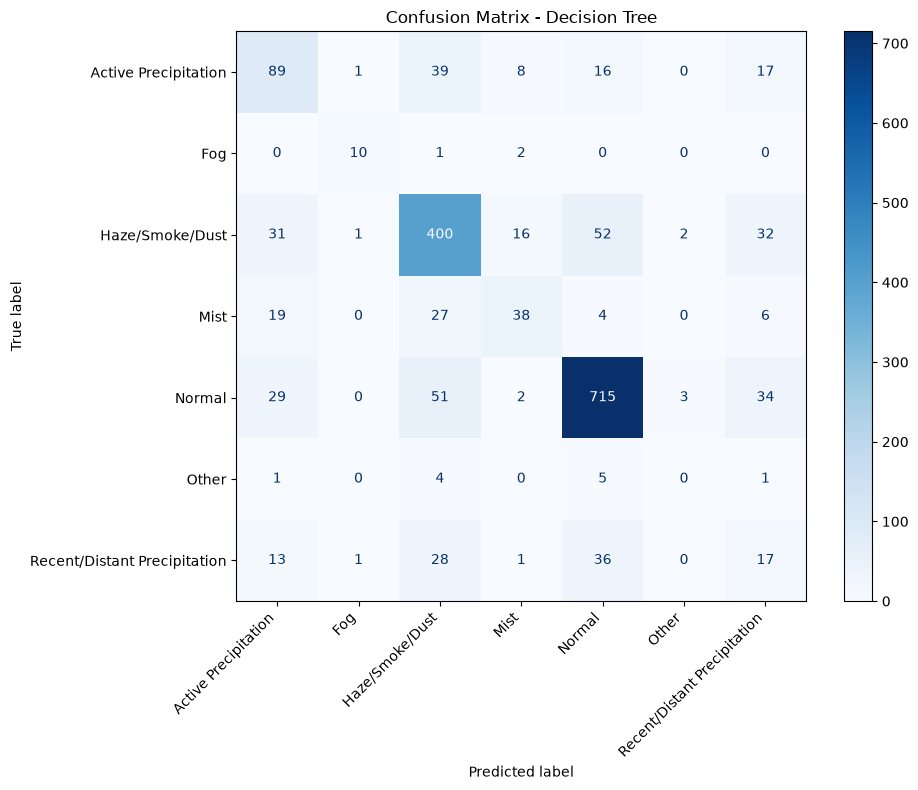

In [191]:
fig, ax = plt.subplots(figsize=(10, 8))
disp.plot(cmap='Blues', values_format='d', ax=ax)
plt.title('Confusion Matrix - Decision Tree')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [192]:
cm_dt_df = pd.DataFrame(cm_dt, index=target_names, columns=target_names)
cm_dt_df.index.name = 'Actual'
cm_dt_df.columns.name = 'Predicted'
display(cm_dt_df)

Predicted,Active Precipitation,Fog,Haze/Smoke/Dust,Mist,Normal,Other,Recent/Distant Precipitation
Actual,,,,,,,
Active Precipitation,89,1,39,8,16,0,17
Fog,0,10,1,2,0,0,0
Haze/Smoke/Dust,31,1,400,16,52,2,32
Mist,19,0,27,38,4,0,6
Normal,29,0,51,2,715,3,34
Other,1,0,4,0,5,0,1
Recent/Distant Precipitation,13,1,28,1,36,0,17


**RANDOM FOREST**

In [193]:
cm_rf = confusion_matrix(y_test, y_pred_rf, labels=class_labels)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_rf,
    display_labels=target_names
)

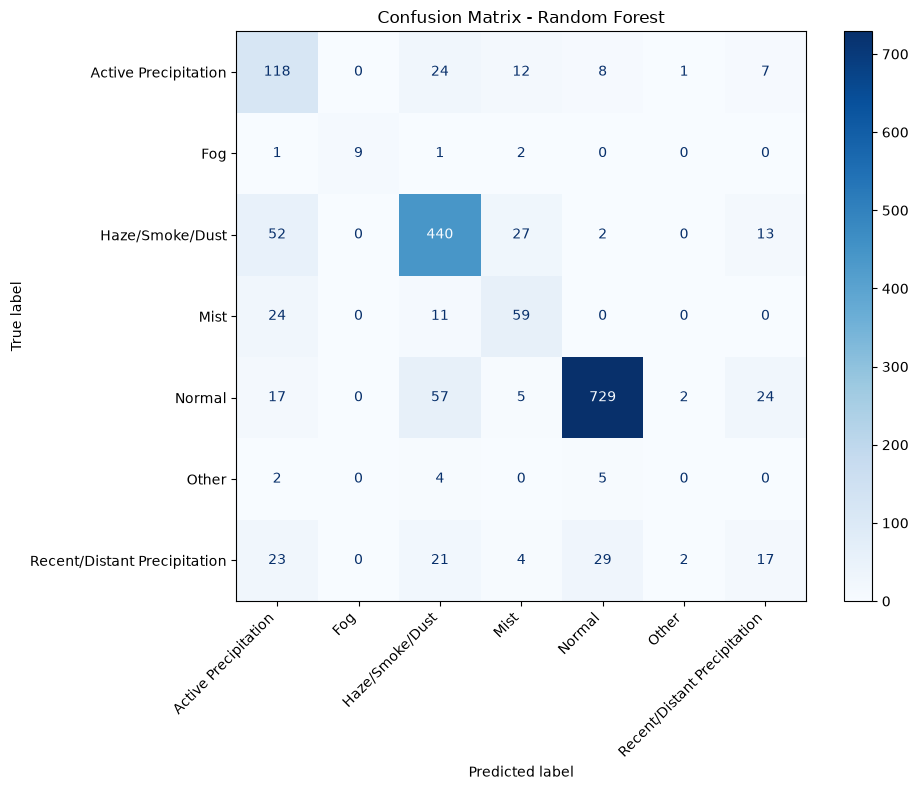

In [194]:
fig, ax = plt.subplots(figsize=(10, 8))
disp.plot(cmap='Blues', values_format='d', ax=ax)
plt.title('Confusion Matrix - Random Forest')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [195]:
cm_rf_df = pd.DataFrame(cm_rf, index=target_names, columns=target_names)
cm_rf_df.index.name = 'Actual'
cm_rf_df.columns.name = 'Predicted'
display(cm_rf_df)

Predicted,Active Precipitation,Fog,Haze/Smoke/Dust,Mist,Normal,Other,Recent/Distant Precipitation
Actual,,,,,,,
Active Precipitation,118,0,24,12,8,1,7
Fog,1,9,1,2,0,0,0
Haze/Smoke/Dust,52,0,440,27,2,0,13
Mist,24,0,11,59,0,0,0
Normal,17,0,57,5,729,2,24
Other,2,0,4,0,5,0,0
Recent/Distant Precipitation,23,0,21,4,29,2,17


**XGBOOST**

In [196]:
cm_xgb = confusion_matrix(y_test, y_pred_xgb, labels=class_labels)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_xgb,
    display_labels=target_names
)

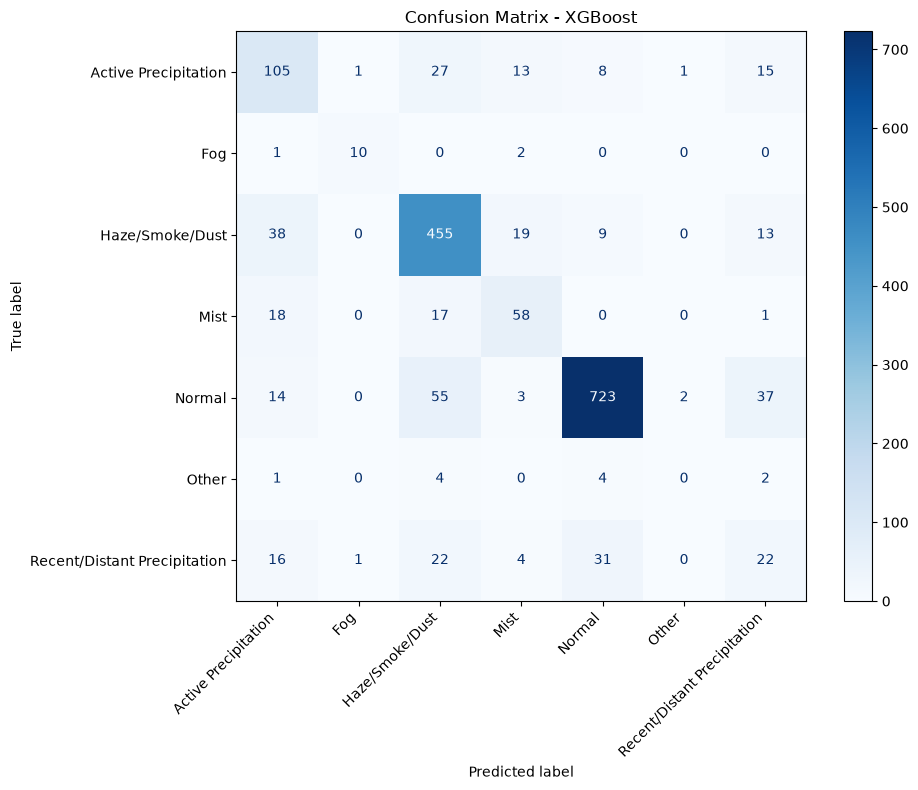

In [197]:
fig, ax = plt.subplots(figsize=(10, 8))
disp.plot(cmap='Blues', values_format='d', ax=ax)
plt.title('Confusion Matrix - XGBoost')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [198]:
cm_xgb_df = pd.DataFrame(cm_xgb, index=target_names, columns=target_names)
cm_xgb_df.index.name = 'Actual'
cm_xgb_df.columns.name = 'Predicted'
display(cm_xgb_df)

Predicted,Active Precipitation,Fog,Haze/Smoke/Dust,Mist,Normal,Other,Recent/Distant Precipitation
Actual,,,,,,,
Active Precipitation,105,1,27,13,8,1,15
Fog,1,10,0,2,0,0,0
Haze/Smoke/Dust,38,0,455,19,9,0,13
Mist,18,0,17,58,0,0,1
Normal,14,0,55,3,723,2,37
Other,1,0,4,0,4,0,2
Recent/Distant Precipitation,16,1,22,4,31,0,22


**LIGHTGBM**

In [199]:
cm_lgbm = confusion_matrix(y_test, y_pred_lgbm, labels=class_labels)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_lgbm,
    display_labels=target_names
)

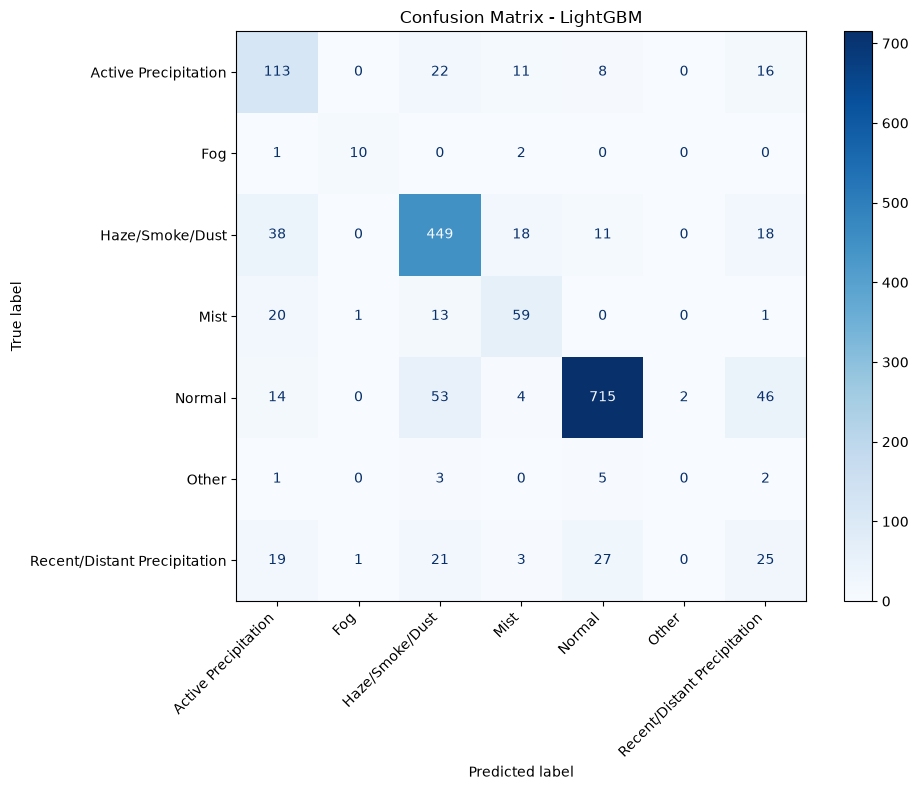

In [200]:
fig, ax = plt.subplots(figsize=(10, 8))
disp.plot(cmap='Blues', values_format='d', ax=ax)
plt.title('Confusion Matrix - LightGBM')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [201]:
cm_lgbm_df = pd.DataFrame(cm_lgbm, index=target_names, columns=target_names)
cm_lgbm_df.index.name = 'Actual'
cm_lgbm_df.columns.name = 'Predicted'
display(cm_lgbm_df)

Predicted,Active Precipitation,Fog,Haze/Smoke/Dust,Mist,Normal,Other,Recent/Distant Precipitation
Actual,,,,,,,
Active Precipitation,113,0,22,11,8,0,16
Fog,1,10,0,2,0,0,0
Haze/Smoke/Dust,38,0,449,18,11,0,18
Mist,20,1,13,59,0,0,1
Normal,14,0,53,4,715,2,46
Other,1,0,3,0,5,0,2
Recent/Distant Precipitation,19,1,21,3,27,0,25


**Notes:**

- Berdasarkan jumlah prediksi benar pada diagonal utama (*confusion matrix*), ketiga model *ensemble* mencatatkan hasil yang sangat berdekatan: **XGBoost (`1.373` dari `1.752` data uji)**, **Random Forest (`1.372` data)**, dan **LightGBM (`1.371` data)**, sedangkan **Decision Tree** tunggal memperoleh **`1.269` data**.
- **Kelas dengan pemisahan paling stabil:** `Normal` (`715–729` benar dari `834` data) dan `Haze/Smoke/Dust` (`400–455` benar dari `534` data) dikenali dengan baik oleh seluruh model, meskipun masih terjadi tumpang tindih dua arah antara keduanya (`51–57` sampel aktual `Normal` terprediksi sebagai `Haze/Smoke/Dust`).
- **Performa pada kelas minoritas `Fog` (`13` sampel uji):** Decision Tree, XGBoost, dan LightGBM sama-sama mengenali **`10` dari `13` observasi `Fog`** dengan tepat, sementara Random Forest mengenali **`9` dari `13` observasi** tanpa menghasilkan satu pun *false positive* (`precision = 1,00`). Kesalahan prediksi pada `Fog` umumnya bergeser ke kelas `Mist` (`2` sampel pada seluruh model) yang memiliki kemiripan kondisi kelembapan tinggi dan penurunan jarak pandang.
- **Pola kesalahan pada kelompok hujan (`Active Precipitation` & `Recent/Distant Precipitation`):**
  - `Active Precipitation` (`170` sampel) paling banyak dikenali oleh Random Forest (`118` benar) dan LightGBM (`113` benar), namun sebagian masih tertukar dengan `Haze/Smoke/Dust` (`22–39` sampel) dan `Recent/Distant Precipitation` (`7–17` sampel).
  - `Recent/Distant Precipitation` (`96` sampel) menjadi salah satu kelas yang paling sulit dipisahkan: hanya `17–25` sampel yang terprediksi benar, sementara sisanya tersebar merata ke `Normal` (`27–36` sampel), `Haze/Smoke/Dust` (`21–28` sampel), dan `Active Precipitation` (`13–23` sampel). Hal ini wajar secara meteorologis karena hujan yang baru berlalu atau berada di kejauhan sering kali tidak lagi tercatat pada curah hujan stasiun saat jam pengamatan berlangsung.
- **Permasalahan kelas `Other` (`11` sampel):** Seluruh model gagal mengenali satu pun observasi aktual `Other` (`0` benar), dan mayoritas justru diklasifikasikan sebagai `Normal` (`4–5` sampel) serta `Haze/Smoke/Dust` (`3–4` sampel). Meskipun model sempat menghasilkan total `2–5` prediksi berlabel `Other`, seluruhnya merupakan *false positive* pada kelas lain. Kondisi ini disebabkan oleh sifat kelas `Other` yang merupakan kategori gabungan dari berbagai fenomena cuaca yang jarang terjadi dan tidak memiliki karakteristik meteorologi yang homogen.

### Model Comparison

Merangkum metrik evaluasi utama serta nilai *F1-Score* pada kelas-kelas menantang (kelas minoritas dan kelompok hujan) dari keempat model *baseline* ke dalam satu tabel perbandingan guna menentukan kandidat model terbaik sebelum memasuki tahap optimasi (*hyperparameter tuning*).

In [202]:
preds = {
    'Decision Tree': y_pred_dt,
    'Random Forest': y_pred_rf,
    'XGBoost': y_pred_xgb,
    'LightGBM': y_pred_lgbm
}

In [203]:
rows = {}

for name, y_pred in preds.items():
    report = classification_report(
        y_test,
        y_pred,
        labels=class_labels,
        target_names=target_names,
        output_dict=True,
        zero_division=0
    )

    rows[name] = {
        'Accuracy': accuracy_score(y_test, y_pred),
        'Macro F1': f1_score(y_test, y_pred, average='macro', zero_division=0),
        'Balanced Accuracy': balanced_accuracy_score(y_test, y_pred),
        'Fog F1': report['Fog']['f1-score'],
        'Mist F1': report['Mist']['f1-score'],
        'Other F1': report['Other']['f1-score'],
        'Active Precip F1': report['Active Precipitation']['f1-score'],
        'Recent/Distant Precip F1': report['Recent/Distant Precipitation']['f1-score']
    }

In [204]:
comparison_df = pd.DataFrame(rows).T
display(comparison_df.round(4))

,Accuracy,Macro F1,Balanced Accuracy,Fog F1,Mist F1,Other F1,Active Precip F1,Recent/Distant Precip F1
Decision Tree,0.7243,0.5018,0.4972,0.7692,0.4720,0.0,0.5057,0.1675
Random Forest,0.7831,0.5584,0.5556,0.8182,0.5813,0.0,0.5799,0.2166
XGBoost,0.7837,0.5617,0.5646,0.8000,0.6010,0.0,0.5785,0.2366
LightGBM,0.7825,0.5683,0.5743,0.8000,0.6178,0.0,0.6011,0.2451


**Notes:**

- Secara keseluruhan, ketiga algoritma *ensemble* (**LightGBM**, **XGBoost**, dan **Random Forest**) jauh mengungguli **Decision Tree** tunggal di seluruh metrik evaluasi, dengan peningkatan *Accuracy* sekitar `5,8%–5,9%` (`0,7243` menjadi `0,7825–0,7837`) dan peningkatan *Macro F1-Score* sebesar `0,0566–0,0665` (`0,5018` menjadi `0,5584–0,5683`).
- **LightGBM** mencatatkan performa paling seimbang pada tahap *baseline* dengan **Macro F1-Score (`0,5683`)** dan **Balanced Accuracy (`0,5743`)** tertinggi, serta unggul pada tiga kelas menantang sekaligus: `Mist` (`0,6178`), `Active Precipitation` (`0,6011`), dan `Recent/Distant Precipitation` (`0,2451`).
- **XGBoost** menempati posisi kedua pada *Macro F1-Score* (`0,5617`) dan *Balanced Accuracy* (`0,5646`) dengan nilai *Accuracy* tertinggi (`0,7837`), sedangkan **Random Forest** (`Macro F1 = 0,5584`) unggul pada kelas minoritas `Fog` (`F1 = 0,8182`).
- Meskipun performa model *ensemble* sudah solid pada kelas mayoritas dan `Fog`, terdapat **tiga temuan utama** yang menjadi fokus perbaikan pada tahap berikutnya:
  1. Seluruh model masih gagal mengenali kelas **`Other` (`F1 = 0,0000`)**.
  2. Pemisahan kelas **`Recent/Distant Precipitation` (`F1 = 0,1675–0,2451`)** masih rendah karena kemiripan karakteristik atmosfer permukaan dengan kondisi `Normal`, `Haze/Smoke/Dust`, dan `Active Precipitation`.
  3. Masih terdapat kesenjangan performa yang lebar antara data latih (`Macro F1 = 0,9718–1,0000`) dan data uji (`0,5018–0,5683`) yang mengindikasikan *overfitting*.

# 10. Model Selection

Tahap ini memilih kandidat algoritma terbaik berdasarkan evaluasi **Stratified Group Cross-Validation (5-Fold)** dan evaluasi **Out-of-Fold (OOF)** pada data latih (`X_train`, `y_train` sebanyak `7.008` observasi). Seluruh proses validasi dilakukan tanpa menyentuh data uji (`X_test`, `y_test`) agar keputusan pemilihan model bebas dari kebocoran informasi (*data leakage*).

## 10.1 Cross Validation Comparison

Membandingkan performa dan kestabilan keempat algoritma (*Decision Tree*, *Random Forest*, *XGBoost*, dan *LightGBM*) menggunakan **5-Fold StratifiedGroupKFold** berdasarkan kolom `date` pada `train_df`. Pengelompokan berdasarkan tanggal memastikan seluruh observasi jam dalam hari yang sama selalu berada pada *fold* pelatihan atau validasi yang sama. Bobot kelas dihitung ulang di dalam setiap *fold* pelatihan agar evaluasi validasi tetap objektif.

In [205]:
cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [206]:
cv_splits = list(
    cv.split(
        X_train,
        y_train,
        groups=train_df['date']
    )
)
print(f"Jumlah fold : {len(cv_splits)}")

Jumlah fold : 5


In [207]:
for fold, (tr_idx, val_idx) in enumerate(cv_splits, start=1):
    print(f"Fold {fold} -> Train: {len(tr_idx)} baris | Val: {len(val_idx)} baris")

Fold 1 -> Train: 5592 baris | Val: 1416 baris
Fold 2 -> Train: 5640 baris | Val: 1368 baris
Fold 3 -> Train: 5599 baris | Val: 1409 baris
Fold 4 -> Train: 5616 baris | Val: 1392 baris
Fold 5 -> Train: 5585 baris | Val: 1423 baris


In [208]:
candidates = {
    'Decision Tree': dt_model,
    'Random Forest': rf_model,
    'XGBoost': xgb_model,
    'LightGBM': lgbm_model
}

In [209]:
n_classes = len(label_map)
class_labels = list(range(n_classes))

In [210]:
cv_results = []

for name, model in candidates.items():
    fold_scores = []

    for fold, (tr_idx, val_idx) in enumerate(cv_splits, start=1):
        X_tr = X_train.iloc[tr_idx]
        X_val = X_train.iloc[val_idx]
        y_tr = y_train.iloc[tr_idx]
        y_val = y_train.iloc[val_idx]

        # Clone model agar setiap fold dilatih dari awal
        m = clone(model)

        # Hitung class weight khusus pada data latih fold ini
        fold_classes = np.unique(y_tr)
        weights = compute_class_weight(
            class_weight='balanced',
            classes=fold_classes,
            y=y_tr
        )
        fold_class_weights = dict(zip(fold_classes, weights))

        if name == 'XGBoost':
            sample_weights = y_tr.map(fold_class_weights)
            m.fit(X_tr, y_tr, sample_weight=sample_weights)
        else:
            m.set_params(class_weight=fold_class_weights)
            m.fit(X_tr, y_tr)

        y_val_pred = m.predict(X_val)

        score = f1_score(
            y_val,
            y_val_pred,
            labels=class_labels,
            average='macro',
            zero_division=0
        )
        fold_scores.append(score)

        print(f"{name:<15} | Fold {fold}: Macro F1 = {score:.4f}")

    cv_results.append({
        'Model': name,
        'Macro F1 Mean': np.mean(fold_scores),
        'Macro F1 Std': np.std(fold_scores, ddof=1)
    })
    print("-" * 45)

Decision Tree   | Fold 1: Macro F1 = 0.4960
Decision Tree   | Fold 2: Macro F1 = 0.4853
Decision Tree   | Fold 3: Macro F1 = 0.5097
Decision Tree   | Fold 4: Macro F1 = 0.4955
Decision Tree   | Fold 5: Macro F1 = 0.4483
---------------------------------------------
Random Forest   | Fold 1: Macro F1 = 0.6096
Random Forest   | Fold 2: Macro F1 = 0.5504
Random Forest   | Fold 3: Macro F1 = 0.6062
Random Forest   | Fold 4: Macro F1 = 0.5588
Random Forest   | Fold 5: Macro F1 = 0.5478
---------------------------------------------
XGBoost         | Fold 1: Macro F1 = 0.5935
XGBoost         | Fold 2: Macro F1 = 0.5338
XGBoost         | Fold 3: Macro F1 = 0.5759
XGBoost         | Fold 4: Macro F1 = 0.5696
XGBoost         | Fold 5: Macro F1 = 0.5126
---------------------------------------------
LightGBM        | Fold 1: Macro F1 = 0.6005
LightGBM        | Fold 2: Macro F1 = 0.5527
LightGBM        | Fold 3: Macro F1 = 0.5719
LightGBM        | Fold 4: Macro F1 = 0.5583
LightGBM        | Fold 5: 

In [211]:
cv_comparison_df = (
    pd.DataFrame(cv_results)
    .set_index('Model')
    .sort_values('Macro F1 Mean', ascending=False)
)
display(cv_comparison_df.round(4))

,Macro F1 Mean,Macro F1 Std
Model,,
Random Forest,0.5746,0.0307
LightGBM,0.5598,0.0308
XGBoost,0.5571,0.0330
Decision Tree,0.4870,0.0233


**Notes:**

- Berdasarkan hasil evaluasi **5-Fold StratifiedGroupKFold** pada data latih (`7.008` observasi), **Random Forest** memperoleh rata-rata *Macro F1-Score* tertinggi sebesar **`0,5746` (`± 0,0307`)**, mengungguli **LightGBM (`0,5598 ± 0,0308`)** dan **XGBoost (`0,5571 ± 0,0330`)**.
- Ketiga algoritma *ensemble* menunjukkan tingkat kestabilan antar-*fold* yang relatif sebanding (standar deviasi berkisar antara `0,0307` hingga `0,0330`), di mana **Random Forest** (`0,0307`) dan **LightGBM** (`0,0308`) sedikit lebih konsisten dibandingkan **XGBoost** (`0,0330`).
- **Decision Tree** tunggal mencatat nilai standar deviasi terkecil (`0,0233`), namun rata-rata *Macro F1-Score*-nya terpaut cukup jauh di bawah model *ensemble*, yakni hanya **`0,4870`** (tertinggi `0,5097` pada *Fold* 3 dan terendah `0,4483` pada *Fold* 5).
- Seluruh model mengalami penurunan skor pada *Fold* 5 (`0,4483–0,5478`), yang umumnya dipengaruhi oleh variasi komposisi sampel kelas minoritas (`Fog` dan `Other`) pada kelompok tanggal yang masuk ke dalam masing-masing lipatan validasi.

## 10.2 Out-of-Fold Per-Class Evaluation

Mengevaluasi kemampuan setiap model dalam mengenali masing-masing dari **7 kelas fenomena meteorologi** menggunakan prediksi *out-of-fold* (OOF) yang menggabungkan hasil validasi dari seluruh 5 *fold* pada data latih (`7.008` observasi). Pendekatan ini memberikan gambaran performa per kelas dengan cakupan sampel yang jauh lebih besar (terutama untuk kelas minoritas seperti `Fog` dengan `37` sampel dan `Other` dengan `43` sampel) tanpa menyentuh data uji.

In [212]:
oof_predictions = {}

for name, model in candidates.items():
    oof_pred = np.full(len(y_train), -1, dtype=int)

    for fold, (tr_idx, val_idx) in enumerate(cv_splits, start=1):
        X_tr = X_train.iloc[tr_idx]
        X_val = X_train.iloc[val_idx]
        y_tr = y_train.iloc[tr_idx]

        # Clone model agar setiap fold dilatih secara independen
        m = clone(model)

        # Hitung class weight khusus pada fold pelatihan
        fold_classes = np.unique(y_tr)
        weights = compute_class_weight(
            class_weight='balanced',
            classes=fold_classes,
            y=y_tr
        )
        fold_class_weights = dict(zip(fold_classes, weights))

        if name == 'XGBoost':
            sample_weights = y_tr.map(fold_class_weights)
            m.fit(X_tr, y_tr, sample_weight=sample_weights)
        else:
            m.set_params(class_weight=fold_class_weights)
            m.fit(X_tr, y_tr)

        oof_pred[val_idx] = m.predict(X_val)

    # Pastikan seluruh 7.008 baris latih telah menerima prediksi OOF
    assert np.all(oof_pred != -1), f"Masih ada indeks yang belum terprediksi pada {name}!"
    oof_predictions[name] = oof_pred
    print(f"{name:<15}: OOF prediction selesai ({len(oof_pred)} baris)")

Decision Tree  : OOF prediction selesai (7008 baris)
Random Forest  : OOF prediction selesai (7008 baris)
XGBoost        : OOF prediction selesai (7008 baris)
LightGBM       : OOF prediction selesai (7008 baris)


In [213]:
oof_results = []
class_names = [inv_label_map[i] for i in range(n_classes)]

for name, y_pred in oof_predictions.items():
    report = classification_report(
        y_train,
        y_pred,
        labels=class_labels,
        target_names=class_names,
        output_dict=True,
        zero_division=0
    )

    for class_name in class_names:
        oof_results.append({
            'Model': name,
            'Class': class_name,
            'Precision': report[class_name]['precision'],
            'Recall': report[class_name]['recall'],
            'F1-Score': report[class_name]['f1-score'],
            'Support': int(report[class_name]['support'])
        })

oof_comparison_df = pd.DataFrame(oof_results)
display(
    oof_comparison_df
    .set_index(['Model', 'Class'])
    .round(4)
)

Precision  Recall  F1-Score  \
Model         Class                                                       
Decision Tree Active Precipitation             0.4254  0.4547    0.4396   
              Fog                              0.5854  0.6486    0.6154   
              Haze/Smoke/Dust                  0.7730  0.7666    0.7698   
              Mist                             0.5866  0.5452    0.5652   
              Normal                           0.8675  0.8639    0.8657   
              Other                            0.0357  0.0465    0.0404   
              Recent/Distant Precipitation     0.1295  0.1282    0.1289   
Random Forest Active Precipitation             0.5192  0.6562    0.5797   
              Fog                              0.8929  0.6757    0.7692   
              Haze/Smoke/Dust                  0.8323  0.8437    0.8379   
              Mist                             0.5786  0.8107    0.6753   
              Normal                           0.9373  0.8836    0.9096   
              Other                            0.0769  0.0233    0.0357   
              Recent/Distant Precipitation     0.2571  0.1846    0.2149   
XGBoost       Active Precipitation             0.5557  0.5688    0.5622   
              Fog                              0.7222  0.7027    0.7123   
              Haze/Smoke/Dust                  0.8071  0.8660    0.8355   
              Mist                             0.6416  0.6977    0.6685   
              Normal                           0.9241  0.8907    0.9071   
              Other                            0.0000  0.0000    0.0000   
              Recent/Distant Precipitation     0.2349  0.2000    0.2161   
LightGBM      Active Precipitation             0.5517  0.5922    0.5712   
              Fog                              0.7143  0.6757    0.6944   
              Haze/Smoke/Dust                  0.8169  0.8701    0.8426   
              Mist                             0.6483  0.6977    0.6721   
              Normal                           0.9290  0.8901    0.9091   
              Other                            0.0714  0.0233    0.0351   
              Recent/Distant Precipitation     0.2209  0.1949    0.2071   

                                            Support  
Model         Class                                  
Decision Tree Active Precipitation              640  
              Fog                                37  
              Haze/Smoke/Dust                  2194  
              Mist                              354  
              Normal                           3350  
              Other                              43  
              Recent/Distant Precipitation      390  
Random Forest Active Precipitation              640  
              Fog                                37  
              Haze/Smoke/Dust                  2194  
              Mist                              354  
              Normal                           3350  
              Other                              43  
              Recent/Distant Precipitation      390  
XGBoost       Active Precipitation              640  
              Fog                                37  
              Haze/Smoke/Dust                  2194  
              Mist                              354  
              Normal                           3350  
              Other                              43  
              Recent/Distant Precipitation      390  
LightGBM      Active Precipitation              640  
              Fog                                37  
              Haze/Smoke/Dust                  2194  
              Mist                              354  
              Normal                           3350  
              Other                              43  
              Recent/Distant Precipitation      390

**Ringkasan OOF Macro F1 keseluruhan untuk setiap model**

In [214]:
oof_macro_f1 = [
    {
        'Model': name,
        'OOF Macro F1': f1_score(
            y_train,
            y_pred,
            labels=class_labels,
            average='macro',
            zero_division=0
        )
    }
    for name, y_pred in oof_predictions.items()
]

oof_macro_f1_df = (
    pd.DataFrame(oof_macro_f1)
    .set_index('Model')
    .sort_values('OOF Macro F1', ascending=False)
)

display(oof_macro_f1_df.round(4))

,OOF Macro F1
Model,
Random Forest,0.5746
LightGBM,0.5617
XGBoost,0.5574
Decision Tree,0.4893


**Notes:**

- Berdasarkan evaluasi *Out-of-Fold* (OOF) secara menyeluruh pada `7.008` observasi data latih, **Random Forest** memperoleh **OOF Macro F1-Score tertinggi sebesar `0,5746`**, diikuti oleh **LightGBM (`0,5617`)** dan **XGBoost (`0,5574`)**, sedangkan **Decision Tree** tunggal tertinggal jauh di angka **`0,4893`**.
- **Keunggulan spesifik tiap model *ensemble* per kelas:**
  - **Random Forest** unggul pada empat kelas sekaligus, yakni `Normal` (`F1 = 0,9096`), kelas minoritas `Fog` (`F1 = 0,7692` dengan *precision* `0,8929`), `Mist` (`F1 = 0,6753` dengan *recall* tertinggi `0,8107`), serta `Active Precipitation` (`F1 = 0,5797`).
  - **LightGBM** mencatatkan performa tertinggi pada `Haze/Smoke/Dust` (`F1 = 0,8426`) dan bersaing sangat ketat dengan Random Forest pada `Normal` (`0,9091`), `Mist` (`0,6721`), dan `Active Precipitation` (`0,5712`).
  - **XGBoost** memperoleh *F1-Score* tertinggi pada `Recent/Distant Precipitation` (`0,2161`) serta nilai *recall* tertinggi pada kelas `Fog` (`0,7027`).
- **Tantangan yang masih konsisten di seluruh model:** Kelas **`Other` (`43` sampel)** tetap sangat sulit dikenali dengan *F1-Score* mendekati nol (`0,0357` pada Random Forest, `0,0351` pada LightGBM, `0,0404` pada Decision Tree, dan `0,0000` pada XGBoost), sementara **`Recent/Distant Precipitation` (`390` sampel)** masih bertahan di kisaran `F1 = 0,2071–0,2161` akibat tumpang tindih karakteristik parameter permukaan dengan kondisi cuaca lainnya.
- Selisih performa antara ketiga algoritma *ensemble* relatif tipis (`0,0172` antara peringkat pertama dan ketiga), sehingga ketiganya layak untuk dioptimasi lebih lanjut.

## 10.3 Model Selection Decision

Menetapkan kandidat model yang akan dilanjutkan ke tahap *hyperparameter tuning* berdasarkan rata-rata dan kestabilan *Macro F1-Score* pada **5-Fold StratifiedGroupKFold** serta kinerja per kelas pada evaluasi **Out-of-Fold (OOF)**.

**Notes:**

- Ketiga algoritma *ensemble* (**Random Forest**, **LightGBM**, dan **XGBoost**) menunjukkan performa yang kompetitif dan jauh melampaui **Decision Tree** tunggal, baik pada rata-rata *Cross-Validation* maupun evaluasi *Out-of-Fold*.
- **Random Forest** menempati peringkat pertama pada rata-rata *CV Macro F1-Score* (`0,5746 ± 0,0307`) dan *OOF Macro F1-Score* (`0,5746`), sekaligus unggul pada kelas `Normal`, `Fog`, `Mist`, dan `Active Precipitation`.
- **LightGBM** (`CV Macro F1 = 0,5598 ± 0,0308`; `OOF Macro F1 = 0,5617`) unggul pada kelas `Haze/Smoke/Dust` serta memiliki potensi peningkatan yang besar melalui pengaturan parameter kompleksitas pohon dan *learning rate*.
- **XGBoost** (`CV Macro F1 = 0,5571 ± 0,0330`; `OOF Macro F1 = 0,5574`) memberikan performa kompetitif pada `Recent/Distant Precipitation` dan *recall* kelas `Fog`.
- **Decision Tree** tidak dilanjutkan ke tahap optimasi karena memiliki rata-rata *CV Macro F1-Score* (`0,4870`) dan *OOF Macro F1-Score* (`0,4893`) yang terpaut sekitar `0,07–0,09` di bawah ketiga model *ensemble*, sehingga hanya dipertahankan sebagai acuan *single-tree baseline*.
- Dengan demikian, **Random Forest, LightGBM, dan XGBoost** dipilih untuk masuk ke tahap **Hyperparameter Tuning**. Model terbaik hasil *tuning* akan dipilih berdasarkan rata-rata *Macro F1-Score* pada *5-Fold StratifiedGroupKFold*, kemudian dievaluasi satu kali secara final pada data uji (`X_test`, `y_test`).

| Model | CV Macro F1 (Mean ± Std) | OOF Macro F1 | Keputusan |
| :--- | :---: | :---: | :--- |
| **Random Forest** | `0,5746 ± 0,0307` | `0,5746` | Dilanjutkan ke *Hyperparameter Tuning* |
| **LightGBM** | `0,5598 ± 0,0308` | `0,5617` | Dilanjutkan ke *Hyperparameter Tuning* |
| **XGBoost** | `0,5571 ± 0,0330` | `0,5574` | Dilanjutkan ke *Hyperparameter Tuning* |
| **Decision Tree** | `0,4870 ± 0,0233` | `0,4893` | Tidak dilanjutkan (dipertahankan sebagai *baseline*) |

# 11. Hyperparameter Tuning

Tahap ini melakukan optimasi *hyperparameter* pada ketiga kandidat algoritma *ensemble* terpilih dari Bab 10 (**Random Forest**, **LightGBM**, dan **XGBoost**) untuk meningkatkan kemampuan klasifikasi pada **7 kelas fenomena meteorologi** sekaligus menekan indikasi *overfitting* yang teramati pada model *baseline*.

Proses pencarian dilakukan menggunakan **Randomized Search Cross-Validation (`RandomizedSearchCV`)** dengan skema **5-Fold StratifiedGroupKFold (`cv_splits`)** berdasarkan tanggal pengamatan dan **Macro F1-Score** sebagai metrik optimasi utama. Pembobotan kelas seimbang tetap diterapkan secara dinamis di dalam setiap *fold* pelatihan agar bebas dari kebocoran informasi (*data leakage*).

## 11.1 Define Search Space

Menentukan ruang distribusi *hyperparameter* untuk masing-masing algoritma dengan fokus pada pengendalian kompleksitas pohon, laju pembelajaran (*learning rate*), *subsampling*, dan regularisasi guna mengurangi selisih performa antara data latih dan data validasi:

- **Random Forest:** Mengatur jumlah pohon (`n_estimators`), membatasi kedalaman pohon (`max_depth`), menaikkan batas minimum sampel untuk pemisahan dan daun (`min_samples_split`, `min_samples_leaf`), serta mengatur proporsi fitur per pemisahan (`max_features`).
- **XGBoost:** Mengatur jumlah pohon (`n_estimators`), laju pembelajaran (`learning_rate`), kedalaman maksimum (`max_depth`), bobot minimum anak simpul (`min_child_weight`), proporsi sampel dan fitur (`subsample`, `colsample_bytree`), serta penalti regularisasi (`reg_lambda`, `gamma`).
- **LightGBM:** Mengatur jumlah iterasi (`n_estimators`), laju pembelajaran (`learning_rate`), jumlah maksimum daun (`num_leaves`), jumlah minimum sampel per daun (`min_child_samples`), *subsampling* baris dan fitur (`subsample`, `colsample_bytree`, `subsample_freq`), serta regularisasi L2 (`reg_lambda`).

### Random Forest

- `n_estimators`: jumlah pohon keputusan yang dibangun dalam model.
- `max_depth`: kedalaman maksimum setiap pohon. Pembatasan kedalaman membantu mengurangi kompleksitas model.
- `min_samples_leaf`: jumlah minimum sampel yang harus terdapat pada suatu leaf. Nilai lebih besar dapat menghasilkan struktur pohon yang lebih sederhana.
- `min_samples_split`: jumlah minimum sampel yang diperlukan untuk membagi suatu node.
- `max_features`: jumlah fitur yang dipertimbangkan ketika mencari pemisahan terbaik pada setiap node.

In [215]:
rf_param_dist = {
    'n_estimators': randint(200, 601),
    'max_depth': [8, 10, 12, 15, 18, 20, None],
    'min_samples_split': randint(2, 21),
    'min_samples_leaf': randint(1, 9),
    'max_features': [0.5, 0.7, 'sqrt', 1.0]
}

### XGBoost

- `n_estimators`: jumlah pohon yang dibangun secara bertahap.
- `learning_rate`: mengatur kontribusi setiap pohon baru terhadap model secara keseluruhan.
- `max_depth`: membatasi kedalaman pohon untuk mengendalikan kompleksitas model.
- `min_child_weight`: menentukan batas minimum bobot sampel pada child node agar suatu pemisahan dapat dilakukan.
- `subsample`: proporsi sampel training yang digunakan untuk membangun setiap pohon.
- `colsample_bytree`: proporsi fitur yang digunakan untuk membangun setiap pohon.
- `reg_lambda`: parameter regularisasi L2 yang membantu mengendalikan kompleksitas model.

In [216]:
xgb_param_dist = {
    'n_estimators': randint(200, 801),
    'learning_rate': loguniform(0.02, 0.1),
    'max_depth': randint(2, 6),
    'min_child_weight': randint(5, 41),
    'subsample': uniform(0.6, 0.4),
    'colsample_bytree': uniform(0.6, 0.4),
    'reg_lambda': loguniform(5, 50),
    'gamma': uniform(0, 2)
}

### LightGBM

- `n_estimators`: jumlah boosting iteration atau pohon yang dibangun.
- `learning_rate`: mengatur kontribusi setiap pohon baru dalam proses boosting.
- `num_leaves`: jumlah maksimum leaf dalam satu pohon. Parameter ini berpengaruh terhadap kompleksitas model.
- `min_child_samples`: jumlah minimum sampel yang harus terdapat pada setiap leaf.
- `subsample`: proporsi sampel training yang digunakan dalam setiap iterasi.
- `colsample_bytree`: proporsi fitur yang digunakan dalam pembangunan setiap pohon.
- `reg_lambda`: parameter regularisasi L2 untuk membantu mengurangi kompleksitas model.
- `subsample_freq`: frekuensi penerapan subsampling. Nilai `1` berarti subsampling dilakukan pada setiap iterasi boosting.

In [217]:
lgbm_param_dist = {
    'n_estimators': randint(200, 601),
    'learning_rate': loguniform(0.03, 0.2),
    'num_leaves': randint(15, 64),
    'min_child_samples': randint(10, 51),
    'subsample': uniform(0.6, 0.4),
    'colsample_bytree': uniform(0.6, 0.4),
    'reg_lambda': uniform(0, 10),
    'subsample_freq': [1]
}

## 11.2 Randomized Search CV

Melakukan pencarian kombinasi *hyperparameter* terbaik menggunakan `RandomizedSearchCV` dengan **`n_iter=50` kandidat acak** pada setiap model (`250` total *fit* per algoritma pada 5 *fold*).

Untuk menjaga konsistensi penanganan ketidakseimbangan kelas pada seluruh algoritma, **Random Forest** dan **LightGBM** menggunakan `class_weight='balanced'` yang otomatis menghitung bobot berdasarkan proporsi label latih di tiap *fold*, sedangkan **XGBoost** dibungkus menggunakan `FoldBalancedXGBClassifier` agar perhitungan `sample_weight` juga dilakukan secara terisolasi di dalam masing-masing *fold* pelatihan.

In [218]:
class FoldBalancedXGBClassifier(BaseEstimator, ClassifierMixin):
    def __init__(self, estimator):
        self.estimator = estimator

    def fit(self, X, y):
        self.estimator_ = clone(self.estimator)
        fold_classes = np.unique(y)
        weights = compute_class_weight(
            class_weight='balanced',
            classes=fold_classes,
            y=y
        )
        weight_dict = dict(zip(fold_classes, weights))
        sample_weights = np.array([weight_dict[label] for label in y])

        self.estimator_.fit(X, y, sample_weight=sample_weights)
        self.classes_ = self.estimator_.classes_
        return self

    def predict(self, X):
        return self.estimator_.predict(X)

    def predict_proba(self, X):
        return self.estimator_.predict_proba(X)

In [219]:
search_configs = {
    'Random Forest': {
        'model': rf_model,
        'params': rf_param_dist
    },
    'XGBoost': {
        'model': xgb_model,
        'params': xgb_param_dist
    },
    'LightGBM': {
        'model': lgbm_model,
        'params': lgbm_param_dist
    }
}

In [220]:
search_results = {}
best_estimators = {}

for name, config in search_configs.items():
    print(f"\n{'='*55}")
    print(f"Hyperparameter Tuning: {name}")
    print(f"{'='*55}")

    model = clone(config['model'])
    param_dist = config['params'].copy()

    if name == 'XGBoost':
        base_model = clone(model)
        base_model.set_params(n_jobs=1)
        model = FoldBalancedXGBClassifier(estimator=base_model)
        param_dist = {
            f'estimator__{param}': values
            for param, values in param_dist.items()
        }
    else:
        model.set_params(
            class_weight='balanced',
            n_jobs=1
        )

    search = RandomizedSearchCV(
        estimator=model,
        param_distributions=param_dist,
        n_iter=50,
        scoring='f1_macro',
        cv=cv_splits,
        random_state=42,
        n_jobs=-1,
        refit=True,
        verbose=1,
        return_train_score=True
    )

    search.fit(X_train, y_train)

    search_results[name] = search
    best_estimators[name] = search.best_estimator_

    print(f"\nBest CV Macro F1 ({name}): {search.best_score_:.4f}")
    print("Best Parameters:")
    print(search.best_params_)


Hyperparameter Tuning: Random Forest
Fitting 5 folds for each of 50 candidates, totalling 250 fits

Best CV Macro F1 (Random Forest): 0.5633
Best Parameters:
{'max_depth': 12, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'min_samples_split': 4, 'n_estimators': 300}

Hyperparameter Tuning: XGBoost
Fitting 5 folds for each of 50 candidates, totalling 250 fits

Best CV Macro F1 (XGBoost): 0.5791
Best Parameters:
{'estimator__colsample_bytree': np.float64(0.8848716885390143), 'estimator__gamma': np.float64(0.47449817499360014), 'estimator__learning_rate': np.float64(0.03376561187594279), 'estimator__max_depth': 5, 'estimator__min_child_weight': 12, 'estimator__n_estimators': 334, 'estimator__reg_lambda': np.float64(26.297225385319994), 'estimator__subsample': np.float64(0.7232243167409557)}

Hyperparameter Tuning: LightGBM
Fitting 5 folds for each of 50 candidates, totalling 250 fits

Best CV Macro F1 (LightGBM): 0.5708
Best Parameters:
{'colsample_bytree': np.float64(0.9442922333025374

**Notes:**

- Setelah mengevaluasi `50` kombinasi *hyperparameter* (`250` total *fit* per model pada *5-Fold StratifiedGroupKFold*), **XGBoost** memperoleh rata-rata *CV Macro F1-Score* tertinggi sebesar **`0,5791`** (meningkat **`+0,0220`** dari skor *baseline* `0,5571`) dengan laju pembelajaran rendah (`learning_rate = 0,0338`), `max_depth = 5`, `n_estimators = 334`, serta regularisasi L2 yang kuat (`reg_lambda = 26,30`).
- **LightGBM** menempati peringkat kedua dengan rata-rata *CV Macro F1-Score* sebesar **`0,5708`** (meningkat **`+0,0110`** dari *baseline* `0,5598`), menggunakan konfigurasi `learning_rate = 0,0304`, `n_estimators = 336`, `num_leaves = 51`, dan `reg_lambda = 6,92`.
- Sebaliknya, **Random Forest** memperoleh skor terbaik pada ruang pencarian sebesar **`0,5633`** (`max_depth = 12`, `n_estimators = 300`, `min_samples_split = 4`), yang sedikit lebih rendah dibandingkan skor *baseline*-nya (`0,5746`). Hal ini menunjukkan bahwa pembatasan kedalaman pohon (`max_depth = 12`) pada kombinasi terpilih mengurangi sensitivitas model terhadap kelas minoritas.
- Perbandingan selisih skor latih-validasi (*train-validation gap*), kestabilan antar-*fold*, serta performa per kelas melalui evaluasi *Out-of-Fold* (OOF) akan dianalisis pada sub-bab berikutnya untuk menetapkan model terbaik sebelum menyentuh data uji.

## 11.3 Compare Tuned Models

**Perbandingan dengan baseline dan train-validation gap**

Membandingkan performa ketiga model hasil *tuning* terhadap skor *Cross-Validation* tahap *baseline* (Bab 10.1), standar deviasi antar-*fold* (`Std CV`), serta selisih antara skor rata-rata data latih (`Train F1`) dan data validasi (`Valid F1`) untuk menilai efektivitas regularisasi dalam menekan *overfitting*.

In [221]:
comparison_data = []

for name, search in search_results.items():
    results = search.cv_results_
    idx = search.best_index_

    # Ambil skor CV baseline langsung dari tabel Bab 10.1
    baseline_score = cv_comparison_df.loc[name, 'Macro F1 Mean']
    valid_score = search.best_score_
    train_score = results['mean_train_score'][idx]

    comparison_data.append({
        'Model': name,
        'Baseline CV Macro F1': baseline_score,
        'Tuned CV Macro F1': valid_score,
        'Improvement': valid_score - baseline_score,
        'Std CV': results['std_test_score'][idx],
        'Train F1': train_score,
        'Valid F1': valid_score,
        'Train-Valid Gap': train_score - valid_score
    })

tuning_comparison = (
    pd.DataFrame(comparison_data)
    .sort_values(by='Tuned CV Macro F1', ascending=False)
    .reset_index(drop=True)
)

display(tuning_comparison.round(4))

,Model,Baseline CV Macro F1,Tuned CV Macro F1,Improvement,Std CV,Train F1,Valid F1,Train-Valid Gap
0,XGBoost,0.5571,0.5791,0.0220,0.0363,0.7334,0.5791,0.1543
1,LightGBM,0.5598,0.5708,0.0110,0.0218,0.9439,0.5708,0.3731
2,Random Forest,0.5746,0.5633,-0.0113,0.0317,0.8790,0.5633,0.3158


**Perbandingan F1-score per kelas menggunakan OOF**

Mengevaluasi *F1-Score* hasil prediksi *out-of-fold* dari masing-masing model hasil *tuning* pada seluruh **7 kelas fenomena meteorologi** di data latih (`7.008` observasi) untuk melihat perubahan kemampuan deteksi per kelas sebelum menentukan model utama untuk evaluasi akhir pada data uji.

In [222]:
oof_tuned_predictions = {
    name: cross_val_predict(
        search.best_estimator_,
        X_train,
        y_train,
        cv=cv_splits,
        n_jobs=-1
    )
    for name, search in search_results.items()
}

n_classes = len(label_map)
class_labels = list(range(n_classes))
class_names = [inv_label_map[i] for i in range(n_classes)]

oof_tuned_comparison = pd.DataFrame({
    name: f1_score(
        y_train,
        predictions,
        average=None,
        labels=class_labels,
        zero_division=0
    )
    for name, predictions in oof_tuned_predictions.items()
}, index=class_names)

# Tambahkan baris rata-rata OOF Macro F1 di bagian bawah tabel
oof_tuned_comparison.loc['OOF Macro F1'] = [
    f1_score(y_train, oof_tuned_predictions[name], labels=class_labels, average='macro', zero_division=0)
    for name in oof_tuned_predictions.keys()
]

display(oof_tuned_comparison.round(4))

,Random Forest,XGBoost,LightGBM
Active Precipitation,0.5846,0.5776,0.5656
Fog,0.7647,0.7342,0.7297
Haze/Smoke/Dust,0.8192,0.8174,0.8394
Mist,0.6241,0.6452,0.6800
Normal,0.8968,0.8777,0.9081
Other,0.0222,0.1287,0.0494
Recent/Distant Precipitation,0.2280,0.2439,0.2177
OOF Macro F1,0.5628,0.5750,0.5700


**Notes:**

- **Peningkatan performa dan pengendalian *overfitting*:**
  - **XGBoost** mencatatkan peningkatan terbesar setelah *tuning* (**`+0,0220`**), naik dari *Baseline CV Macro F1* `0,5571` menjadi **`0,5791`** sekaligus meraih **OOF Macro F1 tertinggi sebesar `0,5750`**. Selain itu, kombinasi regularisasi (`reg_lambda = 26,30`, `gamma = 0,47`, `min_child_weight = 12`, dan `max_depth = 5`) berhasil menekan *Train-Validation Gap* secara drastis menjadi **`0,1543`** (`Train F1 = 0,7334` vs `Valid F1 = 0,5791`), jauh lebih rendah dibandingkan dua model lainnya.
  - **LightGBM** meningkat **`+0,0110`** menjadi **`0,5708`** (`OOF Macro F1 = 0,5700`) dengan variasi antar-*fold* paling kecil (`Std CV = 0,0218`), namun masih menyisakan selisih *Train-Validation Gap* yang cukup lebar sebesar **`0,3731`** (`Train F1 = 0,9439`).
  - **Random Forest** mengalami sedikit penurunan sebesar **`-0,0113`** dari skor *baseline*-nya (`0,5746` menjadi **`0,5633`**, `OOF Macro F1 = 0,5628`) dengan *Train-Validation Gap* sebesar **`0,3158`**, yang menandakan pembatasan `max_depth = 12` pada kandidat terpilih belum melampaui performa pohon tanpa batas kedalaman pada tahap *baseline*.
- **Perbandingan F1-Score per kelas (OOF):**
  - **XGBoost** unggul pada dua kelas yang paling sulit dipisahkan, yaitu **`Other` (`0,1287`)** dan **`Recent/Distant Precipitation` (`0,2439`)**, serta tetap kompetitif pada `Active Precipitation` (`0,5776`) dan `Fog` (`0,7342`).
  - **LightGBM** memperoleh *OOF F1-Score* tertinggi pada `Normal` (`0,9081`), `Haze/Smoke/Dust` (`0,8394`), dan `Mist` (`0,6800`).
  - **Random Forest** unggul pada kelas `Active Precipitation` (`0,5846`) dan kelas minoritas `Fog` (`0,7647`).
- **Keputusan Pemilihan Model Utama:** Sesuai kriteria pemilihan yang ditetapkan sebelum menyentuh data uji, **XGBoost ditetapkan sebagai model utama (*primary model*)** karena meraih rata-rata *CV Macro F1-Score* tertinggi (`0,5791`), *OOF Macro F1-Score* tertinggi (`0,5750`), serta generalisasi paling stabil (*Train-Validation Gap* terendah sebesar `0,1543`). Sementara itu, **LightGBM** dan **Random Forest** tetap disertakan sebagai **model pembanding (*comparison models*)** pada evaluasi akhir data uji.

## 11.4 Final Evaluation on Test Set

Tahap ini melakukan evaluasi akhir satu kali terhadap ketiga model hasil *hyperparameter tuning* menggunakan data uji (`X_test`, `y_test` sebanyak `1.752` observasi) yang sepenuhnya terpisah selama proses pelatihan dan optimasi. **XGBoost** dievaluasi sebagai **model utama**, sedangkan **LightGBM** dan **Random Forest** disertakan sebagai **model pembanding**. Pengukuran mencakup metrik keseluruhan (*Accuracy*, *Macro F1-Score*, *Balanced Accuracy*), laporan klasifikasi per kelas (*Classification Report*), serta matriks kebingungan (*Confusion Matrix*) untuk seluruh **7 kelas fenomena meteorologi**.

In [223]:
n_classes = len(label_map)
class_labels = list(range(n_classes))
class_names = [inv_label_map[i] for i in range(n_classes)]

test_predictions = {}
test_results = []

for name, search in search_results.items():
    model = search.best_estimator_
    y_pred = model.predict(X_test)
    test_predictions[name] = y_pred

    class_f1 = f1_score(
        y_test,
        y_pred,
        average=None,
        labels=class_labels,
        zero_division=0
    )

    test_results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Macro F1': f1_score(y_test, y_pred, average='macro', zero_division=0),
        'Balanced Accuracy': balanced_accuracy_score(y_test, y_pred),
        'Fog F1': class_f1[label_map['Fog']],
        'Mist F1': class_f1[label_map['Mist']],
        'Other F1': class_f1[label_map['Other']],
        'Active Precip F1': class_f1[label_map['Active Precipitation']],
        'Recent/Distant Precip F1': class_f1[label_map['Recent/Distant Precipitation']]
    })

test_comparison = (
    pd.DataFrame(test_results)
    .sort_values(by='Macro F1', ascending=False)
    .reset_index(drop=True)
)

display(test_comparison.round(4))

,Model,Accuracy,Macro F1,Balanced Accuracy,Fog F1,Mist F1,Other F1,Active Precip F1,Recent/Distant Precip F1
0,LightGBM,0.7877,0.5914,0.6069,0.8462,0.6029,0.0833,0.6021,0.2857
1,Random Forest,0.7614,0.5711,0.5945,0.8800,0.5617,0.0000,0.5928,0.2902
2,XGBoost,0.7392,0.5710,0.6367,0.7586,0.6034,0.1071,0.6011,0.2721


**Notes:**

- **Peningkatan dibanding tahap *baseline*:** Seluruh model hasil *hyperparameter tuning* berhasil meningkatkan **Macro F1-Score** dan **Balanced Accuracy** pada data uji dibandingkan konfigurasi *baseline*-nya (Bab 9.3):
  - **LightGBM** mencatatkan peningkatan *Macro F1-Score* terbesar sebesar **`+0,0231`** (`0,5683` menjadi **`0,5914`**), *Balanced Accuracy* naik **`+0,0326`** (`0,5743` menjadi **`0,6069`**), serta *Accuracy* meningkat menjadi **`0,7877`**.
  - **Random Forest** meningkatkan *Macro F1-Score* sebesar **`+0,0127`** (`0,5584` menjadi **`0,5711`**) dan *Balanced Accuracy* sebesar **`+0,0389`** (`0,5556` menjadi **`0,5945`**), disertai penurunan *Accuracy* dari `0,7831` menjadi `0,7614`.
  - **XGBoost** (model utama terpilih dari tahap validasi silang) meningkatkan *Macro F1-Score* sebesar **`+0,0093`** (`0,5617` menjadi **`0,5710`**) dan meraih **Balanced Accuracy tertinggi sebesar `0,6367`** (naik **`+0,0721`** dari `0,5646`), meskipun *Accuracy* keseluruhannya turun dari `0,7837` menjadi `0,7392` akibat peningkatan sensitivitas (*recall*) pada kelas minoritas dan kelas hujan.
- **Perbandingan antarmodel pada data uji:** **LightGBM** unggul pada *Macro F1-Score* (`0,5914`) dan *Accuracy* (`0,7877`), **Random Forest** unggul pada kelas minoritas `Fog` (`F1 = 0,8800`) dan `Recent/Distant Precipitation` (`F1 = 0,2902`), sedangkan **XGBoost** memimpin pada *Balanced Accuracy* (`0,6367`), `Mist` (`F1 = 0,6034`), serta `Other` (`F1 = 0,1071`).
- Sesuai protokol evaluasi yang ketat, **XGBoost** tetap dipertahankan sebagai **model utama** karena ditetapkan berdasarkan hasil *Cross-Validation* sebelum menyentuh data uji (mencegah bias pemilihan *post-hoc*), sementara **LightGBM** dan **Random Forest** menjadi **model pembanding** yang menunjukkan potensi generalisasi sangat kompetitif.

**CLASSIFICATION REPORT**

Menampilkan nilai *precision*, *recall*, dan *F1-Score* untuk masing-masing dari **7 kelas fenomena** pada data uji guna membandingkan kinerja rinci ketiga model hasil *tuning*.

In [224]:
for name, y_pred in test_predictions.items():
    print(f"\n{'='*65}")
    print(f"Classification Report (Tuned): {name}")
    print(f"{'='*65}")

    print(classification_report(
        y_test,
        y_pred,
        labels=class_labels,
        target_names=class_names,
        zero_division=0,
        digits=4
    ))


Classification Report (Tuned): Random Forest
                              precision    recall  f1-score   support

        Active Precipitation     0.5020    0.7235    0.5928       170
                         Fog     0.9167    0.8462    0.8800        13
             Haze/Smoke/Dust     0.8032    0.7566    0.7792       534
                        Mist     0.4681    0.7021    0.5617        94
                      Normal     0.9525    0.8417    0.8937       834
                       Other     0.0000    0.0000    0.0000        11
Recent/Distant Precipitation     0.2887    0.2917    0.2902        96

                    accuracy                         0.7614      1752
                   macro avg     0.5616    0.5945    0.5711      1752
                weighted avg     0.7947    0.7614    0.7730      1752


Classification Report (Tuned): XGBoost
                              precision    recall  f1-score   support

        Active Precipitation     0.5485    0.6647    0.6011       170


**Notes:**

- **Peningkatan deteksi kelas minoritas `Fog` (`13` sampel):** Ketiga model hasil *tuning* sama-sama mencapai ***recall* sebesar `0,8462`** (`11` dari `13` observasi `Fog` terdeteksi tepat, meningkat dari `9–10` observasi pada tahap *baseline*). **Random Forest** memperoleh *F1-Score* tertinggi pada kelas ini sebesar **`0,8800`** (*precision* `0,9167`), diikuti **LightGBM** sebesar **`0,8462`** (*precision* `0,8462`) dan **XGBoost** sebesar **`0,7586`** (*precision* `0,6875`).
- **Performa stabil pada kelas dominan:** `Normal` (`834` sampel) dan `Haze/Smoke/Dust` (`534` sampel) tetap menjadi dua kelas dengan performa terbaik pada seluruh model, dengan *F1-Score* tertinggi dicapai oleh **LightGBM** masing-masing sebesar **`0,9053`** dan **`0,8140`**.
- **Perbaikan pada kelas `Other` (`11` sampel) dan `Recent/Distant Precipitation` (`96` sampel):**
  - Berbeda dengan tahap *baseline* di mana seluruh model memperoleh *F1-Score* `0,0000` pada kelas `Other`, **XGBoost** berhasil mengenali sebagian sampel `Other` dengan *recall* **`0,2727`** (*F1-Score* **`0,1071`**) dan **LightGBM** dengan *recall* **`0,0909`** (*F1-Score* **`0,0833`**), meskipun nilai *precision*-nya masih rendah (`0,0667` dan `0,0769`) karena keragaman fenomena di dalam kategori `Other`.
  - Seluruh model juga mengalami kenaikan *F1-Score* pada kelas `Recent/Distant Precipitation` dibandingkan tahap *baseline* (`0,2166–0,2451` naik menjadi **`0,2721–0,2902`**), terutama didorong oleh peningkatan *recall* pada **XGBoost** (`0,3854`).

**CONFUSION MATRIX**

Memvisualisasikan perbandingan label aktual dan hasil prediksi pada data uji (`1.752` observasi) untuk ketiga model hasil *tuning* guna mengamati perubahan pola kesalahan klasifikasi setelah optimasi parameter.

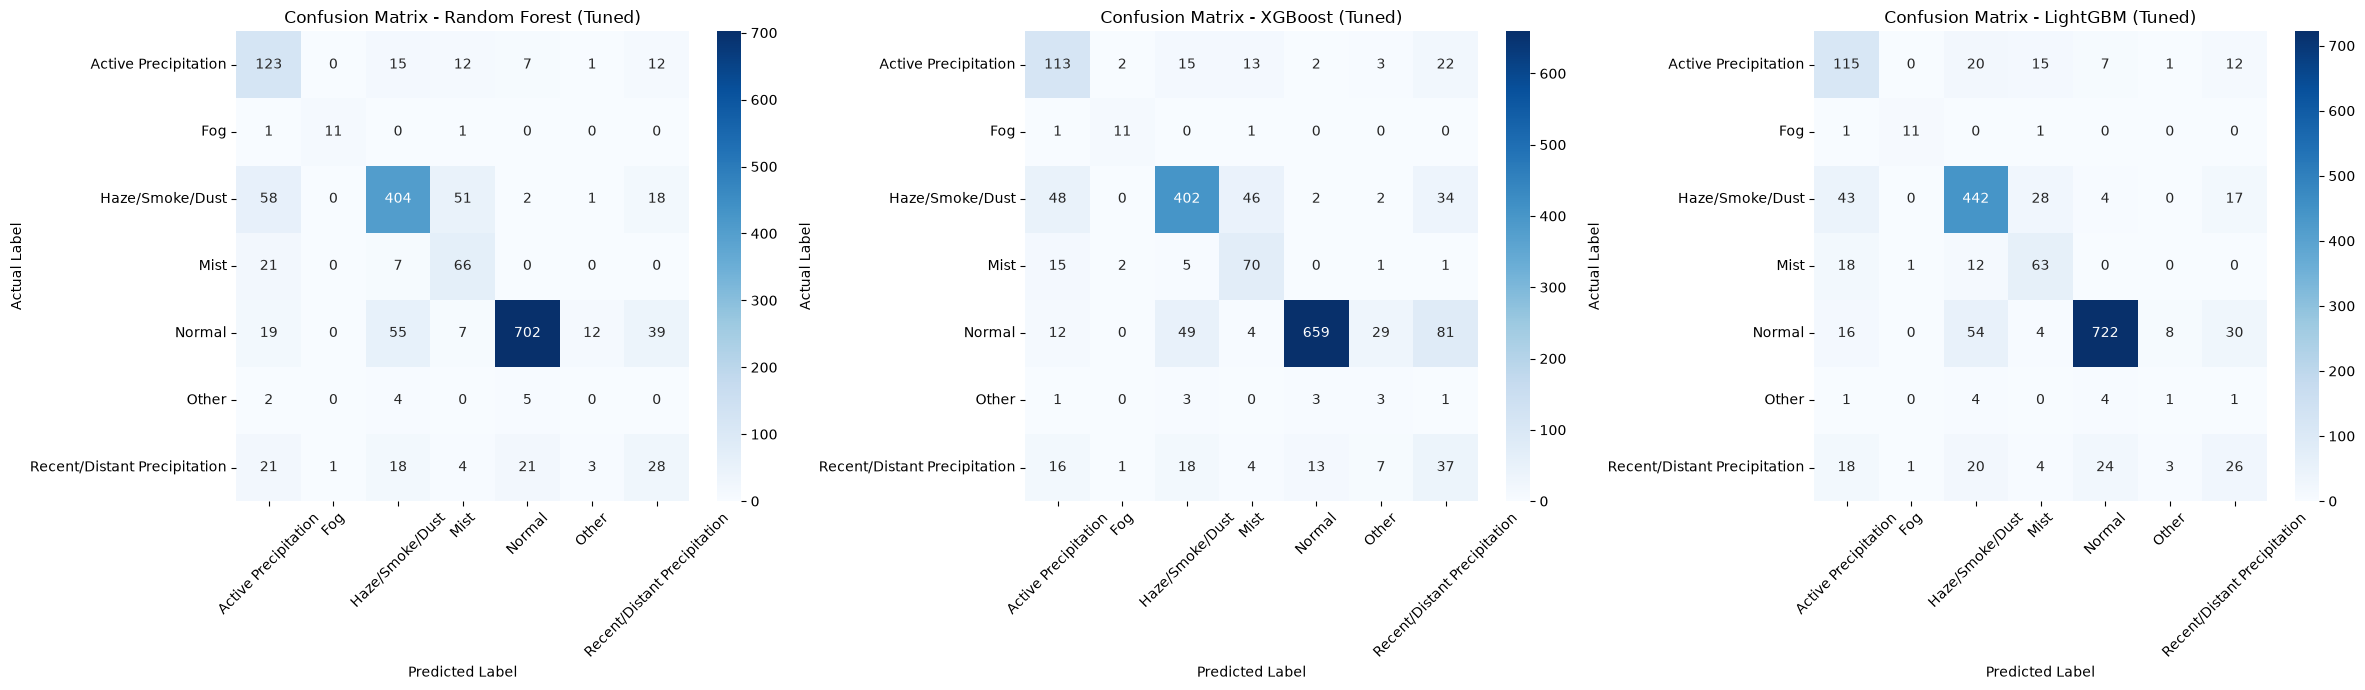

In [225]:
fig, axes = plt.subplots(1, 3, figsize=(24, 7))

for ax, (name, y_pred) in zip(axes, test_predictions.items()):
    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=class_labels
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=class_names,
        yticklabels=class_names,
        ax=ax
    )

    ax.set_title(f'Confusion Matrix - {name} (Tuned)')
    ax.set_xlabel('Predicted Label')
    ax.set_ylabel('Actual Label')
    ax.tick_params(axis='x', rotation=45)
    ax.tick_params(axis='y', rotation=0)

plt.tight_layout()
plt.show()

In [226]:
for name, y_pred in test_predictions.items():
    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=class_labels
    )

    cm_df = pd.DataFrame(
        cm,
        index=class_names,
        columns=class_names
    )
    cm_df.index.name = 'Actual'
    cm_df.columns.name = 'Predicted'

    print(f"\nConfusion Matrix (Tuned): {name}")
    display(cm_df)


Confusion Matrix (Tuned): Random Forest


Predicted,Active Precipitation,Fog,Haze/Smoke/Dust,Mist,Normal,Other,Recent/Distant Precipitation
Actual,,,,,,,
Active Precipitation,123,0,15,12,7,1,12
Fog,1,11,0,1,0,0,0
Haze/Smoke/Dust,58,0,404,51,2,1,18
Mist,21,0,7,66,0,0,0
Normal,19,0,55,7,702,12,39
Other,2,0,4,0,5,0,0
Recent/Distant Precipitation,21,1,18,4,21,3,28



Confusion Matrix (Tuned): XGBoost


Predicted,Active Precipitation,Fog,Haze/Smoke/Dust,Mist,Normal,Other,Recent/Distant Precipitation
Actual,,,,,,,
Active Precipitation,113,2,15,13,2,3,22
Fog,1,11,0,1,0,0,0
Haze/Smoke/Dust,48,0,402,46,2,2,34
Mist,15,2,5,70,0,1,1
Normal,12,0,49,4,659,29,81
Other,1,0,3,0,3,3,1
Recent/Distant Precipitation,16,1,18,4,13,7,37



Confusion Matrix (Tuned): LightGBM


Predicted,Active Precipitation,Fog,Haze/Smoke/Dust,Mist,Normal,Other,Recent/Distant Precipitation
Actual,,,,,,,
Active Precipitation,115,0,20,15,7,1,12
Fog,1,11,0,1,0,0,0
Haze/Smoke/Dust,43,0,442,28,4,0,17
Mist,18,1,12,63,0,0,0
Normal,16,0,54,4,722,8,30
Other,1,0,4,0,4,1,1
Recent/Distant Precipitation,18,1,20,4,24,3,26


**Notes:**

- **Total prediksi tepat pada diagonal utama:** **LightGBM** menghasilkan jumlah prediksi benar terbanyak pada data uji, yaitu **`1.380` dari `1.752` observasi** (meningkat dari `1.371` pada tahap *baseline*), diikuti **Random Forest** sebanyak **`1.334` observasi**, dan **XGBoost** sebanyak **`1.295` observasi**.
- **Trade-off antara sensitivitas kelas sulit dan kesalahan pada kelas `Normal`:**
  - **XGBoost** menangkap jumlah prediksi benar terbanyak pada kelas sulit, yakni **`37` dari `96`** observasi `Recent/Distant Precipitation`, **`70` dari `94`** observasi `Mist`, **`11` dari `13`** observasi `Fog`, serta **`3` dari `11`** observasi `Other`. Namun, tingginya pembobotan dan regularisasi menyebabkan sebagian observasi aktual `Normal` ikut terprediksi sebagai `Recent/Distant Precipitation` (`81` sampel) maupun `Other` (`29` sampel), sehingga menurunkan jumlah prediksi benar `Normal` menjadi `659` sampel.
  - **LightGBM** menjaga keseimbangan paling rapat antara presisi kelas mayoritas dan deteksi kelas minoritas: `722` benar pada `Normal`, `442` benar pada `Haze/Smoke/Dust`, `115` benar pada `Active Precipitation`, `63` benar pada `Mist`, serta `11` dari `13` benar pada `Fog`.
- **Pola kebingungan antarfenomena yang persisten:** Di seluruh model, kesalahan klasifikasi dua arah masih paling banyak terjadi antara `Haze/Smoke/Dust` dan `Active Precipitation` (`43–58` sampel aktual `Haze/Smoke/Dust` terprediksi sebagai `Active Precipitation`), serta antara `Recent/Distant Precipitation` dengan `Normal`, `Haze/Smoke/Dust`, dan `Active Precipitation`. Pola ini mencerminkan kemiripan kondisi kelembapan, suhu, dan jarak pandang permukaan saat transisi cuaca di stasiun pengamatan.

# 12. Feature Importance

Tahap ini dilakukan untuk mengidentifikasi kontribusi masing-masing dari **13 fitur masukan** dalam proses klasifikasi **7 fenomena meteorologi** pada **model utama terpilih (XGBoost hasil *hyperparameter tuning*)**. Analisis dilakukan menggunakan dua pendekatan yang saling melengkapi, yaitu **Model-Based Feature Importance (Gain)** bawaan XGBoost dan **Permutation Feature Importance** pada data uji.

## 12.1 Model-Based Feature Importance (Gain)

Analisis ini mengukur kontribusi setiap fitur berdasarkan nilai `feature_importances_` bawaan **XGBoost**, yang merepresentasikan rata-rata peningkatan akurasi pemisahan (*average gain*) yang dihasilkan suatu fitur setiap kali digunakan untuk membagi cabang (*split*) pada seluruh pohon keputusan. Semakin tinggi nilainya, semakin besar peran fitur tersebut dalam membentuk aturan pemisahan kelas selama pelatihan.

In [227]:
final_xgb = search_results['XGBoost'].best_estimator_

In [228]:
feature_importance = pd.DataFrame({
    'Feature': selected_features,
    'Gain Importance': final_xgb.estimator_.feature_importances_
})

In [229]:
feature_importance = (
    feature_importance
    .sort_values(by='Gain Importance', ascending=False)
    .reset_index(drop=True)
)
display(feature_importance.round(4))

,Feature,Gain Importance
0,visibility_vv,0.2459
1,relative_humidity_pc,0.1561
2,cloud_low_cover_oktas,0.0954
3,cloud_med_cover_oktas,0.0812
4,hour_cos,0.0797
5,temp_dewpoint_c_tdtdtd,0.0582
6,temp_drybulb_c_tttttt,0.0495
7,hour_sin,0.0454
8,wind_speed_ff,0.0432
9,pressure_qff_mb_derived,0.0409


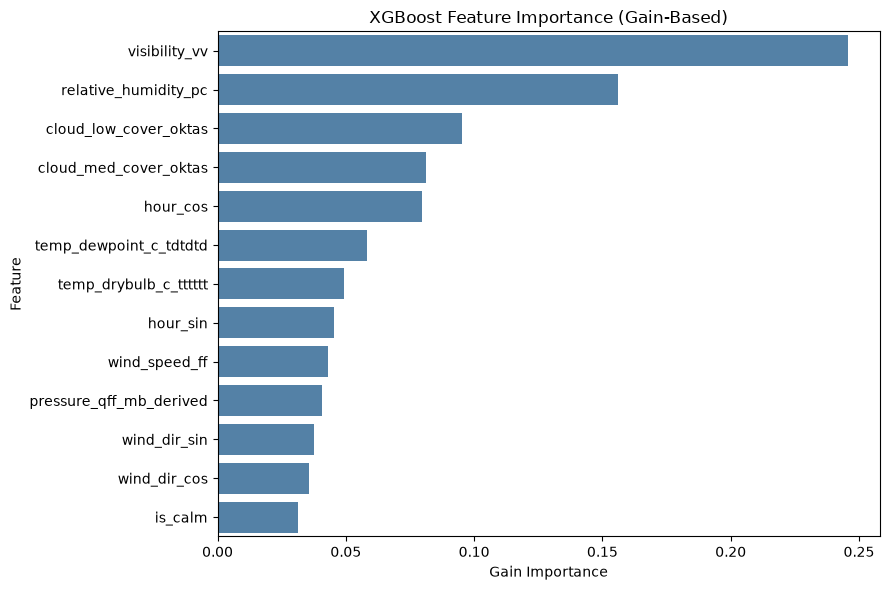

In [230]:
plt.figure(figsize=(9, 6))
sns.barplot(
    data=feature_importance,
    x='Gain Importance',
    y='Feature',
    color='steelblue'
)
plt.title('XGBoost Feature Importance (Gain-Based)')
plt.xlabel('Gain Importance')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

**Notes:**

- **`visibility_vv` menempati peringkat pertama dengan nilai *Gain Importance* tertinggi sebesar `0,2459`**, menjadikannya variabel paling berpengaruh dalam membentuk aturan pemisahan kelas pada pohon keputusan XGBoost. Hasil ini sejalan dengan definisi operasional fenomena *visibility* yang secara langsung membatasi jarak pandang horizontal.
- **Parameter kelembapan dan tutupan awan mendominasi lima besar:** `relative_humidity_pc` menempati posisi kedua (`0,1561`), diikuti oleh `cloud_low_cover_oktas` (`0,0954`), `cloud_med_cover_oktas` (`0,0812`), dan komponen waktu siklikal `hour_cos` (`0,0797`). Kelima fitur teratas ini menyumbang sekitar `65,83%` dari total *gain importance* model.
- **Parameter termodinamika dan angin berperan sebagai fitur pendukung:** `temp_dewpoint_c_tdtdtd` (`0,0582`), `temp_drybulb_c_tttttt` (`0,0495`), `hour_sin` (`0,0454`), `wind_speed_ff` (`0,0432`), dan `pressure_qff_mb_derived` (`0,0409`) memberikan kontribusi moderat untuk membedakan kondisi atmosfer yang berdekatan, sedangkan `is_calm` memiliki nilai terkecil (`0,0313`) karena informasinya bersifat biner dari kecepatan angin.

## 12.2 Permutation Feature Importance

*Permutation Feature Importance* mengevaluasi ketergantungan model terhadap setiap fitur berdasarkan besarnya penurunan kinerja **Macro F1-Score** pada data uji (`X_test`, `y_test`) ketika nilai suatu fitur diacak secara acak sebanyak `10` kali pengulangan (`n_repeats=10`).

Interpretasi nilai rata-rata perubahan skor (*Importance Mean*):
- **Bernilai positif:** Pengacakan fitur menurunkan kinerja model, menandakan fitur tersebut memberikan informasi penting bagi prediksi pada data uji.
- **Mendekati nol:** Pengacakan fitur hampir tidak mengubah kinerja model.
- **Bernilai negatif:** Skor *Macro F1* sedikit meningkat saat fitur diacak, yang umumnya terjadi pada fitur dengan kontribusi kecil atau fitur yang informasinya saling tumpang tindih dengan variabel lain.

In [231]:
perm_result = permutation_importance(
    final_xgb,
    X_test,
    y_test,
    scoring='f1_macro',
    n_repeats=10,
    random_state=42,
    n_jobs=1
)

In [232]:
permutation_importance_df = pd.DataFrame({
    'Feature': X_test.columns,
    'Permutation Mean': perm_result.importances_mean,
    'Permutation Std': perm_result.importances_std
})

In [233]:
permutation_importance_df = (
    permutation_importance_df
    .sort_values(by='Permutation Mean', ascending=False)
    .reset_index(drop=True)
)
display(permutation_importance_df.round(4))

,Feature,Permutation Mean,Permutation Std
0,visibility_vv,0.2982,0.0105
1,relative_humidity_pc,0.0934,0.0056
2,cloud_low_cover_oktas,0.0438,0.0104
3,hour_cos,0.0238,0.0034
4,hour_sin,0.0209,0.0060
5,wind_speed_ff,0.0169,0.0060
6,temp_drybulb_c_tttttt,0.0110,0.0059
7,temp_dewpoint_c_tdtdtd,0.0096,0.0061
8,pressure_qff_mb_derived,0.0077,0.0056
9,wind_dir_cos,0.0027,0.0053


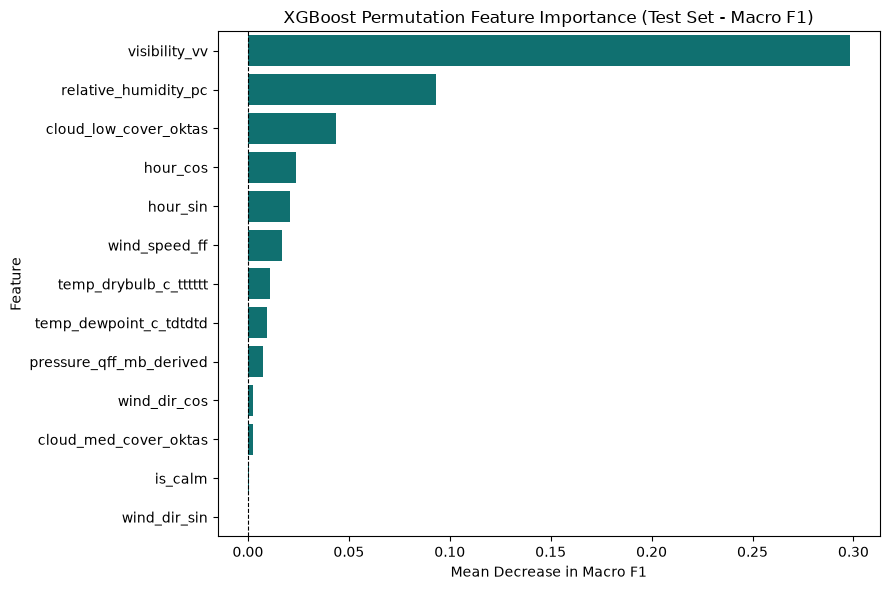

In [234]:
plt.figure(figsize=(9, 6))
sns.barplot(
    data=permutation_importance_df,
    x='Permutation Mean',
    y='Feature',
    color='teal'
)
plt.axvline(0, color='black', linestyle='--', linewidth=0.8)
plt.title('XGBoost Permutation Feature Importance (Test Set - Macro F1)')
plt.xlabel('Mean Decrease in Macro F1')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

- Nilai importance positif menunjukkan bahwa pengacakan fitur menurunkan kinerja model
- Nilai mendekati nol menunjukkan perubahan yang kecil
- Nilai negatif berarti skor model justru meningkat setelah fitur diacak

**Notes:**

- **Tiga fitur utama paling krusial pada data uji:** Pengacakan **`visibility_vv`** menyebabkan penurunan *Macro F1-Score* terbesar, yaitu sebesar **`0,2982 ± 0,0105`**, diikuti oleh **`relative_humidity_pc` (`0,0934 ± 0,0056`)** dan **`cloud_low_cover_oktas` (`0,0438 ± 0,0104`)**. Hal ini membuktikan bahwa model sangat bergantung pada ketiga variabel fisik tersebut saat melakukan generalisasi pada data baru.
- **Kontribusi positif hampir di seluruh fitur terpilih:** Sebanyak **12 dari 13 fitur** menghasilkan nilai *Permutation Mean* positif—termasuk fitur diurnal (`hour_cos = 0,0238`, `hour_sin = 0,0209`), kecepatan angin (`wind_speed_ff = 0,0169`), parameter suhu (`temp_drybulb_c_tttttt = 0,0110`, `temp_dewpoint_c_tdtdtd = 0,0096`), serta tekanan udara (`pressure_qff_mb_derived = 0,0077`). Temuan ini mengonfirmasi bahwa seleksi 13 fitur pada Bab 8 efektif menjaga fitur yang relevan tanpa menimbulkan gangguan (*noise*).
- **Fitur dengan dampak minimal saat diacak:** `wind_dir_cos` (`0,0027 ± 0,0053`), `cloud_med_cover_oktas` (`0,0023 ± 0,0032`), `is_calm` (`0,0007 ± 0,0004`), dan `wind_dir_sin` (`-0,0001 ± 0,0036`) memiliki nilai yang mendekati nol, yang menandakan perubahan performa pada data uji sangat kecil ketika nilai fitur-fitur tersebut diacak.

## 12.3 Perbandingan dan Interpretasi Feature Importance

Menggabungkan hasil *Gain-Based Feature Importance* dan *Permutation Feature Importance* dalam satu tabel perbandingan untuk melihat konsistensi peringkat fitur dominan serta mengidentifikasi variabel yang berperan besar dalam pemisahan aturan pohon namun memiliki dampak berbeda terhadap generalisasi pada data uji.

In [235]:
importance_comparison = (
    feature_importance
    .merge(permutation_importance_df, on='Feature')
    .sort_values(by='Gain Importance', ascending=False)
    .reset_index(drop=True)
)
display(importance_comparison.round(4))

,Feature,Gain Importance,Permutation Mean,Permutation Std
0,visibility_vv,0.2459,0.2982,0.0105
1,relative_humidity_pc,0.1561,0.0934,0.0056
2,cloud_low_cover_oktas,0.0954,0.0438,0.0104
3,cloud_med_cover_oktas,0.0812,0.0023,0.0032
4,hour_cos,0.0797,0.0238,0.0034
5,temp_dewpoint_c_tdtdtd,0.0582,0.0096,0.0061
6,temp_drybulb_c_tttttt,0.0495,0.0110,0.0059
7,hour_sin,0.0454,0.0209,0.0060
8,wind_speed_ff,0.0432,0.0169,0.0060
9,pressure_qff_mb_derived,0.0409,0.0077,0.0056


**Notes:**

- **Konsistensi tiga fitur paling dominan:** Kedua metode menunjukkan kesepakatan penuh pada tiga peringkat teratas, yaitu **`visibility_vv`** (*Gain* `0,2459` | *Permutation* `0,2982`), **`relative_humidity_pc`** (*Gain* `0,1561` | *Permutation* `0,0934`), dan **`cloud_low_cover_oktas`** (*Gain* `0,0954` | *Permutation* `0,0438`). Secara fisik meteorologi, kombinasi jarak pandang, kelembapan relatif, dan tutupan awan rendah merupakan indikator utama untuk membedakan kabut (`Fog`/`Mist`), kekaburan partikel (`Haze/Smoke/Dust`), hujan (`Active Precipitation`), dan cuaca cerah (`Normal`).
- **Perbedaan peringkat pada `cloud_med_cover_oktas`:** Fitur `cloud_med_cover_oktas` menempati peringkat ke-4 pada *Gain Importance* (`0,0812`), namun turun ke peringkat ke-11 pada *Permutation Mean* (`0,0023`). Perbedaan ini terjadi karena fitur tersebut sering digunakan pohon untuk memecah aturan spesifik pada data latih, tetapi pada data uji sebagian informasinya sudah terwakili oleh `cloud_low_cover_oktas` dan `relative_humidity_pc`.
- **Peran variabel waktu diurnal dan angin pada generalisasi:** `hour_cos` (`0,0238`), `hour_sin` (`0,0209`), dan `wind_speed_ff` (`0,0169`) menempati peringkat ke-4 hingga ke-6 pada *Permutation Importance*, lebih tinggi dibandingkan peringkat *Gain*-nya. Hal ini menunjukkan bahwa pola siklus harian (pagi, siang, malam) dan pergerakan angin berperan penting dalam menjaga akurasi klasifikasi fenomena yang terikat waktu kemunculan seperti `Fog`, `Mist`, dan hujan konvektif pada data uji.

# 13. External Validation

*External validation* dilakukan untuk menguji kemampuan generalisasi **model utama terpilih (XGBoost hasil *hyperparameter tuning*)** pada dataset observasi periode baru di luar rentang data pelatihan dan pengujian internal. Data eksternal diproses menggunakan tahapan *cleaning*, pemetaan target 7 kelas fenomena cuaca, *feature engineering*, dan seleksi 13 fitur yang identik dengan *pipeline* pelatihan, kemudian diprediksi secara langsung tanpa pelatihan ulang (*zero retraining*).

## 13.1 Inspeksi Data Eksternal

Tahap ini memeriksa dimensi dataset (`shape`), struktur kolom, contoh baris awal, serta kelengkapan nilai (*missing value*) pada file data eksternal (`bmkg-jambi-26-new.csv`) sebelum dilakukan pembersihan dan transformasi fitur.

In [236]:
external_df = pd.read_csv('../bmkg-dataset/bmkg-jambi-26-new.csv', sep=None, engine='python')

In [238]:
print(f"Dimensi external_df: {external_df.shape[0]} baris x {external_df.shape[1]} kolom")

Dimensi external_df: 30408 baris x 93 kolom


In [237]:
with pd.option_context('display.max_columns', None, 'display.max_colwidth', None):
    display(data_df.head())

,station_name,data_timestamp,wind_indicator_iw,wind_dir_deg_dd,wind_speed_ff,visibility_vv,weather_indicator_ix,present_weather_ww,past_weather_w1,past_weather_w2,pressure_temp_c,pressure_reading_mb,pressure_qfe_mb_derived,pressure_qff_mb_derived,pressure_3h_diff_mb_ppp,pressure_24h_diff_mb_p24,temp_drybulb_c_tttttt,temp_dewpoint_c_tdtdtd,temp_wetbulb_c,temp_max_c_txtxtx,temp_min_c_tntntn,relative_humidity_pc,rainfall_last_mm,rainfall_24h_rrrr,rainfall_6h_rrr,rainfall_indicator_ir,cloud_low_type_cl,cloud_low_cover_oktas,cloud_low_type_1,cloud_low_type_2,cloud_low_type_3,cloud_low_cover_1,cloud_low_cover_2,cloud_low_cover_3,cloud_low_base_1,cloud_low_base_2,cloud_low_base_3,cloud_low_peak_1,cloud_low_peak_2,cloud_low_dir_1,cloud_low_dir_2,cloud_low_dir_3,cloud_elevation_angle_ec_1,cloud_elevation_angle_ec_2,cloud_low_dir_true_da_1,cloud_low_dir_true_da_2,cloud_layer_1_type_c,cloud_layer_2_type_c,cloud_layer_1_height_m_hshs,cloud_layer_2_height_m_hshs,cloud_layer_1_amt_oktas_ns,cloud_layer_2_amt_oktas_ns,cloud_layer_3_type_c,cloud_layer_3_height_m_hshs,cloud_layer_3_amt_oktas_ns,cloud_layer_4_type_c,cloud_layer_4_height_m_hshs,cloud_layer_4_amt_oktas_ns,cloud_med_type_cm,cloud_med_cover_oktas,cloud_med_type_1,cloud_med_type_2,cloud_med_cover_1,cloud_med_cover_2,cloud_med_base_1,cloud_med_base_2,cloud_med_dir_1,cloud_med_dir_2,cloud_high_type_ch,cloud_high_cover_oktas,cloud_high_type_1,cloud_high_type_2,cloud_high_cover_1,cloud_high_cover_2,cloud_high_base_1,cloud_high_base_2,cloud_high_dir_1,cloud_high_dir_2,created_at,updated_at,qc_flag,qc_histories
0,Stasiun Meteorologi Sultan Thaha,01/01/2025 00:00,4,300,5,7.0,1,5,2,2,NaN,NaN,1006.8,1009.8,1.4,-1.1,25.8,24.8,25.1,NaN,24.7,95,0.0,0.0,0.0,3,5,3,6,NaN,NaN,3,NaN,NaN,480.0,NaN,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN,6.0,4.0,480.0,3000.0,3.0,3.0,NaN,NaN,NaN,NaN,NaN,NaN,2,3,4,3.0,2,1.0,3000.0,3000.0,0,0.0,1,1,0,NaN,1,NaN,9000.0,NaN,0,NaN,31/12/2025 08:14,31/12/2025 08:14,0,NaN
1,Stasiun Meteorologi Sultan Thaha,01/01/2025 01:00,4,310,9,10.0,2,2,2,2,NaN,NaN,1007.6,1010.6,NaN,NaN,26.7,24.8,25.3,NaN,NaN,89,NaN,NaN,NaN,4,5,4,6,NaN,NaN,4,NaN,NaN,450.0,NaN,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN,6.0,4.0,450.0,3000.0,4.0,4.0,NaN,NaN,NaN,NaN,NaN,NaN,2,4,4,NaN,4,NaN,3000.0,NaN,0,NaN,1,1,0,NaN,1,NaN,9000.0,NaN,0,NaN,31/12/2025 08:14,31/12/2025 08:14,0,NaN
2,Stasiun Meteorologi Sultan Thaha,01/01/2025 02:00,4,310,8,10.0,2,1,2,2,NaN,NaN,1008.0,1011.0,NaN,NaN,28.0,24.8,25.6,NaN,NaN,83,NaN,NaN,NaN,4,2,3,8,NaN,NaN,3,NaN,NaN,450.0,NaN,NaN,1500.0,NaN,0,NaN,NaN,2.0,NaN,0.0,NaN,8.0,3.0,450.0,3000.0,3.0,3.0,NaN,NaN,NaN,NaN,NaN,NaN,3,3,3,NaN,3,NaN,3000.0,NaN,0,NaN,1,1,0,NaN,1,NaN,9000.0,NaN,0,NaN,31/12/2025 08:14,31/12/2025 08:14,0,NaN
3,Stasiun Meteorologi Sultan Thaha,01/01/2025 03:00,4,350,10,10.0,2,2,2,2,NaN,NaN,1007.9,1010.9,1.1,NaN,29.5,24.5,25.8,NaN,NaN,75,0.0,NaN,NaN,3,2,4,8,NaN,NaN,4,NaN,NaN,450.0,NaN,NaN,1500.0,NaN,0,NaN,NaN,2.0,NaN,0.0,NaN,8.0,NaN,450.0,NaN,4.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3,2,3,NaN,2,NaN,3000.0,NaN,0,NaN,1,1,0,NaN,1,NaN,9000.0,NaN,0,NaN,31/12/2025 08:14,31/12/2025 08:14,0,NaN
4,Stasiun Meteorologi Sultan Thaha,01/01/2025 04:00,4,330,10,10.0,2,2,2,2,NaN,NaN,1007.3,1010.3,NaN,NaN,30.6,24.4,26.0,NaN,NaN,69,NaN,NaN,NaN,4,2,4,8,NaN,NaN,4,NaN,NaN,510.0,NaN,NaN,1500.0,NaN,0,NaN,NaN,2.0,NaN,0.0,NaN,8.0,NaN,510.0,NaN,4.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3,2,3,NaN,2,NaN,3000.0,NaN,0,NaN,1,1,0,NaN,1,NaN,9000.0,NaN,0,NaN,31/12/2025 08:14,31/12/2025 08:14,0,NaN


In [239]:
core_raw_cols = [
    'station_name', 'data_timestamp', 'weather_indicator_ix', 'present_weather_ww',
    'wind_dir_deg_dd', 'wind_speed_ff', 'pressure_qff_mb_derived',
    'temp_drybulb_c_tttttt', 'temp_dewpoint_c_tdtdtd', 'relative_humidity_pc',
    'cloud_low_cover_oktas', 'cloud_med_cover_oktas', 'visibility_vv'
]

In [240]:
available_core = [c for c in core_raw_cols if c in external_df.columns]
missing_core = [c for c in core_raw_cols if c not in external_df.columns]

In [241]:
print("Kolom inti tidak ditemukan:", missing_core)

Kolom inti tidak ditemukan: []


In [242]:
core_missing_df = pd.DataFrame({
    'Missing Count': external_df[available_core].isna().sum(),
    'Missing (%)': (external_df[available_core].isna().mean() * 100).round(2),
    'Dtype': external_df[available_core].dtypes
})
display(core_missing_df)

,Missing Count,Missing (%),Dtype
station_name,0,0.00,str
data_timestamp,17376,57.14,str
weather_indicator_ix,26064,85.71,float64
present_weather_ww,26064,85.71,float64
wind_dir_deg_dd,21720,71.43,float64
wind_speed_ff,26050,85.67,str
pressure_qff_mb_derived,26064,85.71,float64
temp_drybulb_c_tttttt,26064,85.71,float64
temp_dewpoint_c_tdtdtd,26064,85.71,float64
relative_humidity_pc,26064,85.71,float64


**Notes:**

- Dataset eksternal (`bmkg-jambi-26-new.csv`) terdiri atas **`30.408` baris dan `93` kolom**, dengan seluruh 13 kolom mentah inti yang dibutuhkan *pipeline* tersedia secara lengkap (`0` kolom hilang).
- Terdapat tingkat *missing value* yang besar pada kolom-kolom utama (`57,14%` pada `data_timestamp` dan `85,71%` pada sebagian besar parameter meteorologi), yang mengindikasikan keberadaan baris kosong atau catatan tambahan di dalam file mentah.
- Kolom `wind_speed_ff`, `cloud_low_cover_oktas`, `cloud_med_cover_oktas`, dan `visibility_vv` masih terbaca sebagai tipe teks (`str`), sehingga memerlukan konversi numerik dan penanganan karakter non-numerik pada tahap pembersihan.
- Sampel baris awal memperlihatkan catatan waktu dari tahun 2025 (`01/01/2025`), sehingga pemeriksaan rentang waktu pada sub-bab berikutnya diperlukan untuk memisahkan data observasi periode 2026 sebagai data validasi eksternal.

## 13.2 Pemeriksaan Timestamp dan Pemisahan Periode Eksternal

Melakukan penguraian (*parsing*) kolom `data_timestamp` dengan format tanggal Indonesia (`dayfirst=True`), memeriksa jumlah baris valid maupun duplikat, melihat sebaran observasi per bulan/tahun, serta memisahkan data periode **tahun 2026** sebagai himpunan validasi eksternal yang sepenuhnya terpisah dari periode data pelatihan (tahun 2025).

**Parse timestamp dengan dayfirst=True sesuai format DD/MM/YYYY HH:MM**

In [243]:
external_df['data_timestamp_parsed'] = pd.to_datetime(
    external_df['data_timestamp'],
    dayfirst=True,
    errors='coerce'
)

In [244]:
print("Total baris mentah          :", len(external_df))
print("Timestamp valid (non-NaT)   :", external_df['data_timestamp_parsed'].notna().sum())
print("Timestamp tidak valid (NaT) :", external_df['data_timestamp_parsed'].isna().sum())

Total baris mentah          : 30408
Timestamp valid (non-NaT)   : 8688
Timestamp tidak valid (NaT) : 21720


**Cek distribusi observasi berdasarkan Tahun-Bulan pada baris yang memiliki timestamp valid**

In [245]:
valid_ts_df = external_df.dropna(subset=['data_timestamp_parsed']).copy()

In [246]:
monthly_dist = (
    valid_ts_df['data_timestamp_parsed']
    .dt.to_period('M')
    .value_counts()
    .sort_index()
)

In [247]:
display(monthly_dist.to_frame('Jumlah Baris'))

,Jumlah Baris
data_timestamp_parsed,
2026-01,744
2026-02,1416
2026-03,1416
2026-04,2160
2026-05,1512
2026-06,1440


In [248]:
ext_2026_raw = valid_ts_df[valid_ts_df['data_timestamp_parsed'].dt.year == 2026].copy()
ext_2026_raw['data_timestamp'] = ext_2026_raw['data_timestamp_parsed']
ext_2026_raw.drop(columns=['data_timestamp_parsed'], inplace=True)

In [249]:
print("Jumlah baris tahun 2026     :", len(ext_2026_raw))
print("Rentang waktu               :", ext_2026_raw['data_timestamp'].min(), "s.d.", ext_2026_raw['data_timestamp'].max())
print("Jumlah timestamp duplikat   :", ext_2026_raw['data_timestamp'].duplicated().sum())

Jumlah baris tahun 2026     : 8688
Rentang waktu               : 2026-01-01 00:00:00 s.d. 2026-06-30 23:03:00
Jumlah timestamp duplikat   : 3390


**Notes:**

- Dari total **`30.408` baris mentah**, sebanyak **`8.688` baris** memiliki `data_timestamp` valid yang seluruhnya berada pada periode **1 Januari 2026 pukul 00:00 UTC hingga 30 Juni 2026 pukul 23:03 UTC** (Januari–Juni 2026), sedangkan **`21.720` baris** bernilai `NaT` (*missing*).
- Pada `8.688` baris tahun 2026 tersebut masih ditemukan **`3.390` *timestamp* duplikat** serta catatan waktu di luar jam bulat (seperti `23:03:00`), yang menandakan adanya baris duplikat atau catatan tambahan per jam pengamatan di dalam file ekspor mentah.
- Oleh karena itu, pada tahap berikutnya dilakukan penyaringan baris yang memiliki data meteorologi lengkap serta penanganan duplikasi *timestamp* agar diperoleh rangkaian observasi per jam yang bersih.

## 13.3 Pembersihan Baris Observasi dan Standarisasi Waktu (WIB)

Menyaring `ext_2026_raw` agar hanya mempertahankan baris observasi sinoptik yang memiliki parameter cuaca utama (`present_weather_ww`, `temp_drybulb_c_tttttt`, `relative_humidity_pc`, `visibility_vv`), menangani duplikasi `data_timestamp`, memeriksa keteraturan interval pengamatan per jam, serta mengonversi waktu pengamatan dari **UTC ke WIB (`+7 jam`)** agar konsisten dengan data pelatihan.

In [250]:
required_obs_cols = [
    'present_weather_ww',
    'temp_drybulb_c_tttttt',
    'temp_dewpoint_c_tdtdtd',
    'relative_humidity_pc',
    'pressure_qff_mb_derived'
]

In [251]:
ext_clean = ext_2026_raw.dropna(subset=required_obs_cols).copy()

In [252]:
print("Jumlah baris setelah menghapus baris kosong parameter utama :", len(ext_clean))
print("Jumlah timestamp duplikat tersisa                         :", ext_clean['data_timestamp'].duplicated().sum())

Jumlah baris setelah menghapus baris kosong parameter utama : 4344
Jumlah timestamp duplikat tersisa                         : 0


In [253]:
if ext_clean['data_timestamp'].duplicated().sum() > 0:
    ext_clean = (
        ext_clean
        .sort_values('data_timestamp')
        .drop_duplicates(subset=['data_timestamp'], keep='first')
        .reset_index(drop=True)
    )
    print("Jumlah baris setelah deduplikasi timestamp                :", len(ext_clean))
else:
    ext_clean = ext_clean.sort_values('data_timestamp').reset_index(drop=True)

In [254]:
date_pos = ext_clean.columns.get_loc('data_timestamp') + 1
ext_clean.insert(date_pos, 'datetime_wib', ext_clean['data_timestamp'] + pd.Timedelta(hours=7))

In [255]:
print("Rentang UTC :", ext_clean['data_timestamp'].min(), "s.d.", ext_clean['data_timestamp'].max())
print("Rentang WIB :", ext_clean['datetime_wib'].min(), "s.d.", ext_clean['datetime_wib'].max())

Rentang UTC : 2026-01-01 00:00:00 s.d. 2026-06-30 23:00:00
Rentang WIB : 2026-01-01 07:00:00 s.d. 2026-07-01 06:00:00


In [256]:
intervals_ext = ext_clean['datetime_wib'].diff().dropna()
print("\nDistribusi interval antarobservasi (Top 5):")
display(intervals_ext.value_counts().head(5).to_frame('Jumlah'))


Distribusi interval antarobservasi (Top 5):


,Jumlah
datetime_wib,
0 days 01:00:00,4343


In [257]:
monthly_clean = ext_clean['datetime_wib'].dt.to_period('M').value_counts().sort_index()
print("\nJumlah observasi bersih per bulan (WIB):")
display(monthly_clean.to_frame('Jumlah Observasi'))


Jumlah observasi bersih per bulan (WIB):


,Jumlah Observasi
datetime_wib,
2026-01,737
2026-02,672
2026-03,744
2026-04,720
2026-05,744
2026-06,720
2026-07,7


**Notes:**

- Setelah menyaring baris yang memiliki kelengkapan parameter meteorologi utama, diperoleh **`4.344` observasi sinoptik valid** dengan **`0` *timestamp* duplikat** (seluruh `3.390` duplikasi pada tahap sebelumnya terbukti berasal dari baris kosong/tidak lengkap).
- Rangkaian data eksternal mencakup periode **1 Januari 2026 pukul 00:00 UTC hingga 30 Juni 2026 pukul 23:00 UTC**, atau setara dengan **1 Januari 2026 pukul 07:00 WIB hingga 1 Juli 2026 pukul 06:00 WIB** (total **181 hari penuh**).
- Seluruh `4.343` selisih waktu antarobservasi beruntun tercatat tepat **`1 jam` (`0 days 01:00:00`)** tanpa satu pun jam pengamatan yang terlewat, dengan distribusi merata pada setiap bulan (`737` observasi pada Januari, `672` Februari, `744` Maret, `720` April, `744` Mei, `720` Juni, dan `7` jam awal pada 1 Juli WIB).

## 13.4 Pembersihan Fitur Inti dan Pemetaan Target 7 Kelas

Melakukan pembersihan serta konversi tipe data numerik pada kolom fitur utama (`wind_dir_deg_dd`, `wind_speed_ff`, `pressure_qff_mb_derived`, `temp_drybulb_c_tttttt`, `temp_dewpoint_c_tdtdtd`, `relative_humidity_pc`, `cloud_low_cover_oktas`, `cloud_med_cover_oktas`, dan `visibility_vv`), menangani nilai hilang jika terdapat karakter non-numerik (seperti sandi `/` pada tutupan awan), serta memetakan kode cuaca `present_weather_ww` ke dalam **7 kategori fenomena** yang identik dengan data pelatihan (`label_map`).

In [258]:
numeric_core_cols = [
    'wind_dir_deg_dd',
    'wind_speed_ff',
    'pressure_qff_mb_derived',
    'temp_drybulb_c_tttttt',
    'temp_dewpoint_c_tdtdtd',
    'relative_humidity_pc',
    'cloud_low_cover_oktas',
    'cloud_med_cover_oktas',
    'visibility_vv'
]

In [259]:
for col in numeric_core_cols:
    ext_clean[col] = pd.to_numeric(ext_clean[col], errors='coerce')

display(ext_clean[numeric_core_cols].isna().sum().to_frame('Missing Count'))

,Missing Count
wind_dir_deg_dd,0
wind_speed_ff,0
pressure_qff_mb_derived,0
temp_drybulb_c_tttttt,0
temp_dewpoint_c_tdtdtd,0
relative_humidity_pc,0
cloud_low_cover_oktas,3
cloud_med_cover_oktas,38
visibility_vv,0


In [260]:
def map_ww_to_phenomenon(ww):
    if pd.isna(ww):
        return np.nan
    ww = int(ww)
    if ww in [0, 1, 2, 3]:
        return 'Normal'
    elif ww in [4, 5, 6, 7, 8, 9, 30, 31, 32, 33, 34, 35]:
        return 'Haze/Smoke/Dust'
    elif ww == 10:
        return 'Mist'
    elif ww in [11, 12] or (40 <= ww <= 49):
        return 'Fog'
    elif ww in [14, 15, 16] or (20 <= ww <= 29):
        return 'Recent/Distant Precipitation'
    elif 50 <= ww <= 99:
        return 'Active Precipitation'
    else:
        return 'Other'

In [261]:
ext_clean['phenomenon'] = ext_clean['present_weather_ww'].apply(map_ww_to_phenomenon)
ext_clean['phenomenon_encoded'] = ext_clean['phenomenon'].map(label_map)

In [262]:
dist_compare = pd.DataFrame({
    'External 2026 (Count)': ext_clean['phenomenon'].value_counts(),
    'External 2026 (%)': (ext_clean['phenomenon'].value_counts(normalize=True) * 100).round(2),
    'Train 2025 (Count)': train_df['phenomenon'].value_counts(),
    'Train 2025 (%)': (train_df['phenomenon'].value_counts(normalize=True) * 100).round(2)
}).reindex(list(label_map.keys())).fillna(0)

In [263]:
dist_compare['External 2026 (Count)'] = dist_compare['External 2026 (Count)'].astype(int)
dist_compare['Train 2025 (Count)'] = dist_compare['Train 2025 (Count)'].astype(int)

In [264]:
display(dist_compare)

,External 2026 (Count),External 2026 (%),Train 2025 (Count),Train 2025 (%)
phenomenon,,,,
Active Precipitation,322,7.41,640,9.13
Fog,25,0.58,37,0.53
Haze/Smoke/Dust,763,17.56,2194,31.31
Mist,172,3.96,354,5.05
Normal,2806,64.59,3350,47.80
Other,68,1.57,43,0.61
Recent/Distant Precipitation,188,4.33,390,5.57


In [265]:
print("Missing label setelah encoding:", ext_clean['phenomenon_encoded'].isna().sum())

Missing label setelah encoding: 0


**Notes:**

- Setelah konversi ke tipe numerik, tujuh dari sembilan kolom parameter meteorologi inti bebas dari nilai hilang (`0` *missing*), sedangkan dua kolom tutupan awan menyisakan sedikit nilai hilang akibat karakter sandi non-numerik (`/`), yakni **`3` observasi pada `cloud_low_cover_oktas`** (`0,07%`) dan **`38` observasi pada `cloud_med_cover_oktas`** (`0,87%`).
- Pemetaan kode cuaca `present_weather_ww` berhasil mengonversi seluruh **`4.344` observasi** ke dalam **7 kategori fenomena** (`0` label hilang) yang sepenuhnya selaras dengan `label_map` pada data pelatihan.
- Perbandingan proporsi antarperiode memperlihatkan adanya pergeseran distribusi kelas (*distribution shift*): pada data eksternal (Januari–Juni 2026), proporsi kelas `Normal` meningkat menjadi **`64,59%`** (dibandingkan `47,80%` pada data latih 2025), sementara proporsi `Haze/Smoke/Dust` turun menjadi **`17,56%`** (dibandingkan `31,31%`). Perbedaan ini wajar secara klimatologis karena periode Januari–Juni didominasi musim hujan dan peralihan, sedangkan periode puncak kemarau serta kabut asap umumnya terjadi pada paruh kedua tahun (Juli–Oktober).

## 13.5 Penanganan Missing Value Awan, Feature Engineering, dan Persiapan Input Model

Tahap ini menyelesaikan sisa *missing value* pada kolom tutupan awan (`cloud_low_cover_oktas` dan `cloud_med_cover_oktas`) menggunakan metode *forward-fill* dan *backward-fill* (`ffill().bfill()`) sesuai sifat deret waktu pengamatan per jam yang kontinu. Selanjutnya, dibentuk fitur turunan yang identik dengan *pipeline* pelatihan (`hour_sin`, `hour_cos`, `wind_dir_sin`, `wind_dir_cos`, dan `is_calm`), lalu dilakukan penyelarasan urutan kolom serta tipe data agar tepat sama dengan `X_train` sebelum prediksi dilakukan.

**Imputasi sisa missing value pada tutupan awan mengikuti kontinuitas deret waktu per jam**

In [266]:
cloud_cols = ['cloud_low_cover_oktas', 'cloud_med_cover_oktas']
for col in cloud_cols:
    ext_clean[col] = ext_clean[col].ffill().bfill().astype('int8')

**Pembentukan fitur turunan (Feature Engineering) sesuai pipeline pelatihan**

In [267]:
ext_clean['hour'] = ext_clean['datetime_wib'].dt.hour
ext_clean['hour_sin'] = np.sin(2 * np.pi * ext_clean['hour'] / 24)
ext_clean['hour_cos'] = np.cos(2 * np.pi * ext_clean['hour'] / 24)

In [268]:
ext_clean['wind_dir_sin'] = np.sin(np.deg2rad(ext_clean['wind_dir_deg_dd']))
ext_clean['wind_dir_cos'] = np.cos(np.deg2rad(ext_clean['wind_dir_deg_dd']))

In [269]:
ext_clean['is_calm'] = (ext_clean['wind_speed_ff'] == 0).astype(int)

**Susun matriks fitur X_external dan target y_external dengan urutan kolom identik X_train**

In [270]:
train_feature_cols = list(X_train.columns)
X_external = ext_clean[train_feature_cols].copy()
y_external = ext_clean['phenomenon_encoded'].astype(int).copy()

In [271]:
for col in train_feature_cols:
    X_external[col] = X_external[col].astype(X_train[col].dtype)

In [272]:
assert list(X_external.columns) == train_feature_cols, "Urutan kolom tidak sesuai dengan X_train!"
assert X_external.isna().sum().sum() == 0, "Masih terdapat missing value pada X_external!"
assert y_external.isna().sum() == 0, "Masih terdapat missing value pada y_external!"

In [273]:
print("Dimensi X_external :", X_external.shape)
print("Dimensi y_external :", y_external.shape)
print("Total missing value:", X_external.isna().sum().sum())

Dimensi X_external : (4344, 13)
Dimensi y_external : (4344,)
Total missing value: 0


In [274]:
display(X_external.head())

,wind_speed_ff,wind_dir_sin,wind_dir_cos,is_calm,pressure_qff_mb_derived,temp_drybulb_c_tttttt,temp_dewpoint_c_tdtdtd,relative_humidity_pc,cloud_low_cover_oktas,cloud_med_cover_oktas,visibility_vv,hour_sin,hour_cos
0,2,0.766044,-0.642788,0,1009.1,23.6,23.2,98,4,8,3.0,0.965926,-0.258819
1,4,0.866025,-0.500000,0,1010.1,24.0,23.3,96,4,8,5.0,0.866025,-0.500000
2,5,-0.766044,0.642788,0,1010.6,25.0,23.2,90,4,8,10.0,0.707107,-0.707107
3,5,-0.866025,0.500000,0,1010.9,26.0,23.5,86,4,8,10.0,0.500000,-0.866025
4,5,-0.984808,-0.173648,0,1010.4,27.2,23.3,79,2,8,10.0,0.258819,-0.965926


**Notes:**

- Seluruh sisa nilai hilang pada `cloud_low_cover_oktas` dan `cloud_med_cover_oktas` berhasil ditangani melalui imputasi deret waktu (`ffill().bfill()`), sedangkan lima fitur turunan (`hour_sin`, `hour_cos`, `wind_dir_sin`, `wind_dir_cos`, dan `is_calm`) terbentuk sesuai aturan *pipeline* pelatihan.
- Matriks masukan `X_external` berukuran **`(4.344, 13)`** dengan vektor target `y_external` berukuran **`(4.344,)`** dan **`0` nilai hilang (*missing value*)**. Urutan kolom serta tipe data seluruh fitur telah terverifikasi identik dengan `X_train`, sehingga data siap digunakan pada tahap prediksi.

## 13.6 Prediksi pada Data Eksternal

Melakukan prediksi terhadap **`4.344` observasi eksternal** (periode Januari–Juni 2026) menggunakan **model utama terpilih (`final_xgb` — XGBoost hasil *hyperparameter tuning*)** tanpa pelatihan ulang. Hasil prediksi kemudian dibandingkan proporsinya terhadap distribusi kelas aktual untuk melihat kecenderungan prediksi model pada periode baru.

In [275]:
final_xgb = search_results['XGBoost'].best_estimator_
ext_pred = final_xgb.predict(X_external)

In [276]:
ext_clean['predicted_code'] = ext_pred
ext_clean['predicted_phenomenon'] = ext_clean['predicted_code'].map(inv_label_map)

In [277]:
pred_dist_df = pd.DataFrame({
    'Predicted Count': ext_clean['predicted_phenomenon'].value_counts(),
    'Predicted (%)': (ext_clean['predicted_phenomenon'].value_counts(normalize=True) * 100).round(2),
    'Actual Count': ext_clean['phenomenon'].value_counts(),
    'Actual (%)': (ext_clean['phenomenon'].value_counts(normalize=True) * 100).round(2)
}).reindex(list(label_map.keys())).fillna(0)

In [278]:
pred_dist_df['Predicted Count'] = pred_dist_df['Predicted Count'].astype(int)
pred_dist_df['Actual Count'] = pred_dist_df['Actual Count'].astype(int)

In [279]:
display(pred_dist_df)

,Predicted Count,Predicted (%),Actual Count,Actual (%)
Active Precipitation,298,6.86,322,7.41
Fog,32,0.74,25,0.58
Haze/Smoke/Dust,1098,25.28,763,17.56
Mist,271,6.24,172,3.96
Normal,2184,50.28,2806,64.59
Other,76,1.75,68,1.57
Recent/Distant Precipitation,385,8.86,188,4.33


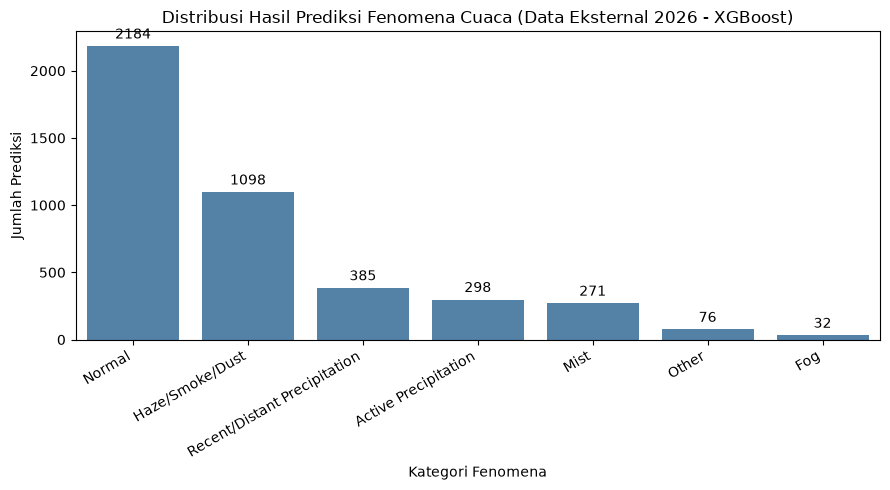

In [288]:
plt.figure(figsize=(9, 5))
order_labels = ext_clean['predicted_phenomenon'].value_counts().index
ax = sns.countplot(
    data=ext_clean,
    x='predicted_phenomenon',
    order=order_labels,
    color='steelblue'
)
plt.title('Distribusi Hasil Prediksi Fenomena Cuaca (Data Eksternal 2026 - XGBoost)')
plt.xlabel('Kategori Fenomena')
plt.ylabel('Jumlah Prediksi')
plt.xticks(rotation=30, ha='right')

for container in ax.containers:
    ax.bar_label(container, padding=3)

plt.tight_layout()
plt.show()

**Notes:**

- Dari total **`4.344` observasi eksternal**, model utama **XGBoost** memprediksi kelas mayoritas **`Normal` sebanyak `2.184` kali (`50,28%`)**, lebih rendah dibandingkan frekuensi aktualnya sebesar **`2.806` observasi (`64,59%`)**.
- Sebaliknya, model cenderung memprediksi lebih banyak pada kelas **`Haze/Smoke/Dust` (`1.098` prediksi / `25,28%` vs aktual `763` / `17,56%`)**, **`Recent/Distant Precipitation` (`385` prediksi / `8,86%` vs aktual `188` / `4,33%`)**, dan **`Mist` (`271` prediksi / `6,24%` vs aktual `172` / `3,96%`)**. Pola ini dipengaruhi oleh dua faktor utama:
  1. Penerapan pembobotan kelas seimbang (*balanced sample weight*) selama pelatihan yang membuat model lebih agresif mendeteksi kelas non-`Normal`.
  2. Pergeseran distribusi musiman (*distribution shift*), karena model dilatih pada data tahun 2025 dengan proporsi `Haze/Smoke/Dust` yang jauh lebih tinggi (`31,31%`), sedangkan periode eksternal Januari–Juni 2026 didominasi cuaca cerah/berawan (`Normal`).
- Untuk kategori **`Active Precipitation` (`298` prediksi vs `322` aktual)**, **`Other` (`76` vs `68`)**, dan **`Fog` (`32` vs `25`)**, jumlah total prediksi berada sangat dekat dengan frekuensi aktualnya. Ketepatan kecocokan tiap observasi akan diuji secara rinci pada sub-bab evaluasi berikutnya.

In [192]:
external_clean['cloud_low_cover_1'] = external_clean['cloud_low_cover_1'].astype('int8')
external_clean['cloud_cover_oktas_m'] = external_clean['cloud_cover_oktas_m'].astype('int8')

In [193]:
date_position = external_clean.columns.get_loc('data_timestamp') + 1
external_clean.insert(date_position, 'datetime_wib', external_clean['data_timestamp'] + pd.Timedelta(hours=7))
external_clean[['data_timestamp', 'datetime_wib']].head()

,data_timestamp,datetime_wib
0,2026-01-01 00:00:00,2026-01-01 07:00:00
1,2026-01-01 01:00:00,2026-01-01 08:00:00
2,2026-01-01 02:00:00,2026-01-01 09:00:00
3,2026-01-01 03:00:00,2026-01-01 10:00:00
4,2026-01-01 04:00:00,2026-01-01 11:00:00


In [194]:
print("Rentang waktu WIB:")
print(external_clean['datetime_wib'].min(), "hingga", external_clean['datetime_wib'].max())

Rentang waktu WIB:
2026-01-01 07:00:00 hingga 2026-03-01 06:00:00


In [195]:
external_clean['hour'] = external_clean['datetime_wib'].dt.hour

external_clean['hour_sin'] = np.sin(2 * np.pi * external_clean['hour'] / 24)
external_clean['hour_cos'] = np.cos(2 * np.pi * external_clean['hour'] / 24)

In [196]:
external_clean['wind_dir_sin'] = np.sin(np.deg2rad(external_clean['wind_dir_deg_dd']))
external_clean['wind_dir_cos'] = np.cos(np.deg2rad(external_clean['wind_dir_deg_dd']))

In [197]:
external_clean['is_calm'] = (external_clean['wind_speed_ff'] == 0).astype(int)

In [198]:
selected_features = [
    'visibility_vv',
    'relative_humidity_pc',
    'hour_cos',
    'cloud_low_cover_1',
    'temp_drybulb_c_tttttt',
    'pressure_qff_mb_derived',
    'cloud_cover_oktas_m',
    'wind_dir_cos',
    'hour_sin',
    'temp_dewpoint_c_tdtdtd',
    'wind_dir_sin',
    'wind_speed_ff',
    'is_calm'
]

 Memeriksa fitur yang belum tersedia

In [199]:
missing_features = [
    col for col in selected_features
    if col not in external_clean.columns
]

if missing_features:
    raise ValueError(
        f'Fitur tidak ditemukan: {missing_features}'
    )

print(f'Jumlah fitur tersedia: {len(selected_features)}')
print('Seluruh fitur yang dibutuhkan tersedia.')

Jumlah fitur tersedia: 13
Seluruh fitur yang dibutuhkan tersedia.


In [200]:
model_features = list(final_rf.feature_names_in_)

print("Fitur yang berbeda posisi:")

for i, (model_col, external_col) in enumerate(
    zip(model_features, selected_features), start=1
):
    if model_col != external_col:
        print(
            f"Posisi {i}: Model = {model_col} | "
            f"External = {external_col}"
        )

Fitur yang berbeda posisi:
Posisi 1: Model = wind_speed_ff | External = visibility_vv
Posisi 2: Model = wind_dir_sin | External = relative_humidity_pc
Posisi 3: Model = wind_dir_cos | External = hour_cos
Posisi 4: Model = is_calm | External = cloud_low_cover_1
Posisi 5: Model = pressure_qff_mb_derived | External = temp_drybulb_c_tttttt
Posisi 6: Model = temp_drybulb_c_tttttt | External = pressure_qff_mb_derived
Posisi 7: Model = temp_dewpoint_c_tdtdtd | External = cloud_cover_oktas_m
Posisi 8: Model = relative_humidity_pc | External = wind_dir_cos
Posisi 9: Model = cloud_low_cover_1 | External = hour_sin
Posisi 10: Model = cloud_cover_oktas_m | External = temp_dewpoint_c_tdtdtd
Posisi 11: Model = visibility_vv | External = wind_dir_sin
Posisi 12: Model = hour_sin | External = wind_speed_ff
Posisi 13: Model = hour_cos | External = is_calm


In [201]:
selected_features = list(final_rf.feature_names_in_)
X_external = external_clean[selected_features].copy()

In [202]:
assert list(X_external.columns) == list(final_rf.feature_names_in_)
print("Dimensi X_external:", X_external.shape)

display(X_external.head())

Dimensi X_external: (1378, 13)


,wind_speed_ff,wind_dir_sin,wind_dir_cos,is_calm,pressure_qff_mb_derived,temp_drybulb_c_tttttt,temp_dewpoint_c_tdtdtd,relative_humidity_pc,cloud_low_cover_1,cloud_cover_oktas_m,visibility_vv,hour_sin,hour_cos
0,2,0.766044,-0.642788,0,1009.1,23.6,23.2,98,4,8,3.0,0.965926,-0.258819
1,4,0.866025,-0.500000,0,1010.1,24.0,23.3,96,4,8,5.0,0.866025,-0.500000
2,5,-0.766044,0.642788,0,1010.6,25.0,23.2,90,4,8,10.0,0.707107,-0.707107
3,5,-0.866025,0.500000,0,1010.9,26.0,23.5,86,4,8,10.0,0.500000,-0.866025
4,5,-0.984808,-0.173648,0,1010.4,27.2,23.3,79,2,8,10.0,0.258819,-0.965926


In [203]:
external_predictions = final_rf.predict(X_external)

In [204]:
external_clean['predicted_phenomenon'] = external_predictions
external_clean[['datetime_wib', 'predicted_phenomenon']].head(10)

,datetime_wib,predicted_phenomenon
0,2026-01-01 07:00:00,2
1,2026-01-01 08:00:00,5
2,2026-01-01 09:00:00,3
3,2026-01-01 10:00:00,3
4,2026-01-01 11:00:00,3
5,2026-01-01 12:00:00,3
6,2026-01-01 13:00:00,3
7,2026-01-01 14:00:00,3
8,2026-01-01 15:00:00,3
9,2026-01-01 16:00:00,3


**Distribusi Hasil Prediksi**

In [205]:
prediction_counts = (
    external_clean['predicted_phenomenon']
    .map({v: k for k, v in label_map.items()})
    .value_counts()
    .rename_axis('Phenomenon')
    .reset_index(name='Count')
)

prediction_counts['Percentage'] = (
    prediction_counts['Count']
    / len(external_clean) * 100
)
prediction_counts.style.format({'Percentage': '{:.2f}%'})

,Phenomenon,Count,Percentage
0,Normal,845,61.32%
1,Haze/Smoke/Dust,358,25.98%
2,Precipitation/Thunderstorm,143,10.38%
3,Mist,24,1.74%
4,Other,7,0.51%
5,Fog,1,0.07%


**Encoding Actual Labels**

In [206]:
external_clean['phenomenon_encoded'] = (
    external_clean['phenomenon']
    .map(label_map)
    .astype('int8')
)

print(
    "Missing encoded labels:",
    external_clean['phenomenon_encoded'].isna().sum()
)

Missing encoded labels: 0


**Visualisasi distribusi prediksi:**

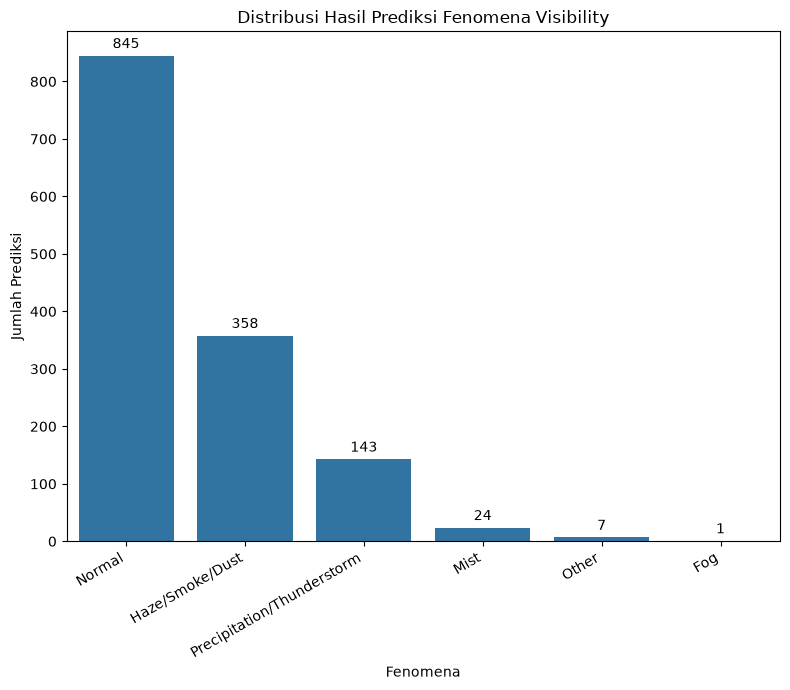

In [207]:
prediction_labels = (
    external_clean['predicted_phenomenon']
    .map({v: k for k, v in label_map.items()})
)

plt.figure(figsize=(8, 7))

ax = sns.countplot(
    x=prediction_labels,
    order=prediction_labels.value_counts().index
)

plt.title('Distribusi Hasil Prediksi Fenomena Visibility')
plt.xlabel('Fenomena')
plt.ylabel('Jumlah Prediksi')
plt.xticks(rotation=30, ha='right')

for container in ax.containers:
    ax.bar_label(container, padding=3)

plt.tight_layout()
plt.show()

## 13.7 Evaluasi Performa pada Data Eksternal

Mengevaluasi ketepatan prediksi model utama **XGBoost** pada **`4.344` observasi eksternal (Januari–Juni 2026)** terhadap label aktual `y_external`. Evaluasi mencakup perbandingan metrik keseluruhan (*Accuracy*, *Macro F1-Score*, dan *Balanced Accuracy*) terhadap performa pada data uji internal (*Internal Test Set*), laporan klasifikasi per kelas (*Classification Report*), serta matriks kebingungan (*Confusion Matrix*) untuk seluruh **7 kelas fenomena**.

In [289]:
n_classes = len(label_map)
class_labels = list(range(n_classes))
class_names = [inv_label_map[i] for i in range(n_classes)]

In [290]:
ext_acc = accuracy_score(y_external, ext_pred)
ext_macro_f1 = f1_score(y_external, ext_pred, labels=class_labels, average='macro', zero_division=0)
ext_bal_acc = balanced_accuracy_score(y_external, ext_pred)

In [291]:
y_pred_xgb_test = test_predictions['XGBoost']
int_acc = accuracy_score(y_test, y_pred_xgb_test)
int_macro_f1 = f1_score(y_test, y_pred_xgb_test, labels=class_labels, average='macro', zero_division=0)
int_bal_acc = balanced_accuracy_score(y_test, y_pred_xgb_test)

In [292]:
ext_summary_df = pd.DataFrame([
    {
        'Dataset': 'Internal Test Set (2025, n=1.752)',
        'Accuracy': int_acc,
        'Macro F1': int_macro_f1,
        'Balanced Accuracy': int_bal_acc
    },
    {
        'Dataset': 'External Validation (Jan–Jun 2026, n=4.344)',
        'Accuracy': ext_acc,
        'Macro F1': ext_macro_f1,
        'Balanced Accuracy': ext_bal_acc
    }
]).set_index('Dataset')

In [293]:
display(ext_summary_df.round(4))

,Accuracy,Macro F1,Balanced Accuracy
Dataset,,,
"Internal Test Set (2025, n=1.752)",0.7392,0.5710,0.6367
"External Validation (Jan–Jun 2026, n=4.344)",0.7270,0.5766,0.6484


**Classification Report**

In [294]:
print(classification_report(
    y_external,
    ext_pred,
    labels=class_labels,
    target_names=class_names,
    zero_division=0,
    digits=4
))

                              precision    recall  f1-score   support

        Active Precipitation     0.6443    0.5963    0.6194       322
                         Fog     0.7500    0.9600    0.8421        25
             Haze/Smoke/Dust     0.5583    0.8034    0.6588       763
                        Mist     0.5461    0.8605    0.6682       172
                      Normal     0.9556    0.7438    0.8365      2806
                       Other     0.1053    0.1176    0.1111        68
Recent/Distant Precipitation     0.2234    0.4574    0.3002       188

                    accuracy                         0.7270      4344
                   macro avg     0.5404    0.6484    0.5766      4344
                weighted avg     0.8003    0.7270    0.7480      4344



**Confusion Matrix**

In [295]:
cm_ext = confusion_matrix(
    y_external,
    ext_pred,
    labels=class_labels
)

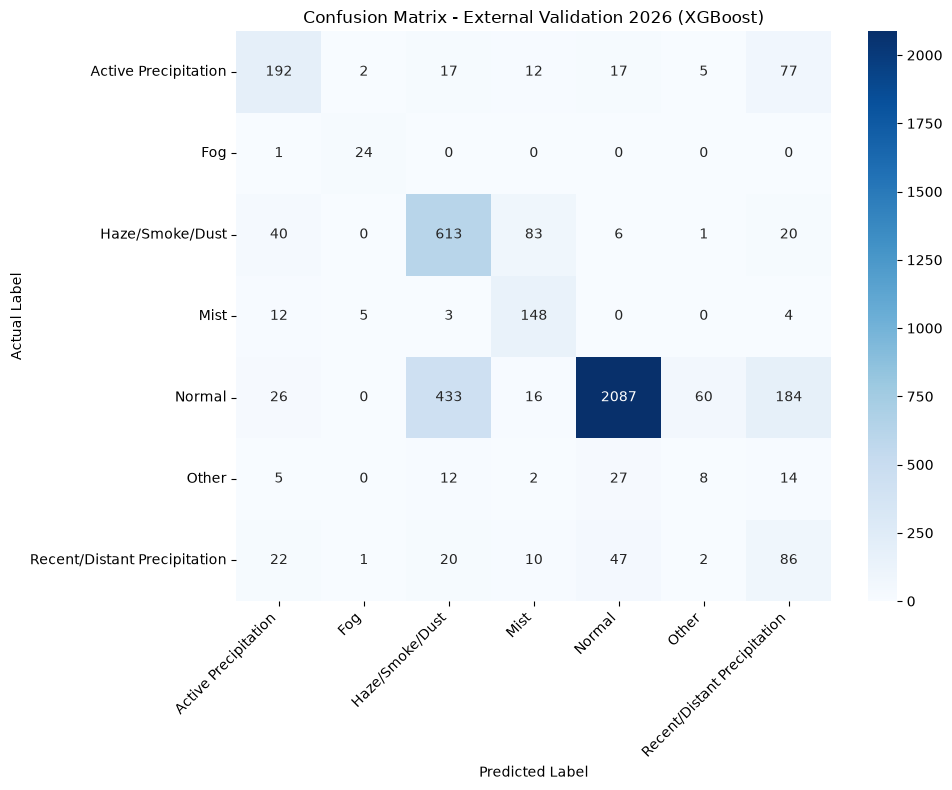

In [296]:
plt.figure(figsize=(10, 8))
sns.heatmap(
    cm_ext,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)
plt.title('Confusion Matrix - External Validation 2026 (XGBoost)')
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [297]:
cm_ext_df = pd.DataFrame(
    cm_ext,
    index=class_names,
    columns=class_names
)
cm_ext_df.index.name = 'Actual'
cm_ext_df.columns.name = 'Predicted'
display(cm_ext_df)

Predicted,Active Precipitation,Fog,Haze/Smoke/Dust,Mist,Normal,Other,Recent/Distant Precipitation
Actual,,,,,,,
Active Precipitation,192,2,17,12,17,5,77
Fog,1,24,0,0,0,0,0
Haze/Smoke/Dust,40,0,613,83,6,1,20
Mist,12,5,3,148,0,0,4
Normal,26,0,433,16,2087,60,184
Other,5,0,12,2,27,8,14
Recent/Distant Precipitation,22,1,20,10,47,2,86


**Notes:**

- **Stabilitas generalisasi lintas tahun (2025 ke 2026):** Model utama **XGBoost** menunjukkan kemampuan generalisasi yang konsisten pada data eksternal periode Januari–Juni 2026 (`4.344` observasi) tanpa pelatihan ulang, dengan perolehan **Macro F1-Score sebesar `0,5766`** (sedikit lebih tinggi **`+0,0056`** dibandingkan uji internal tahun 2025 sebesar `0,5710`) dan **Balanced Accuracy sebesar `0,6484`** (naik **`+0,0117`** dari `0,6367`), sementara *Accuracy* berada di angka **`0,7270`** (`3.158` prediksi tepat dari `4.344` observasi).
- **Kinerja kuat pada kelas minoritas dan fenomena utama:**
  - **`Fog` (`25` sampel):** Model mengenali **`24` dari `25` kejadian kabut** dengan tepat (*recall* **`0,9600`**, *precision* `0,7500`, *F1-Score* **`0,8421`**), dan hanya `1` sampel yang bergeser ke `Active Precipitation`.
  - **`Normal` (`2.806` sampel):** Memperoleh *precision* sangat tinggi sebesar **`0,9556`** (*recall* `0,7438`, *F1-Score* **`0,8365`**), menandakan bahwa ketika model memprediksi kondisi `Normal`, tingkat keyakinannya sangat tinggi (`2.087` benar dari `2.184` total prediksi `Normal`).
  - **`Mist` (`172` sampel), `Haze/Smoke/Dust` (`763` sampel), dan `Active Precipitation` (`322` sampel):** Ketiganya mempertahankan *F1-Score* yang solid di kisaran **`0,6194–0,6682`** dengan sensitivitas deteksi (*recall*) masing-masing sebesar `0,8605`, `0,8034`, dan `0,5963`.
- **Pola kesalahan klasifikasi utama pada *Confusion Matrix*:**
  - Kesalahan terbesar terjadi pada observasi aktual **`Normal` yang terprediksi sebagai `Haze/Smoke/Dust` (`433` observasi)** serta **`Recent/Distant Precipitation` (`184` observasi)** dan **`Other` (`60` observasi)**.
  - Pada kelompok hujan, **`77` dari `322` observasi `Active Precipitation`** terprediksi sebagai `Recent/Distant Precipitation`, yang mencerminkan kedekatan karakteristik fisik antara hujan aktif di stasiun dan hujan yang baru berlalu atau berada di sekitar stasiun.
  - Kelas **`Other` (`68` sampel)** tetap menjadi kategori paling sulit dipisahkan (*F1-Score* `0,1111`, `8` benar) karena mencakup beragam fenomena cuaca khusus yang tidak memiliki pola tunggal.

## 13.8 Misclassification Analysis

Menganalisis kasus kesalahan klasifikasi (*misclassification*) pada data eksternal (Januari–Juni 2026) untuk mengidentifikasi pasangan kelas yang paling sering tertukar serta membandingkan karakteristik parameter meteorologi antara observasi yang terklasifikasi dengan tepat dan yang mengalami kesalahan prediksi.

**Filter seluruh observasi eksternal yang salah diprediksi**

In [298]:
misclassified = ext_clean[
    ext_clean['phenomenon_encoded'] != ext_clean['predicted_code']
].copy()

In [300]:
total_obs = len(ext_clean)
total_err = len(misclassified)
print(f"Total observasi eksternal : {total_obs}")
print(f"Jumlah prediksi tepat     : {total_obs - total_err} ({(total_obs - total_err) / total_obs * 100:.2f}%)")
print(f"Jumlah prediksi salah     : {total_err} ({total_err / total_obs * 100:.2f}%)")

Total observasi eksternal : 4344
Jumlah prediksi tepat     : 3158 (72.70%)
Jumlah prediksi salah     : 1186 (27.30%)


In [301]:
display(
    misclassified[[
        'datetime_wib', 'phenomenon', 'predicted_phenomenon',
        'visibility_vv', 'relative_humidity_pc', 'cloud_low_cover_oktas'
    ]].head(15)
)

,datetime_wib,phenomenon,predicted_phenomenon,visibility_vv,relative_humidity_pc,cloud_low_cover_oktas
1,2026-01-01 08:00:00,Mist,Active Precipitation,5.0,96.0,4
2,2026-01-01 09:00:00,Normal,Recent/Distant Precipitation,10.0,90.0,4
12,2026-01-01 19:00:00,Normal,Other,9.0,81.0,3
15,2026-01-01 22:00:00,Haze/Smoke/Dust,Recent/Distant Precipitation,7.0,88.0,5
23,2026-01-02 06:00:00,Active Precipitation,Mist,3.0,97.0,5
30,2026-01-02 13:00:00,Normal,Recent/Distant Precipitation,10.0,85.0,4
31,2026-01-02 14:00:00,Normal,Recent/Distant Precipitation,10.0,82.0,5
32,2026-01-02 15:00:00,Normal,Recent/Distant Precipitation,10.0,82.0,5
33,2026-01-02 16:00:00,Normal,Recent/Distant Precipitation,10.0,81.0,4
34,2026-01-02 17:00:00,Normal,Recent/Distant Precipitation,10.0,81.0,5


**Rekap pasangan kesalahan klasifikasi terbanyak**

In [302]:
error_distribution = (
    misclassified
    .groupby(['phenomenon', 'predicted_phenomenon'])
    .size()
    .reset_index(name='Count')
    .sort_values('Count', ascending=False)
    .reset_index(drop=True)
)
error_distribution['Share of Errors (%)'] = (error_distribution['Count'] / total_err * 100).round(2)

display(error_distribution.head(15))

,phenomenon,predicted_phenomenon,Count,Share of Errors (%)
0,Normal,Haze/Smoke/Dust,433,36.51
1,Normal,Recent/Distant Precipitation,184,15.51
2,Haze/Smoke/Dust,Mist,83,7.00
3,Active Precipitation,Recent/Distant Precipitation,77,6.49
4,Normal,Other,60,5.06
5,Recent/Distant Precipitation,Normal,47,3.96
6,Haze/Smoke/Dust,Active Precipitation,40,3.37
7,Other,Normal,27,2.28
8,Normal,Active Precipitation,26,2.19
9,Recent/Distant Precipitation,Active Precipitation,22,1.85


**Visualisasi 10 pasangan kesalahan terbanyak**

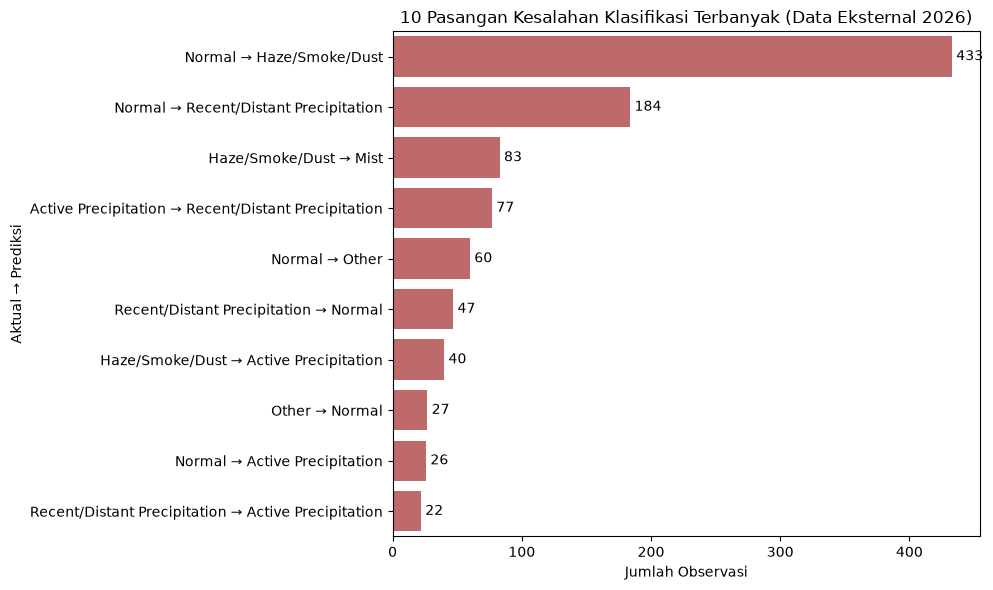

In [303]:
plt.figure(figsize=(10, 6))
top_errors = error_distribution.head(10).copy()
top_errors['Error Pair'] = top_errors['phenomenon'] + ' → ' + top_errors['predicted_phenomenon']

ax = sns.barplot(
    data=top_errors,
    x='Count',
    y='Error Pair',
    color='indianred'
)
plt.title('10 Pasangan Kesalahan Klasifikasi Terbanyak (Data Eksternal 2026)')
plt.xlabel('Jumlah Observasi')
plt.ylabel('Aktual → Prediksi')

for container in ax.containers:
    ax.bar_label(container, padding=3)

plt.tight_layout()
plt.show()

**Karakteristik Meteorologi Kesalahan & Perbandingan Normal vs Haze/Smoke/Dust**

In [305]:
analysis_features = [
    'wind_dir_deg_dd',
    'wind_speed_ff',
    'pressure_qff_mb_derived',
    'temp_drybulb_c_tttttt',
    'temp_dewpoint_c_tdtdtd',
    'relative_humidity_pc',
    'cloud_low_cover_oktas',
    'cloud_med_cover_oktas',
    'visibility_vv'
]

In [306]:
top_pairs_idx = error_distribution.head(10)[['phenomenon', 'predicted_phenomenon']]
error_characteristics = (
    misclassified
    .merge(top_pairs_idx, on=['phenomenon', 'predicted_phenomenon'])
    .groupby(['phenomenon', 'predicted_phenomenon'])[analysis_features]
    .mean()
    .round(2)
)
error_characteristics.index.names = ['Actual', 'Predicted']

In [307]:
print("=== Rata-rata Parameter Meteorologi pada 10 Pasangan Kesalahan Terbanyak ===")
display(error_characteristics)

=== Rata-rata Parameter Meteorologi pada 10 Pasangan Kesalahan Terbanyak ===


wind_dir_deg_dd  \
Actual                       Predicted                                       
Active Precipitation         Recent/Distant Precipitation           171.64   
Haze/Smoke/Dust              Active Precipitation                   221.75   
                             Mist                                   164.29   
Normal                       Active Precipitation                   263.69   
                             Haze/Smoke/Dust                        163.05   
                             Other                                   90.72   
                             Recent/Distant Precipitation           199.47   
Other                        Normal                                 158.15   
Recent/Distant Precipitation Active Precipitation                   219.77   
                             Normal                                 214.83   

                                                           wind_speed_ff  \
Actual                       Predicted                                     
Active Precipitation         Recent/Distant Precipitation           3.22   
Haze/Smoke/Dust              Active Precipitation                   2.98   
                             Mist                                   1.93   
Normal                       Active Precipitation                   5.23   
                             Haze/Smoke/Dust                        2.55   
                             Other                                  2.60   
                             Recent/Distant Precipitation           3.37   
Other                        Normal                                 3.93   
Recent/Distant Precipitation Active Precipitation                   3.64   
                             Normal                                 3.96   

                                                           pressure_qff_mb_derived  \
Actual                       Predicted                                               
Active Precipitation         Recent/Distant Precipitation                  1009.09   
Haze/Smoke/Dust              Active Precipitation                          1010.82   
                             Mist                                          1010.20   
Normal                       Active Precipitation                          1011.08   
                             Haze/Smoke/Dust                               1010.37   
                             Other                                         1008.56   
                             Recent/Distant Precipitation                  1009.23   
Other                        Normal                                        1009.20   
Recent/Distant Precipitation Active Precipitation                          1010.07   
                             Normal                                        1009.54   

                                                           temp_drybulb_c_tttttt  \
Actual                       Predicted                                             
Active Precipitation         Recent/Distant Precipitation                  26.26   
Haze/Smoke/Dust              Active Precipitation                          24.94   
                             Mist                                          24.84   
Normal                       Active Precipitation                          24.45   
                             Haze/Smoke/Dust                               26.67   
                             Other                                         28.08   
                             Recent/Distant Precipitation                  26.32   
Other                        Normal                                        28.38   
Recent/Distant Precipitation Active Precipitation                          25.05   
                             Normal                                        28.95   

                                                           temp_dewpoint_c_tdtdtd  \
Actual                       Predicted                                            

**Perbandingan mendalam kesalahan terbesar:**

**Normal (Benar) vs Normal (Salah diprediksi Haze/Smoke/Dust)**

In [308]:
normal_correct = ext_clean[
    (ext_clean['phenomenon'] == 'Normal') &
    (ext_clean['predicted_phenomenon'] == 'Normal')
]

In [309]:
normal_as_haze = ext_clean[
    (ext_clean['phenomenon'] == 'Normal') &
    (ext_clean['predicted_phenomenon'] == 'Haze/Smoke/Dust')
]

In [310]:
comparison_normal_df = pd.DataFrame({
    f'Normal - Correct (n={len(normal_correct)})': normal_correct[analysis_features].mean(),
    f'Normal - Predicted as Haze (n={len(normal_as_haze)})': normal_as_haze[analysis_features].mean()
}).round(2)

print("\n=== Perbandingan Karakteristik: Normal (Benar) vs Normal (Terprediksi Haze/Smoke/Dust) ===")
display(comparison_normal_df)


=== Perbandingan Karakteristik: Normal (Benar) vs Normal (Terprediksi Haze/Smoke/Dust) ===


,Normal - Correct (n=2087),Normal - Predicted as Haze (n=433)
wind_dir_deg_dd,173.65,163.05
wind_speed_ff,4.24,2.55
pressure_qff_mb_derived,1009.84,1010.37
temp_drybulb_c_tttttt,29.11,26.67
temp_dewpoint_c_tdtdtd,23.83,24.21
relative_humidity_pc,74.12,86.70
cloud_low_cover_oktas,3.20,2.48
cloud_med_cover_oktas,4.19,4.76
visibility_vv,9.95,7.05


**Boxplot 4 parameter utama pembeda**

In [311]:
normal_subset = ext_clean[
    (ext_clean['phenomenon'] == 'Normal') &
    (ext_clean['predicted_phenomenon'].isin(['Normal', 'Haze/Smoke/Dust']))
].copy()

In [312]:
normal_subset['Status Prediksi'] = normal_subset['predicted_phenomenon'].map({
    'Normal': 'Correct (Normal)',
    'Haze/Smoke/Dust': 'Misclassified as Haze/Smoke/Dust'
})

In [313]:
plot_features = [
    'visibility_vv',
    'relative_humidity_pc',
    'temp_drybulb_c_tttttt',
    'wind_speed_ff'
]

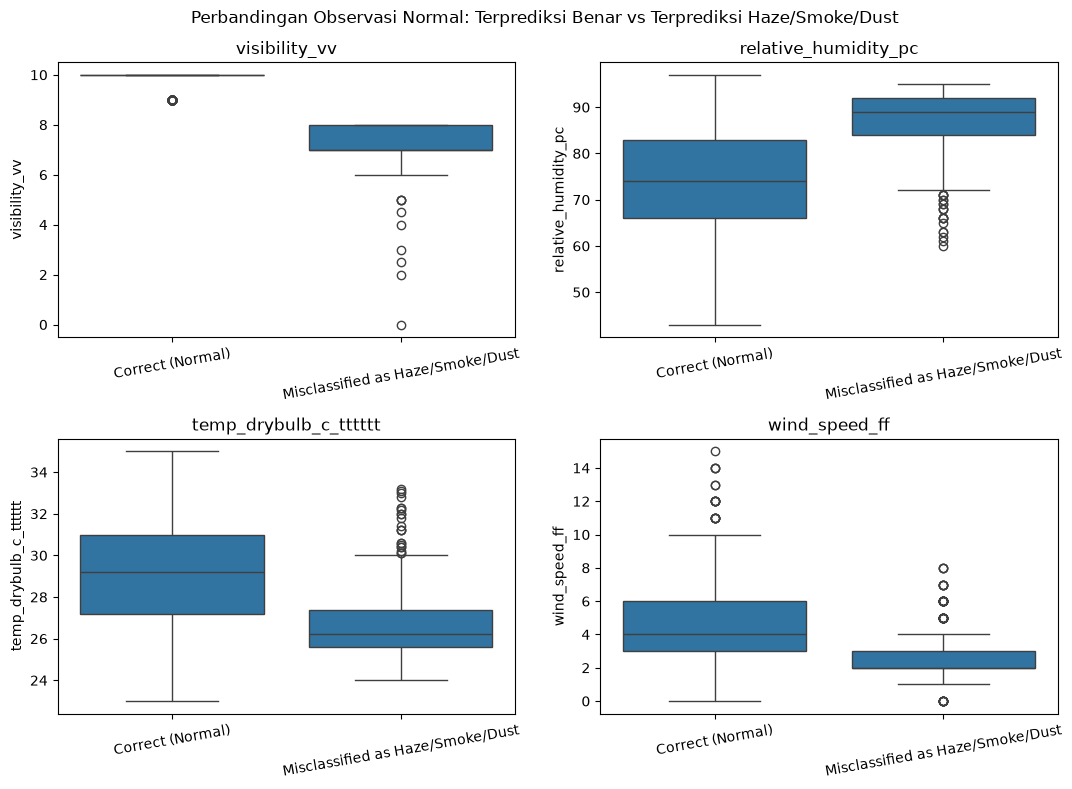

In [314]:
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for ax, feat in zip(axes.flat, plot_features):
    sns.boxplot(
        data=normal_subset,
        x='Status Prediksi',
        y=feat,
        ax=ax
    )
    ax.set_title(feat)
    ax.set_xlabel('')
    ax.tick_params(axis='x', rotation=10)

plt.suptitle('Perbandingan Observasi Normal: Terprediksi Benar vs Terprediksi Haze/Smoke/Dust', fontsize=12)
plt.tight_layout()
plt.show()

**Perbandingan 3 Profil (Normal Benar vs Normal → Haze vs Haze Benar)**

In [315]:
haze_correct = ext_clean[
    (ext_clean['phenomenon'] == 'Haze/Smoke/Dust') &
    (ext_clean['predicted_phenomenon'] == 'Haze/Smoke/Dust')
]

comparison_3way_df = pd.DataFrame({
    f'Normal - Correct (n={len(normal_correct)})': normal_correct[analysis_features].mean(),
    f'Normal → Haze (n={len(normal_as_haze)})': normal_as_haze[analysis_features].mean(),
    f'Haze/Smoke/Dust - Correct (n={len(haze_correct)})': haze_correct[analysis_features].mean()
}).round(2)

display(comparison_3way_df)

,Normal - Correct (n=2087),Normal → Haze (n=433),Haze/Smoke/Dust - Correct (n=613)
wind_dir_deg_dd,173.65,163.05,156.59
wind_speed_ff,4.24,2.55,1.91
pressure_qff_mb_derived,1009.84,1010.37,1010.32
temp_drybulb_c_tttttt,29.11,26.67,26.11
temp_dewpoint_c_tdtdtd,23.83,24.21,24.32
relative_humidity_pc,74.12,86.70,90.11
cloud_low_cover_oktas,3.20,2.48,2.60
cloud_med_cover_oktas,4.19,4.76,4.71
visibility_vv,9.95,7.05,4.68


**4 pasangan kesalahan terbanyak dari error_distribution**

In [316]:
top_4_pairs = list(
    error_distribution.head(4)[['phenomenon', 'predicted_phenomenon']].itertuples(index=False, name=None)
)

In [317]:
plot_features = [
    'visibility_vv',
    'relative_humidity_pc',
    'temp_drybulb_c_tttttt',
    'cloud_low_cover_oktas'
]

In [319]:
for rank, (actual_cls, pred_cls) in enumerate(top_4_pairs, start=1):
    # 1. Data kelas aktual yang terprediksi benar
    df_actual_correct = ext_clean[
        (ext_clean['phenomenon'] == actual_cls) &
        (ext_clean['predicted_phenomenon'] == actual_cls)
    ].copy()
    df_actual_correct['Group'] = f'Actual Correct\n({actual_cls})'

    # 2. Data kelas aktual yang salah terprediksi sebagai pred_cls
    df_misclassified = ext_clean[
        (ext_clean['phenomenon'] == actual_cls) &
        (ext_clean['predicted_phenomenon'] == pred_cls)
    ].copy()
    df_misclassified['Group'] = f'Misclassified\n({actual_cls} → {pred_cls})'

    # 3. Data kelas prediksi yang terprediksi benar
    df_pred_correct = ext_clean[
        (ext_clean['phenomenon'] == pred_cls) &
        (ext_clean['predicted_phenomenon'] == pred_cls)
    ].copy()
    df_pred_correct['Group'] = f'Predicted Correct\n({pred_cls})'

    print("=" * 80)
    print(f"#{rank} Pasangan Kesalahan: {actual_cls} → {pred_cls} (n = {len(df_misclassified)})")
    print("=" * 80)

    # Tabel perbandingan rata-rata parameter meteorologi 3 kelompok
    comp_3way = pd.DataFrame({
        f'{actual_cls} - Correct (n={len(df_actual_correct)})': df_actual_correct[analysis_features].mean(),
        f'{actual_cls} → {pred_cls} (n={len(df_misclassified)})': df_misclassified[analysis_features].mean(),
        f'{pred_cls} - Correct (n={len(df_pred_correct)})': df_pred_correct[analysis_features].mean()
    }).round(2)

    display(comp_3way)

#1 Pasangan Kesalahan: Normal → Haze/Smoke/Dust (n = 433)


,Normal - Correct (n=2087),Normal → Haze/Smoke/Dust (n=433),Haze/Smoke/Dust - Correct (n=613)
wind_dir_deg_dd,173.65,163.05,156.59
wind_speed_ff,4.24,2.55,1.91
pressure_qff_mb_derived,1009.84,1010.37,1010.32
temp_drybulb_c_tttttt,29.11,26.67,26.11
temp_dewpoint_c_tdtdtd,23.83,24.21,24.32
relative_humidity_pc,74.12,86.70,90.11
cloud_low_cover_oktas,3.20,2.48,2.60
cloud_med_cover_oktas,4.19,4.76,4.71
visibility_vv,9.95,7.05,4.68


#2 Pasangan Kesalahan: Normal → Recent/Distant Precipitation (n = 184)


,Normal - Correct (n=2087),Normal → Recent/Distant Precipitation (n=184),Recent/Distant Precipitation - Correct (n=86)
wind_dir_deg_dd,173.65,199.47,198.91
wind_speed_ff,4.24,3.37,3.22
pressure_qff_mb_derived,1009.84,1009.23,1009.18
temp_drybulb_c_tttttt,29.11,26.32,26.45
temp_dewpoint_c_tdtdtd,23.83,24.12,24.40
relative_humidity_pc,74.12,88.14,88.92
cloud_low_cover_oktas,3.20,4.23,4.43
cloud_med_cover_oktas,4.19,6.62,6.64
visibility_vv,9.95,9.52,9.29


#3 Pasangan Kesalahan: Haze/Smoke/Dust → Mist (n = 83)


,Haze/Smoke/Dust - Correct (n=613),Haze/Smoke/Dust → Mist (n=83),Mist - Correct (n=148)
wind_dir_deg_dd,156.59,164.29,183.64
wind_speed_ff,1.91,1.93,1.93
pressure_qff_mb_derived,1010.32,1010.20,1009.72
temp_drybulb_c_tttttt,26.11,24.84,24.95
temp_dewpoint_c_tdtdtd,24.32,24.12,24.32
relative_humidity_pc,90.11,95.70,96.23
cloud_low_cover_oktas,2.60,2.92,2.66
cloud_med_cover_oktas,4.71,4.25,5.64
visibility_vv,4.68,3.86,2.69


#4 Pasangan Kesalahan: Active Precipitation → Recent/Distant Precipitation (n = 77)


,Active Precipitation - Correct (n=192),Active Precipitation → Recent/Distant Precipitation (n=77),Recent/Distant Precipitation - Correct (n=86)
wind_dir_deg_dd,205.14,171.64,198.91
wind_speed_ff,4.47,3.22,3.22
pressure_qff_mb_derived,1010.56,1009.09,1009.18
temp_drybulb_c_tttttt,24.88,26.26,26.45
temp_dewpoint_c_tdtdtd,23.65,24.32,24.40
relative_humidity_pc,93.12,89.42,88.92
cloud_low_cover_oktas,5.33,4.77,4.43
cloud_med_cover_oktas,7.15,6.86,6.64
visibility_vv,4.85,8.23,9.29


**Notes:**

- Dari total **`4.344` observasi eksternal**, model utama **XGBoost** mengklasifikasikan **`3.158` observasi (`72,70%`)** secara tepat dan menghasilkan **`1.186` kesalahan prediksi (`27,30%`)**. Sebanyak **`65,51%` (`777` kasus)** dari seluruh kesalahan terpusat pada empat pasangan fenomena berikut:
  1. **`Normal` terprediksi sebagai `Haze/Smoke/Dust` (`433` observasi / `36,51%`):** Rata-rata parameter observasi `Normal` yang salah terprediksi berada tepat di zona transisi antara profil `Normal` benar dan `Haze/Smoke/Dust` benar—yakni jarak pandang menurun dari **`9,95 km`** menjadi **`7,05 km`** (mendekati `4,68 km`), kelembapan relatif naik dari **`74,12%`** menjadi **`86,70%`** (mendekati `90,11%`), suhu udara turun dari **`29,11 °C`** menjadi **`26,67 °C`** (mendekati `26,11 °C`), serta kecepatan angin melemah dari **`4,24 knot`** menjadi **`2,55 knot`** (mendekati `1,91 knot`).
  2. **`Normal` terprediksi sebagai `Recent/Distant Precipitation` (`184` observasi / `15,51%`):** Profil rata-rata kelompok salah prediksi ini hampir identik dengan profil aktual `Recent/Distant Precipitation - Correct`, terutama pada kelembapan relatif (**`88,14%`** vs `88,92%`, jauh di atas `Normal` benar `74,12%`), tutupan awan menengah (**`6,62` oktas** vs `6,64` oktas), tutupan awan rendah (**`4,23` oktas** vs `4,43` oktas), suhu udara (**`26,32 °C`** vs `26,45 °C`), serta jarak pandang yang tetap tinggi (**`9,52 km`** vs `9,29 km`). Kondisi ini mencerminkan situasi berawan tebal dan lembap sebelum atau sesudah hujan di sekitar stasiun tanpa hujan tercatat di lokasi pengamatan.
  3. **`Haze/Smoke/Dust` terprediksi sebagai `Mist` (`83` observasi / `7,00%`):** Terjadi ketika kejadian `Haze/Smoke/Dust` berlangsung pada kondisi sangat lembap dengan rata-rata kelembapan relatif **`95,70%`** (hampir sama dengan `Mist - Correct` sebesar `96,23%`), suhu udara lebih sejuk (**`24,84 °C`** vs `24,95 °C`), angin lemah (**`1,93 knot`** vs `1,93 knot`), dan jarak pandang menurun ke **`3,86 km`** (mendekati rata-rata `Mist` sebesar `2,69 km`).
  4. **`Active Precipitation` terprediksi sebagai `Recent/Distant Precipitation` (`77` observasi / `6,49%`):** Terjadi pada hujan aktif berintensitas ringan di mana jarak pandang tidak turun drastis (rata-rata **`8,23 km`**, jauh di atas rata-rata hujan aktif pada umumnya sebesar `4,85 km` dan mendekati `Recent/Distant Precipitation - Correct` sebesar `9,29 km`), disertai kelembapan relatif (**`89,42%`** vs `88,92%`), suhu udara (**`26,26 °C`** vs `26,45 °C`), dan kecepatan angin (**`3,22 knot`** vs `3,22 knot`) yang sangat menyerupai hujan di kejauhan atau hujan yang baru reda.
- Secara keseluruhan, temuan ini menunjukkan bahwa mayoritas kesalahan prediksi bukan merupakan kesalahan acak, melainkan berasal dari **tumpang tindih karakteristik parameter meteorologi permukaan (*feature overlap*)** pada batas transisi antarfenomena cuaca.

# 14. Model Saving and Deployment Preparation

Tahap ini mempersiapkan model klasifikasi terpilih agar siap diintegrasikan ke dalam aplikasi *web*. Proses meliputi penyiapan objek model dan komponen pendukung, pembuatan fungsi transformasi fitur tunggal untuk data hasil *decoding* SYNOP, pengujian konsistensi fitur terhadap data uji, penyimpanan artefak model menggunakan `joblib`, serta pengujian pemuatan ulang model.

## 14.1 Preparing Model Components

Menyiapkan komponen inti yang dibutuhkan pada tahap inferensi, yaitu model **XGBoost hasil *hyperparameter tuning*** (`final_xgb.estimator_`), daftar **13 fitur masukan** sesuai urutan pelatihan (`selected_features`), serta kamus pemetaan **7 kelas fenomena** (`label_map` dan `inv_label_map`).

In [320]:
final_xgb = search_results['XGBoost'].best_estimator_
deploy_model = final_xgb.estimator_

In [321]:
selected_features = list(X_train.columns)

In [322]:
print("Model           :", type(deploy_model).__name__)
print("Jumlah fitur    :", len(selected_features))
print("Selected features:", selected_features)
print("Label mapping   :", label_map)

Model           : XGBClassifier
Jumlah fitur    : 13
Selected features: ['wind_speed_ff', 'wind_dir_sin', 'wind_dir_cos', 'is_calm', 'pressure_qff_mb_derived', 'temp_drybulb_c_tttttt', 'temp_dewpoint_c_tdtdtd', 'relative_humidity_pc', 'cloud_low_cover_oktas', 'cloud_med_cover_oktas', 'visibility_vv', 'hour_sin', 'hour_cos']
Label mapping   : {'Active Precipitation': 0, 'Fog': 1, 'Haze/Smoke/Dust': 2, 'Mist': 3, 'Normal': 4, 'Other': 5, 'Recent/Distant Precipitation': 6}


## 14.2 Building Feature Engineering Function

Membuat fungsi `build_features()` untuk mengolah satu baris data observasi hasil *decoding* sandi SYNOP menjadi **13 fitur numerik** yang dibutuhkan oleh model **XGBoost**. Fungsi ini memvalidasi kelengkapan parameter masukan, mengonversi waktu observasi dari UTC ke WIB (`Asia/Jakarta`), membentuk fitur siklikal waktu dan arah angin serta indikator angin tenang (`is_calm`), lalu menyusun urutan kolom tepat sama dengan `selected_features`.

In [323]:
def build_features(data, input_timezone='UTC'):
    """
    Mengolah satu baris data observasi hasil decoding SYNOP menjadi
    13 fitur sesuai urutan yang dibutuhkan model XGBoost.

    Parameters
    ----------
    data : pandas.Series atau dict
        Satu baris observasi meteorologi.
    input_timezone : str, default='UTC'
        Zona waktu timestamp input.

    Returns
    -------
    pandas.DataFrame
        DataFrame 1 baris dengan 13 fitur terurut sesuai selected_features.
    """
    data = pd.Series(data)

    # Konversi timestamp ke WIB (Asia/Jakarta)
    timestamp = pd.Timestamp(data['data_timestamp'])
    if timestamp.tzinfo is None:
        timestamp = timestamp.tz_localize(input_timezone)
    datetime_wib = timestamp.tz_convert('Asia/Jakarta')

    # Validasi keberadaan parameter mentah yang dibutuhkan
    required_columns = [
        'wind_speed_ff',
        'wind_dir_deg_dd',
        'pressure_qff_mb_derived',
        'temp_drybulb_c_tttttt',
        'temp_dewpoint_c_tdtdtd',
        'relative_humidity_pc',
        'cloud_low_cover_oktas',
        'cloud_med_cover_oktas',
        'visibility_vv'
    ]

    missing_columns = [col for col in required_columns if col not in data.index]
    if missing_columns:
        raise ValueError(f"Kolom belum tersedia: {missing_columns}")

    if data[required_columns].isna().any():
        raise ValueError("Data observasi belum lengkap. Periksa kembali parameter yang kosong.")

    # Ekstraksi jam lokal WIB dan pembentukan fitur turunan
    hour = datetime_wib.hour

    features = {
        'wind_speed_ff': float(data['wind_speed_ff']),
        'wind_dir_sin': float(np.sin(np.deg2rad(data['wind_dir_deg_dd']))),
        'wind_dir_cos': float(np.cos(np.deg2rad(data['wind_dir_deg_dd']))),
        'is_calm': int(float(data['wind_speed_ff']) == 0),
        'pressure_qff_mb_derived': float(data['pressure_qff_mb_derived']),
        'temp_drybulb_c_tttttt': float(data['temp_drybulb_c_tttttt']),
        'temp_dewpoint_c_tdtdtd': float(data['temp_dewpoint_c_tdtdtd']),
        'relative_humidity_pc': float(data['relative_humidity_pc']),
        'cloud_low_cover_oktas': int(data['cloud_low_cover_oktas']),
        'cloud_med_cover_oktas': int(data['cloud_med_cover_oktas']),
        'visibility_vv': float(data['visibility_vv']),
        'hour_sin': float(np.sin(2 * np.pi * hour / 24)),
        'hour_cos': float(np.cos(2 * np.pi * hour / 24))
    }

    feature_df = pd.DataFrame([features])[selected_features]
    return feature_df

## 14.3 Feature Consistency Testing

Menguji fungsi `build_features()` menggunakan satu sampel observasi dari data uji dan membandingkannya secara langsung dengan baris yang bersesuaian pada `X_test` untuk memastikan nama kolom, urutan fitur, serta presisi nilai numeriknya identik.

In [324]:
# Ambil satu sampel observasi dari data uji
source_test_df = test_df if 'test_df' in globals() else clean_df.loc[X_test.index]
sample = source_test_df.iloc[0]

# Bentuk fitur menggunakan fungsi deployment
sample_features = build_features(sample, input_timezone='UTC')

# Ambil baris fitur asli dari X_test sebagai pembanding
original_features = X_test.loc[[sample.name]]

print("Urutan fitur sesuai :", list(sample_features.columns) == list(original_features.columns))
print(
    "Nilai fitur sesuai  :",
    np.allclose(
        sample_features.to_numpy(dtype=float),
        original_features.to_numpy(dtype=float),
        rtol=1e-9,
        atol=1e-9
    )
)

comparison_features_df = pd.DataFrame({
    'Original (X_test)': original_features.iloc[0],
    'Generated (build_features)': sample_features.iloc[0]
})

display(comparison_features_df)

Urutan fitur sesuai : True
Nilai fitur sesuai  : True


,Original (X_test),Generated (build_features)
wind_speed_ff,0.0,0.0
wind_dir_sin,0.0,0.0
wind_dir_cos,1.0,1.0
is_calm,1.0,1.0
pressure_qff_mb_derived,1010.0,1010.0
temp_drybulb_c_tttttt,26.0,26.0
temp_dewpoint_c_tdtdtd,24.5,24.5
relative_humidity_pc,91.0,91.0
cloud_low_cover_oktas,3.0,3.0
cloud_med_cover_oktas,3.0,3.0


## 14.4 Saving Model and Supporting Components

Menyimpan model utama **XGBoost** (`deploy_model`) beserta daftar fitur (`selected_features`) dan pemetaan label (`label_map`, `inv_label_map`) ke dalam satu file artefak `model/visibility_xgb_model.pkl` menggunakan `joblib`.

In [325]:
os.makedirs('model', exist_ok=True)

In [326]:
model_components = {
    'model': deploy_model,
    'selected_features': selected_features,
    'label_map': label_map,
    'inv_label_map': inv_label_map
}

In [327]:
model_path = '../model/weather_phenomena_xgb_model.joblib'
joblib.dump(model_components, model_path)

print(f"Model dan komponen pendukung berhasil disimpan ke: {model_path}")

Model dan komponen pendukung berhasil disimpan ke: ../model/weather_phenomena_xgb_model.joblib


## 14.5 Testing Model Loading

Memuat kembali file `../model/weather_phenomena_xgb_model.pkl` menggunakan `joblib.load()` untuk memverifikasi bahwa objek model **XGBoost**, daftar **13 fitur**, serta kamus pemetaan **7 label fenomena** dapat terbaca dengan utuh dan konsisten sebelum digunakan pada tahap simulasi prediksi.

In [328]:
loaded_components = joblib.load('../model/weather_phenomena_xgb_model.joblib')

In [329]:
loaded_model = loaded_components['model']
loaded_features = loaded_components['selected_features']
loaded_label_map = loaded_components['label_map']
loaded_inv_label_map = loaded_components['inv_label_map']

In [330]:
print("Model               :", type(loaded_model).__name__)
print("Jumlah fitur        :", len(loaded_features))
print("Urutan fitur sesuai :", loaded_features == selected_features)
print("Label mapping sesuai:", loaded_label_map == label_map)

Model               : XGBClassifier
Jumlah fitur        : 13
Urutan fitur sesuai : True
Label mapping sesuai: True


# 15. Model Prediction Simulation

Tahap ini melakukan simulasi *end-to-end* penggunaan model utama **XGBoost** yang telah disimpan dan dimuat kembali untuk mengklasifikasikan fenomena *visibility* dari satu observasi meteorologi. Simulasi mencakup pembentukan 13 fitur menggunakan `build_features()`, prediksi kelas fenomena, pemeriksaan distribusi probabilitas pada seluruh **7 kelas**, serta verifikasi kesesuaiannya terhadap kelas aktual.

## 15.1 Simulating Model Prediction

Mengambil satu sampel observasi dari data uji, memprosesnya menggunakan fungsi `build_features()` untuk menghasilkan 13 fitur sesuai urutan pelatihan, lalu menjalankan prediksi kelas menggunakan `loaded_model`.

In [331]:
source_test_df = test_df if 'test_df' in globals() else clean_df.loc[X_test.index]
sample = source_test_df.iloc[0]

**Bentuk 13 fitur menggunakan fungsi deployment**

In [332]:
sample_features = build_features(sample, input_timezone='UTC')

**Prediksi kelas menggunakan model XGBoost yang telah dimuat ulang**

In [333]:
predicted_label = int(loaded_model.predict(sample_features)[0])
predicted_phenomenon = loaded_inv_label_map[predicted_label]

In [334]:
observation_time = (
    pd.Timestamp(sample['data_timestamp'])
    .tz_localize('UTC')
    .tz_convert('Asia/Jakarta')
)

In [335]:
print("Hasil Prediksi")
print("=" * 35)
print("Waktu Observasi     :", observation_time.strftime('%d-%m-%Y %H:%M WIB'))
print("Predicted Label     :", predicted_label)
print("Predicted Phenomenon:", predicted_phenomenon)

Hasil Prediksi
Waktu Observasi     : 02-01-2025 00:00 WIB
Predicted Label     : 2
Predicted Phenomenon: Haze/Smoke/Dust


## 15.2 Analyzing Prediction Probabilities

Menghitung probabilitas prediksi model **XGBoost** menggunakan metode `predict_proba()` untuk melihat tingkat keyakinan model terhadap masing-masing dari **7 kategori fenomena** pada observasi yang diuji.

In [336]:
prediction_probabilities = loaded_model.predict_proba(sample_features)[0]

In [337]:
probability_df = pd.DataFrame({
    'Phenomenon': [
        loaded_inv_label_map[int(cls_idx)]
        for cls_idx in loaded_model.classes_
    ],
    'Probability': prediction_probabilities
})

In [338]:
probability_df = (
    probability_df
    .sort_values(by='Probability', ascending=False)
    .reset_index(drop=True)
)
probability_df['Probability (%)'] = (probability_df['Probability'] * 100).round(2)

In [339]:
display(probability_df[['Phenomenon', 'Probability (%)']])

,Phenomenon,Probability (%)
0,Haze/Smoke/Dust,97.809998
1,Other,0.480000
2,Mist,0.440000
3,Active Precipitation,0.370000
4,Recent/Distant Precipitation,0.340000
5,Fog,0.310000
6,Normal,0.260000


## 15.3 Comparing Prediction with Actual Class

Membandingkan hasil klasifikasi model **XGBoost** dengan label fenomena aktual pada observasi yang sama untuk memverifikasi ketepatan keluaran alur prediksi.

In [340]:
actual_label = int(y_test.loc[sample.name])
actual_phenomenon = loaded_inv_label_map[actual_label]
prediction_correct = (predicted_label == actual_label)

In [341]:
print("Perbandingan Hasil Prediksi")
print("=" * 35)
print("Waktu Observasi :", observation_time.strftime('%d-%m-%Y %H:%M WIB'))
print("Kelas Aktual    :", actual_phenomenon)
print("Kelas Prediksi  :", predicted_phenomenon)
print("Hasil Klasifikasi:", "Benar" if prediction_correct else "Tidak Sesuai")

Perbandingan Hasil Prediksi
Waktu Observasi : 02-01-2025 00:00 WIB
Kelas Aktual    : Haze/Smoke/Dust
Kelas Prediksi  : Haze/Smoke/Dust
Hasil Klasifikasi: Benar


## 15.4 Summary of Prediction Simulation

Berdasarkan simulasi yang telah dilakukan, artefak model utama **XGBoost** (`../model/weather_phenomena_xgb_model.pkl`) yang dimuat kembali melalui `joblib.load()` berhasil menerima satu baris data observasi hasil pemrosesan fungsi `build_features()` (13 fitur terurut) dan menghasilkan prediksi kelas beserta distribusi probabilitas untuk seluruh **7 kategori fenomena**.

Pada sampel observasi tanggal **02-01-2025 pukul 00:00 WIB**, model memprediksi fenomena **`Haze/Smoke/Dust`** dengan tingkat keyakinan probabilitas sebesar **`97,81%`**, sementara enam kelas lainnya memperoleh probabilitas di bawah `0,50%` (`Other` `0,48%`, `Mist` `0,44%`, `Active Precipitation` `0,37%`, `Recent/Distant Precipitation` `0,34%`, `Fog` `0,31%`, dan `Normal` `0,26%`). Hasil prediksi tersebut sesuai dengan label aktualnya (**`Haze/Smoke/Dust`**).

Hal ini memverifikasi bahwa alur inferensi *end-to-end*—mulai dari konversi zona waktu ke WIB, pembentukan 13 fitur masukan, hingga pemanggilan model tersimpan—berjalan konsisten dan siap diintegrasikan ke dalam aplikasi *web*. Pengujian satu sampel ini berfungsi sebagai verifikasi teknis alur prediksi dan melengkapi evaluasi menyeluruh yang telah dilakukan pada data uji internal maupun validasi eksternal.